In [ ]:
# Cell 1

!pip -q install \
    "fsspec==2025.3.0" \
    "s3fs==2025.3.0" \
    netCDF4 \
    pyarrow \
    pyproj \
    duckdb

from google.colab import drive
from pathlib import Path

import pandas as pd
import shutil

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

driveRoot = Path(
    "/content/drive/MyDrive"
)

sourceAbiDir = (
    driveRoot
    / "Summer26"
    / "ABI"
)

sourceViirsDir = (
    driveRoot
    / "Summer26"
    / "VIIRS"
)

projectDir = (
    driveRoot
    / "LAI_ML"
)

revisedDir = (
    projectDir
    / "revised"
)

geometryDir = (
    revisedDir
    / "geometry"
)

brfDir = (
    revisedDir
    / "brf"
)

labelDir = (
    revisedDir
    / "labels"
)

trainingDir = (
    revisedDir
    / "training"
)

modelDir = (
    revisedDir
    / "models"
)

figureDir = (
    revisedDir
    / "figures"
)

tempDir = Path(
    "/content/LAI_ML_revised_temp"
)

for outputDir in [
    geometryDir,
    brfDir,
    labelDir,
    trainingDir,
    modelDir,
    figureDir
]:
    outputDir.mkdir(
        parents=True,
        exist_ok=True
    )

if tempDir.exists():
    shutil.rmtree(
        tempDir
    )

tempDir.mkdir(
    parents=True,
    exist_ok=True
)

candidateSitePath = (
    sourceAbiDir
    / "Training_sites_20km_sampling.txt"
)

navigationPath = (
    sourceAbiDir
    / "GOES_Navigation_2kmFD-GOES-East.nc"
)

existingAcceptedSitePath = (
    projectDir
    / "geometry"
    / "acceptable_training_sites_for_LAI_extraction.csv"
)

igbpPath = (
    sourceViirsDir
    / "S-NPP_VIIRS_GST_IGBP_8-Year_30arcsec.nc"
)

siteGeometryCsvPath = (
    geometryDir
    / "goes19_training_sites_geometry.csv"
)

siteGeometryParquetPath = (
    geometryDir
    / "goes19_training_sites_geometry.parquet"
)

mentorSiteCopyPath = (
    geometryDir
    / "goes19_training_sites_for_mentor.csv"
)

landMaskMetadataPath = (
    geometryDir
    / "goes19_land_mask_metadata.json"
)

rawBrfPartitionDir = (
    brfDir
    / "observation_partitions"
)

rawBrfPartitionDir.mkdir(
    parents=True,
    exist_ok=True
)

brfObservationPath = (
    brfDir
    / "goes19_brf_training_observations.parquet"
)

brfTrainingFeaturePath = (
    brfDir
    / "goes19_brf_training_features_8day_by_hour.parquet"
)

brfScanSummaryPath = (
    brfDir
    / "goes19_brf_scan_summary.csv"
)

brfCoverageSummaryPath = (
    brfDir
    / "goes19_brf_coverage_summary.csv"
)

brfDataDictionaryPath = (
    brfDir
    / "goes19_brf_data_dictionary.csv"
)

startDate = pd.Timestamp(
    "2025-04-07",
    tz="UTC"
)

endDate = pd.Timestamp(
    "2026-04-06",
    tz="UTC"
)

goes19OperationalTime = pd.Timestamp(
    "2025-04-07 15:10:00",
    tz="UTC"
)

targetHoursUtc = [
    15,
    18,
    21
]

maxSolarZenithDeg = 67.0
maxViewZenithDeg = 70.0
randomSeed = 42
expectedMentorSiteCount = 89091

requiredInputPaths = [
    candidateSitePath,
    navigationPath,
    existingAcceptedSitePath,
    igbpPath
]

missingInputPaths = [
    inputPath
    for inputPath
    in requiredInputPaths
    if not inputPath.exists()
]

if missingInputPaths:
    raise FileNotFoundError(
        "Missing required input files:\n"
        + "\n".join(
            str(
                inputPath
            )
            for inputPath
            in missingInputPaths
        )
    )

print(
    "Revised project folder:",
    revisedDir
)

print(
    "GOES-19 operational start:",
    goes19OperationalTime
)

print(
    "Training period:",
    startDate.date(),
    "through",
    endDate.date()
)

print(
    "Target UTC hours:",
    targetHoursUtc
)

print(
    "Expected mentor sites:",
    f"{expectedMentorSiteCount:,}"
)

print(
    "All required input files found."
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 31.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.3/87.3 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 44.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.3/14.3 MB 52.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 kB 4.7 MB/s eta 0:00:00
Mounted at /content/drive
Revised project folder: /content/drive/MyDrive/LAI_ML/revised
GOES-19 operational start: 2025-04-07 15:10:00+00:00
Training period: 2025-04-07 through 2026-04-06
Target UTC hours: [15, 18, 21]
Expected mentor sites: 89,091
All required input files found.


In [ ]:
# Cell 2

from pyproj import CRS, Transformer

import json
import netCDF4 as nc
import numpy as np
import pandas as pd
import s3fs


def findNearestIndices(
    sortedValues,
    targetValues
):
    sortedValues = np.asarray(
        sortedValues,
        dtype=float
    )

    targetValues = np.asarray(
        targetValues,
        dtype=float
    )

    if sortedValues[0] > sortedValues[-1]:
        reversedIndices = findNearestIndices(
            sortedValues[::-1],
            targetValues
        )

        return (
            len(sortedValues)
            - 1
            - reversedIndices
        )

    rightIndices = np.clip(
        np.searchsorted(
            sortedValues,
            targetValues
        ),
        0,
        len(sortedValues) - 1
    )

    leftIndices = np.clip(
        rightIndices - 1,
        0,
        len(sortedValues) - 1
    )

    useRight = (
        np.abs(
            targetValues
            - sortedValues[rightIndices]
        )
        < np.abs(
            targetValues
            - sortedValues[leftIndices]
        )
    )

    return np.where(
        useRight,
        rightIndices,
        leftIndices
    ).astype(
        np.int32
    )


def longitudeDifferenceDeg(
    longitudeA,
    longitudeB
):
    difference = np.abs(
        np.asarray(
            longitudeA,
            dtype=float
        )
        - np.asarray(
            longitudeB,
            dtype=float
        )
    )

    return np.minimum(
        difference,
        360.0 - difference
    )


def calculateViewGeometry(
    latitudeDeg,
    longitudeDeg,
    satelliteLongitudeDeg,
    semiMajorAxisM,
    semiMinorAxisM,
    perspectiveHeightM
):
    latitudeRad = np.radians(
        np.asarray(
            latitudeDeg,
            dtype=float
        )
    )

    longitudeRad = np.radians(
        np.asarray(
            longitudeDeg,
            dtype=float
        )
    )

    satelliteLongitudeRad = np.radians(
        float(
            satelliteLongitudeDeg
        )
    )

    eccentricitySquared = (
        1.0
        - (
            semiMinorAxisM ** 2
            / semiMajorAxisM ** 2
        )
    )

    primeVerticalRadius = (
        semiMajorAxisM
        / np.sqrt(
            1.0
            - eccentricitySquared
            * np.sin(
                latitudeRad
            ) ** 2
        )
    )

    siteX = (
        primeVerticalRadius
        * np.cos(
            latitudeRad
        )
        * np.cos(
            longitudeRad
        )
    )

    siteY = (
        primeVerticalRadius
        * np.cos(
            latitudeRad
        )
        * np.sin(
            longitudeRad
        )
    )

    siteZ = (
        primeVerticalRadius
        * (
            1.0
            - eccentricitySquared
        )
        * np.sin(
            latitudeRad
        )
    )

    satelliteDistanceM = (
        semiMajorAxisM
        + perspectiveHeightM
    )

    satelliteX = (
        satelliteDistanceM
        * np.cos(
            satelliteLongitudeRad
        )
    )

    satelliteY = (
        satelliteDistanceM
        * np.sin(
            satelliteLongitudeRad
        )
    )

    deltaX = (
        satelliteX
        - siteX
    )

    deltaY = (
        satelliteY
        - siteY
    )

    deltaZ = (
        -siteZ
    )

    eastComponent = (
        -np.sin(
            longitudeRad
        )
        * deltaX
        + np.cos(
            longitudeRad
        )
        * deltaY
    )

    northComponent = (
        -np.sin(
            latitudeRad
        )
        * np.cos(
            longitudeRad
        )
        * deltaX
        - np.sin(
            latitudeRad
        )
        * np.sin(
            longitudeRad
        )
        * deltaY
        + np.cos(
            latitudeRad
        )
        * deltaZ
    )

    upComponent = (
        np.cos(
            latitudeRad
        )
        * np.cos(
            longitudeRad
        )
        * deltaX
        + np.cos(
            latitudeRad
        )
        * np.sin(
            longitudeRad
        )
        * deltaY
        + np.sin(
            latitudeRad
        )
        * deltaZ
    )

    slantRangeM = np.sqrt(
        deltaX ** 2
        + deltaY ** 2
        + deltaZ ** 2
    )

    viewAzimuthDeg = (
        np.degrees(
            np.arctan2(
                eastComponent,
                northComponent
            )
        )
        + 360.0
    ) % 360.0

    viewZenithDeg = np.degrees(
        np.arccos(
            np.clip(
                upComponent
                / slantRangeM,
                -1.0,
                1.0
            )
        )
    )

    return (
        viewZenithDeg.astype(
            np.float32
        ),
        viewAzimuthDeg.astype(
            np.float32
        )
    )


candidateSites = pd.read_csv(
    candidateSitePath,
    sep=r"\s+",
    header=None,
    names=[
        "latitude",
        "longitude"
    ],
    dtype=np.float32
)

candidateSites.insert(
    0,
    "siteId",
    np.arange(
        len(candidateSites),
        dtype=np.int32
    )
)

acceptedSource = pd.read_csv(
    existingAcceptedSitePath
)

acceptedSource = acceptedSource.drop(
    columns=[
        column
        for column
        in acceptedSource.columns
        if (
            column.lower()
            == "index"
            or column.lower().startswith(
                "unnamed:"
            )
        )
    ],
    errors="ignore"
)

acceptedSource = acceptedSource.rename(
    columns={
        "site": "siteId",
        "lat": "latitude",
        "lon": "longitude"
    }
)

requiredAcceptedColumns = {
    "siteId",
    "latitude",
    "longitude"
}

missingAcceptedColumns = (
    requiredAcceptedColumns
    - set(
        acceptedSource.columns
    )
)

if missingAcceptedColumns:
    raise ValueError(
        "Accepted-site file is missing: "
        + ", ".join(
            sorted(
                missingAcceptedColumns
            )
        )
    )

acceptedSource = (
    acceptedSource[
        [
            "siteId",
            "latitude",
            "longitude"
        ]
    ]
    .copy()
)

acceptedSource[
    "siteId"
] = acceptedSource[
    "siteId"
].astype(
    np.int32
)

if acceptedSource[
    "siteId"
].duplicated().any():
    raise ValueError(
        "Accepted-site file contains duplicate site IDs."
    )

if len(
    acceptedSource
) != expectedMentorSiteCount:
    raise ValueError(
        "Expected "
        f"{expectedMentorSiteCount:,} mentor sites "
        "but found "
        f"{len(acceptedSource):,}."
    )

s3FileSystem = s3fs.S3FileSystem(
    anon=True,
    default_fill_cache=False
)

samplePrefix = (
    "noaa-goes19/"
    "ABI-L2-BRFF/"
    "2025/182/17/"
)

sampleKeys = sorted(
    s3FileSystem.glob(
        samplePrefix
        + "*.nc"
    )
)

if not sampleKeys:
    raise FileNotFoundError(
        "No sample GOES-19 BRFF file was found."
    )

sampleKey = sampleKeys[0]

sampleDownloadPath = (
    tempDir
    / Path(
        sampleKey
    ).name
)

sampleDownloadPath.unlink(
    missing_ok=True
)

s3FileSystem.get(
    sampleKey,
    str(
        sampleDownloadPath
    )
)

with nc.Dataset(
    sampleDownloadPath
) as sampleDataset:

    goesXCoordinates = np.asarray(
        sampleDataset[
            "x"
        ][:],
        dtype=float
    )

    goesYCoordinates = np.asarray(
        sampleDataset[
            "y"
        ][:],
        dtype=float
    )

    satelliteLongitudeDeg = float(
        sampleDataset[
            "nominal_satellite_subpoint_lon"
        ][...]
    )

    projectionAttributes = dict(
        sampleDataset[
            "goes_imager_projection"
        ].__dict__
    )

semiMajorAxisM = float(
    projectionAttributes[
        "semi_major_axis"
    ]
)

semiMinorAxisM = float(
    projectionAttributes[
        "semi_minor_axis"
    ]
)

perspectiveHeightM = float(
    projectionAttributes[
        "perspective_point_height"
    ]
)

projectionLongitudeDeg = float(
    projectionAttributes[
        "longitude_of_projection_origin"
    ]
)

sweepAxis = projectionAttributes.get(
    "sweep_angle_axis",
    "x"
)

goesCrs = CRS.from_proj4(
    f"+proj=geos "
    f"+h={perspectiveHeightM} "
    f"+lon_0={projectionLongitudeDeg} "
    f"+a={semiMajorAxisM} "
    f"+b={semiMinorAxisM} "
    f"+sweep={sweepAxis} "
    f"+units=m"
)

toGoesTransformer = (
    Transformer.from_crs(
        CRS.from_epsg(
            4326
        ),
        goesCrs,
        always_xy=True
    )
)

projectedX, projectedY = (
    toGoesTransformer.transform(
        candidateSites[
            "longitude"
        ].to_numpy(
            float
        ),
        candidateSites[
            "latitude"
        ].to_numpy(
            float
        )
    )
)

scanAngleX = (
    projectedX
    / perspectiveHeightM
)

scanAngleY = (
    projectedY
    / perspectiveHeightM
)

insideFixedGrid = (
    np.isfinite(
        scanAngleX
    )
    & np.isfinite(
        scanAngleY
    )
    & (
        scanAngleX
        >= goesXCoordinates.min()
    )
    & (
        scanAngleX
        <= goesXCoordinates.max()
    )
    & (
        scanAngleY
        >= goesYCoordinates.min()
    )
    & (
        scanAngleY
        <= goesYCoordinates.max()
    )
)

goesColumn = np.full(
    len(candidateSites),
    -1,
    dtype=np.int32
)

goesRow = np.full(
    len(candidateSites),
    -1,
    dtype=np.int32
)

goesColumn[
    insideFixedGrid
] = findNearestIndices(
    goesXCoordinates,
    scanAngleX[
        insideFixedGrid
    ]
)

goesRow[
    insideFixedGrid
] = findNearestIndices(
    goesYCoordinates,
    scanAngleY[
        insideFixedGrid
    ]
)

insideIndices = np.flatnonzero(
    insideFixedGrid
)

randomGenerator = (
    np.random.default_rng(
        randomSeed
    )
)

orientationCheckIndices = (
    randomGenerator.choice(
        insideIndices,
        size=min(
            2000,
            len(
                insideIndices
            )
        ),
        replace=False
    )
)

with nc.Dataset(
    navigationPath
) as navigationDataset:

    navigationLatitude = (
        np.ma.filled(
            navigationDataset[
                "Latitude"
            ][:],
            np.nan
        )
    )

    navigationLongitude = (
        np.ma.filled(
            navigationDataset[
                "Longitude"
            ][:],
            np.nan
        )
    )

    navigationViewZenith = (
        np.ma.filled(
            navigationDataset[
                "LocalZenithAngle"
            ][:],
            np.nan
        )
    )

    landMaskVariable = (
        navigationDataset[
            "LandMask"
        ]
    )

    navigationLandMask = (
        np.ma.filled(
            landMaskVariable[:],
            np.nan
        )
    )

    landMaskAttributes = {
        attributeName:
            getattr(
                landMaskVariable,
                attributeName
            )
        for attributeName
        in landMaskVariable.ncattrs()
    }

xyError = np.nanmedian(
    np.abs(
        candidateSites.loc[
            orientationCheckIndices,
            "latitude"
        ].to_numpy()
        - navigationLatitude[
            goesColumn[
                orientationCheckIndices
            ],
            goesRow[
                orientationCheckIndices
            ]
        ]
    )
    + longitudeDifferenceDeg(
        candidateSites.loc[
            orientationCheckIndices,
            "longitude"
        ].to_numpy(),
        navigationLongitude[
            goesColumn[
                orientationCheckIndices
            ],
            goesRow[
                orientationCheckIndices
            ]
        ]
    )
)

yxError = np.nanmedian(
    np.abs(
        candidateSites.loc[
            orientationCheckIndices,
            "latitude"
        ].to_numpy()
        - navigationLatitude[
            goesRow[
                orientationCheckIndices
            ],
            goesColumn[
                orientationCheckIndices
            ]
        ]
    )
    + longitudeDifferenceDeg(
        candidateSites.loc[
            orientationCheckIndices,
            "longitude"
        ].to_numpy(),
        navigationLongitude[
            goesRow[
                orientationCheckIndices
            ],
            goesColumn[
                orientationCheckIndices
            ]
        ]
    )
)

navigationUsesRowColumn = (
    yxError
    < xyError
)

goesLatitude = np.full(
    len(candidateSites),
    np.nan,
    dtype=np.float32
)

goesLongitude = np.full(
    len(candidateSites),
    np.nan,
    dtype=np.float32
)

viewZenithDeg = np.full(
    len(candidateSites),
    np.nan,
    dtype=np.float32
)

landMaskValue = np.full(
    len(candidateSites),
    np.nan,
    dtype=np.float32
)

if navigationUsesRowColumn:

    navigationRows = goesRow[
        insideIndices
    ]

    navigationColumns = goesColumn[
        insideIndices
    ]

else:

    navigationRows = goesColumn[
        insideIndices
    ]

    navigationColumns = goesRow[
        insideIndices
    ]

goesLatitude[
    insideIndices
] = navigationLatitude[
    navigationRows,
    navigationColumns
]

goesLongitude[
    insideIndices
] = navigationLongitude[
    navigationRows,
    navigationColumns
]

viewZenithDeg[
    insideIndices
] = navigationViewZenith[
    navigationRows,
    navigationColumns
]

landMaskValue[
    insideIndices
] = navigationLandMask[
    navigationRows,
    navigationColumns
]

calculatedViewZenithDeg = np.full(
    len(candidateSites),
    np.nan,
    dtype=np.float32
)

viewAzimuthDeg = np.full(
    len(candidateSites),
    np.nan,
    dtype=np.float32
)

(
    calculatedViewZenithDeg[
        insideIndices
    ],
    viewAzimuthDeg[
        insideIndices
    ]
) = calculateViewGeometry(
    goesLatitude[
        insideIndices
    ],
    goesLongitude[
        insideIndices
    ],
    satelliteLongitudeDeg,
    semiMajorAxisM,
    semiMinorAxisM,
    perspectiveHeightM
)

siteGeometry = (
    candidateSites.copy()
)

siteGeometry[
    "goesRow"
] = goesRow

siteGeometry[
    "goesColumn"
] = goesColumn

siteGeometry[
    "goesLatitude"
] = goesLatitude

siteGeometry[
    "goesLongitude"
] = goesLongitude

siteGeometry[
    "viewZenithDeg"
] = viewZenithDeg

siteGeometry[
    "viewAzimuthDeg"
] = viewAzimuthDeg

siteGeometry[
    "calculatedViewZenithDeg"
] = calculatedViewZenithDeg

siteGeometry[
    "landMaskValue"
] = landMaskValue

siteGeometry[
    "latitudeErrorDeg"
] = np.abs(
    siteGeometry[
        "latitude"
    ]
    - siteGeometry[
        "goesLatitude"
    ]
)

siteGeometry[
    "longitudeErrorDeg"
] = longitudeDifferenceDeg(
    siteGeometry[
        "longitude"
    ],
    siteGeometry[
        "goesLongitude"
    ]
)

siteGeometry[
    "geometryValid"
] = (
    insideFixedGrid
    & (
        siteGeometry[
            "latitudeErrorDeg"
        ]
        <= 0.2
    )
    & (
        siteGeometry[
            "longitudeErrorDeg"
        ]
        <= 0.2
    )
    & (
        siteGeometry[
            "viewZenithDeg"
        ]
        <= maxViewZenithDeg
    )
)

acceptedSiteIds = set(
    acceptedSource[
        "siteId"
    ].tolist()
)

siteGeometry = (
    siteGeometry.loc[
        siteGeometry[
            "siteId"
        ].isin(
            acceptedSiteIds
        )
    ]
    .sort_values(
        "siteId"
    )
    .reset_index(
        drop=True
    )
)

if len(
    siteGeometry
) != len(
    acceptedSource
):
    raise ValueError(
        "Rebuilt site table does not match the mentor site list."
    )

invalidGeometryCount = int(
    (
        ~siteGeometry[
            "geometryValid"
        ]
    ).sum()
)

if invalidGeometryCount:
    raise ValueError(
        f"{invalidGeometryCount:,} mentor sites failed "
        "the rebuilt geometry checks."
    )

coordinateCheck = (
    siteGeometry[
        [
            "siteId",
            "latitude",
            "longitude"
        ]
    ]
    .merge(
        acceptedSource,
        on="siteId",
        suffixes=(
            "Rebuilt",
            "Mentor"
        ),
        how="inner"
    )
)

maximumLatitudeDifference = float(
    np.nanmax(
        np.abs(
            coordinateCheck[
                "latitudeRebuilt"
            ]
            - coordinateCheck[
                "latitudeMentor"
            ]
        )
    )
)

maximumLongitudeDifference = float(
    np.nanmax(
        longitudeDifferenceDeg(
            coordinateCheck[
                "longitudeRebuilt"
            ],
            coordinateCheck[
                "longitudeMentor"
            ]
        )
    )
)

if (
    maximumLatitudeDifference
    > 1e-4
    or maximumLongitudeDifference
    > 1e-4
):
    raise ValueError(
        "Mentor site coordinates do not match "
        "the original candidate-site coordinates."
    )

viewZenithDifference = np.abs(
    siteGeometry[
        "viewZenithDeg"
    ]
    - siteGeometry[
        "calculatedViewZenithDeg"
    ]
)

medianViewZenithDifference = float(
    np.nanmedian(
        viewZenithDifference
    )
)

p95ViewZenithDifference = float(
    np.nanpercentile(
        viewZenithDifference,
        95
    )
)

siteGeometry.to_csv(
    siteGeometryCsvPath,
    index=False,
    float_format="%.6f"
)

siteGeometry.to_parquet(
    siteGeometryParquetPath,
    index=False
)

mentorSiteCopy = (
    siteGeometry[
        [
            "siteId",
            "latitude",
            "longitude"
        ]
    ]
    .copy()
)

mentorSiteCopy.to_csv(
    mentorSiteCopyPath,
    index=False,
    float_format="%.6f"
)

landMaskCounts = (
    siteGeometry[
        "landMaskValue"
    ]
    .value_counts(
        dropna=False
    )
    .sort_index()
)

landMaskMetadata = {
    "attributes": {
        key: (
            value.tolist()
            if isinstance(
                value,
                np.ndarray
            )
            else (
                value.item()
                if isinstance(
                    value,
                    np.generic
                )
                else str(
                    value
                )
            )
        )
        for key, value
        in landMaskAttributes.items()
    },
    "acceptedSiteValueCounts": {
        str(key): int(
            value
        )
        for key, value
        in landMaskCounts.items()
    }
}

landMaskMetadataPath.write_text(
    json.dumps(
        landMaskMetadata,
        indent=2
    ),
    encoding="utf-8"
)

sampleDownloadPath.unlink(
    missing_ok=True
)

print(
    "Candidate sites:",
    f"{len(candidateSites):,}"
)

print(
    "Mentor-matched sites:",
    f"{len(siteGeometry):,}"
)

print(
    "Navigation array order:",
    "[row, column]"
    if navigationUsesRowColumn
    else "[column, row]"
)

print(
    "Median navigation error:",
    f"{min(xyError, yxError):.6f} degrees"
)

print(
    "Median view-zenith check difference:",
    f"{medianViewZenithDifference:.4f} degrees"
)

print(
    "95th-percentile view-zenith check difference:",
    f"{p95ViewZenithDifference:.4f} degrees"
)

print(
    "\nLandMask attributes:"
)

for key, value in landMaskAttributes.items():
    print(
        f"{key}: {value}"
    )

print(
    "\nLandMask values among mentor sites:"
)

print(
    landMaskCounts.to_string()
)

print(
    "\nSaved site geometry:",
    siteGeometryParquetPath
)

print(
    "Saved clean mentor site copy:",
    mentorSiteCopyPath
)

Candidate sites: 362,589
Mentor-matched sites: 89,091
Navigation array order: [row, column]
Median navigation error: 0.013907 degrees
Median view-zenith check difference: 0.1359 degrees
95th-percentile view-zenith check difference: 0.2285 degrees

LandMask attributes:
_FillValue: -1
long_name: ABI fixed grid land-sea mask classification
valid_range: [0 7]
flag_meanings: shallow oceanlandocean coastlines and lake shorelinesshallow inland waterephemeral waterdeep inland watermoderate or continental oceandeep ocean
flag_values: [0 1 2 3 4 5 6 7]
units: 1

LandMask values among mentor sites:
landMaskValue
1.0    88866
2.0      225

Saved site geometry: /content/drive/MyDrive/LAI_ML/revised/geometry/goes19_training_sites_geometry.parquet
Saved clean mentor site copy: /content/drive/MyDrive/LAI_ML/revised/geometry/goes19_training_sites_for_mentor.csv


In [ ]:
# Cell 3

!pip -q install h5py

from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
import gc
import h5py
import importlib.util
import netCDF4 as nc
import numpy as np
import pandas as pd
import re
import s3fs
import time

solarGeometryPath = (
    sourceAbiDir
    / "geometry_goes19.py"
)

geometrySpec = (
    importlib.util.spec_from_file_location(
        "solarGeometryModule",
        solarGeometryPath
    )
)

solarGeometryModule = (
    importlib.util.module_from_spec(
        geometrySpec
    )
)

geometrySpec.loader.exec_module(
    solarGeometryModule
)

calculateSolarAngles = (
    solarGeometryModule.calculate_solar_angles
)

siteGeometry = pd.read_parquet(
    siteGeometryParquetPath
)

siteId = (
    siteGeometry[
        "siteId"
    ]
    .to_numpy(
        np.int32
    )
)

latitude = (
    siteGeometry[
        "latitude"
    ]
    .to_numpy(
        np.float32
    )
)

longitude = (
    siteGeometry[
        "longitude"
    ]
    .to_numpy(
        np.float32
    )
)

goesLatitude = (
    siteGeometry[
        "goesLatitude"
    ]
    .to_numpy(
        np.float32
    )
)

goesLongitude = (
    siteGeometry[
        "goesLongitude"
    ]
    .to_numpy(
        np.float32
    )
)

goesRow = (
    siteGeometry[
        "goesRow"
    ]
    .to_numpy(
        np.int32
    )
)

goesColumn = (
    siteGeometry[
        "goesColumn"
    ]
    .to_numpy(
        np.int32
    )
)

landMaskValue = (
    siteGeometry[
        "landMaskValue"
    ]
    .to_numpy(
        np.float32
    )
)

viewZenithDeg = (
    siteGeometry[
        "viewZenithDeg"
    ]
    .to_numpy(
        np.float32
    )
)

viewAzimuthDeg = (
    siteGeometry[
        "viewAzimuthDeg"
    ]
    .to_numpy(
        np.float32
    )
)

siteCoordinates = np.column_stack(
    [
        goesRow,
        goesColumn
    ]
)

(
    uniqueCoordinates,
    siteCoordinateIndex
) = np.unique(
    siteCoordinates,
    axis=0,
    return_inverse=True
)

h5Coordinates = (
    uniqueCoordinates.astype(
        np.uint64
    )
)

dailyPartitionDir = (
    rawBrfPartitionDir
    / "dailyFinal"
)

dailySummaryDir = (
    rawBrfPartitionDir
    / "dailyFinalSummaries"
)

dailyPartitionDir.mkdir(
    parents=True,
    exist_ok=True
)

dailySummaryDir.mkdir(
    parents=True,
    exist_ok=True
)

maximumScanSelectionOffsetMinutes = 20.0
maximumDownloadAttempts = 4

s3FileSystem = s3fs.S3FileSystem(
    anon=True,
    default_fill_cache=False
)


def parseFileStartTime(
    s3Key
):
    fileName = Path(
        s3Key
    ).name

    match = re.search(
        r"_s(\d{4})(\d{3})(\d{2})(\d{2})(\d{2})",
        fileName
    )

    if match is None:
        return None

    timeText = (
        match.group(1)
        + match.group(2)
        + match.group(3)
        + match.group(4)
        + match.group(5)
    )

    return pd.Timestamp(
        datetime.strptime(
            timeText,
            "%Y%j%H%M%S"
        ),
        tz="UTC"
    )


def listHourScans(
    searchTimeUtc
):
    prefix = (
        "noaa-goes19/"
        "ABI-L2-BRFF/"
        f"{searchTimeUtc.year}/"
        f"{searchTimeUtc.dayofyear:03d}/"
        f"{searchTimeUtc.hour:02d}/"
    )

    return sorted(
        s3FileSystem.glob(
            prefix
            + "*.nc"
        )
    )


def chooseClosestKey(
    candidateKeys,
    targetTimeUtc
):
    candidates = []

    for candidateKey in candidateKeys:
        fileStartTimeUtc = (
            parseFileStartTime(
                candidateKey
            )
        )

        if fileStartTimeUtc is None:
            continue

        offsetMinutes = abs(
            (
                fileStartTimeUtc
                - targetTimeUtc
            ).total_seconds()
        ) / 60.0

        candidates.append(
            (
                offsetMinutes,
                fileStartTimeUtc,
                candidateKey
            )
        )

    if not candidates:
        return None

    candidates.sort(
        key=lambda item:
            (
                item[0],
                item[1]
            )
    )

    (
        offsetMinutes,
        fileStartTimeUtc,
        candidateKey
    ) = candidates[0]

    return {
        "s3Key":
            candidateKey,

        "fileStartTimeUtc":
            fileStartTimeUtc,

        "selectionOffsetMinutes":
            float(
                offsetMinutes
            )
    }


def findClosestScan(
    targetTimeUtc
):
    candidateKeys = (
        listHourScans(
            targetTimeUtc
        )
    )

    selectedScan = (
        chooseClosestKey(
            candidateKeys,
            targetTimeUtc
        )
    )

    if (
        selectedScan is not None
        and selectedScan[
            "selectionOffsetMinutes"
        ]
        <= maximumScanSelectionOffsetMinutes
    ):
        return selectedScan

    fallbackKeys = []

    for hourOffset in [
        -1,
        1
    ]:
        fallbackTimeUtc = (
            targetTimeUtc
            + pd.Timedelta(
                hours=hourOffset
            )
        )

        fallbackKeys.extend(
            listHourScans(
                fallbackTimeUtc
            )
        )

    selectedScan = (
        chooseClosestKey(
            fallbackKeys,
            targetTimeUtc
        )
    )

    if selectedScan is None:
        return None

    if (
        selectedScan[
            "selectionOffsetMinutes"
        ]
        > maximumScanSelectionOffsetMinutes
    ):
        return None

    return selectedScan


def downloadS3File(
    selectedScan
):
    sourceFileName = Path(
        selectedScan[
            "s3Key"
        ]
    ).name

    localPath = (
        tempDir
        / sourceFileName
    )

    localPath.unlink(
        missing_ok=True
    )

    lastError = None

    for attemptNumber in range(
        1,
        maximumDownloadAttempts + 1
    ):
        try:
            s3FileSystem.get(
                selectedScan[
                    "s3Key"
                ],
                str(
                    localPath
                )
            )

            if (
                localPath.exists()
                and localPath.stat().st_size > 0
            ):
                result = dict(
                    selectedScan
                )

                result[
                    "localPath"
                ] = localPath

                result[
                    "sourceFileName"
                ] = sourceFileName

                return result

        except Exception as error:
            lastError = error

        localPath.unlink(
            missing_ok=True
        )

        time.sleep(
            min(
                2 ** attemptNumber,
                10
            )
        )

    raise RuntimeError(
        "Could not download "
        + selectedScan[
            "s3Key"
        ]
    ) from lastError


def getAttributeScalar(
    dataset,
    attributeName,
    defaultValue
):
    if (
        attributeName
        not in dataset.attrs
    ):
        return defaultValue

    value = dataset.attrs[
        attributeName
    ]

    value = np.asarray(
        value
    )

    if value.size == 1:
        return value.reshape(
            -1
        )[0]

    return value


def decodeAttributeText(
    value
):
    if isinstance(
        value,
        bytes
    ):
        return value.decode(
            "utf-8"
        )

    return str(
        value
    )


def readH5Points(
    dataset
):
    fileSpace = (
        dataset.id.get_space()
    )

    fileSpace.select_elements(
        h5Coordinates
    )

    memorySpace = (
        h5py.h5s.create_simple(
            (
                len(
                    h5Coordinates
                ),
            )
        )
    )

    uniqueValues = np.empty(
        len(
            h5Coordinates
        ),
        dtype=dataset.dtype
    )

    dataset.id.read(
        memorySpace,
        fileSpace,
        uniqueValues
    )

    return uniqueValues[
        siteCoordinateIndex
    ]


def readScaledH5Variable(
    dataset
):
    rawValues = (
        readH5Points(
            dataset
        )
    )

    invalidValues = (
        ~np.isfinite(
            rawValues
        )
    )

    fillValue = (
        getAttributeScalar(
            dataset,
            "_FillValue",
            None
        )
    )

    validRange = (
        getAttributeScalar(
            dataset,
            "valid_range",
            None
        )
    )

    if fillValue is not None:
        invalidValues |= (
            rawValues
            == fillValue
        )

    if validRange is not None:
        validRange = np.asarray(
            validRange
        ).reshape(
            -1
        )

        if len(
            validRange
        ) >= 2:
            invalidValues |= (
                rawValues
                < validRange[0]
            )

            invalidValues |= (
                rawValues
                > validRange[1]
            )

    scaleFactor = float(
        getAttributeScalar(
            dataset,
            "scale_factor",
            1.0
        )
    )

    addOffset = float(
        getAttributeScalar(
            dataset,
            "add_offset",
            0.0
        )
    )

    values = (
        rawValues.astype(
            np.float32
        )
        * scaleFactor
        + addOffset
    )

    values[
        invalidValues
    ] = np.nan

    return values


def readQualityH5Variable(
    dataset
):
    return (
        readH5Points(
            dataset
        )
        .astype(
            np.uint8
        )
    )


def getH5ScanTime(
    h5File
):
    timeDataset = h5File[
        "t"
    ]

    numericTime = float(
        np.asarray(
            timeDataset[...]
        ).squeeze()
    )

    timeUnits = (
        decodeAttributeText(
            timeDataset.attrs.get(
                "units",
                (
                    "seconds since "
                    "2000-01-01 12:00:00"
                )
            )
        )
    )

    calendar = (
        decodeAttributeText(
            timeDataset.attrs.get(
                "calendar",
                "standard"
            )
        )
    )

    scanTime = nc.num2date(
        numericTime,
        timeUnits,
        calendar=calendar,
        only_use_cftime_datetimes=False
    )

    if scanTime.tzinfo is None:
        scanTime = scanTime.replace(
            tzinfo=timezone.utc
        )

    return pd.Timestamp(
        scanTime.astimezone(
            timezone.utc
        )
    )


def angleDifferenceDeg(
    angleA,
    angleB
):
    return np.abs(
        (
            np.asarray(
                angleA,
                dtype=float
            )
            - np.asarray(
                angleB,
                dtype=float
            )
            + 180.0
        )
        % 360.0
        - 180.0
    )


def extractBrfScan(
    downloadedScan,
    targetTimeUtc,
    targetHourUtc
):
    localPath = (
        downloadedScan[
            "localPath"
        ]
    )

    with h5py.File(
        localPath,
        "r"
    ) as h5File:

        scanTimeUtc = (
            getH5ScanTime(
                h5File
            )
        )

        brfBand2Red = (
            readScaledH5Variable(
                h5File[
                    "BRF2"
                ]
            )
        )

        brfBand3Nir = (
            readScaledH5Variable(
                h5File[
                    "BRF3"
                ]
            )
        )

        brfBand5Swir = (
            readScaledH5Variable(
                h5File[
                    "BRF5"
                ]
            )
        )

        rawQualityFlag = (
            readQualityH5Variable(
                h5File[
                    "DQF"
                ]
            )
        )

    (
        solarZenithDeg,
        solarAzimuthDeg
    ) = calculateSolarAngles(
        goesLatitude.astype(
            float
        ),
        goesLongitude.astype(
            float
        ),
        scanTimeUtc.to_pydatetime()
    )

    solarZenithDeg = np.asarray(
        solarZenithDeg,
        dtype=np.float32
    )

    solarAzimuthDeg = (
        np.asarray(
            solarAzimuthDeg,
            dtype=np.float32
        )
        % 360.0
    )

    relativeAzimuthDeg = (
        angleDifferenceDeg(
            solarAzimuthDeg,
            viewAzimuthDeg
        )
        .astype(
            np.float32
        )
    )

    brfQualityCode = (
        rawQualityFlag
        & 0b00000111
    ).astype(
        np.uint8
    )

    retrievalPathCode = (
        (
            rawQualityFlag
            >> 3
        )
        & 0b00000011
    ).astype(
        np.uint8
    )

    smallScatteringAngleFlag = (
        (
            rawQualityFlag
            >> 5
        )
        & 0b00000001
    ).astype(
        np.uint8
    )

    cloudFlag = (
        (
            rawQualityFlag
            >> 6
        )
        & 0b00000001
    ).astype(
        np.uint8
    )

    aodUnavailableFlag = (
        (
            rawQualityFlag
            >> 7
        )
        & 0b00000001
    ).astype(
        np.uint8
    )

    with np.errstate(
        divide="ignore",
        invalid="ignore"
    ):
        ndvi = (
            (
                brfBand3Nir
                - brfBand2Red
            )
            / (
                brfBand3Nir
                + brfBand2Red
            )
        ).astype(
            np.float32
        )

        ndwi = (
            (
                brfBand3Nir
                - brfBand5Swir
            )
            / (
                brfBand3Nir
                + brfBand5Swir
            )
        ).astype(
            np.float32
        )

    ndvi[
        ~np.isfinite(
            ndvi
        )
    ] = np.nan

    ndwi[
        ~np.isfinite(
            ndwi
        )
    ] = np.nan

    hasValidBrf = (
        np.isfinite(
            brfBand2Red
        )
        & np.isfinite(
            brfBand3Nir
        )
        & np.isfinite(
            brfBand5Swir
        )
    )

    hasFavorableGeometry = (
        (
            solarZenithDeg
            < maxSolarZenithDeg
        )
        & (
            viewZenithDeg
            < maxViewZenithDeg
        )
    )

    passesScreening = (
        hasValidBrf
        & hasFavorableGeometry
        & (
            brfQualityCode
            <= 3
        )
    )

    passesStrictQuality = (
        hasValidBrf
        & hasFavorableGeometry
        & (
            brfQualityCode
            == 0
        )
        & (
            retrievalPathCode
            == 2
        )
        & (
            smallScatteringAngleFlag
            == 0
        )
        & (
            cloudFlag
            == 0
        )
        & (
            aodUnavailableFlag
            == 0
        )
    )

    selectedIndex = np.flatnonzero(
        passesScreening
    )

    observationTable = pd.DataFrame(
        {
            "siteId":
                siteId[
                    selectedIndex
                ],

            "latitude":
                latitude[
                    selectedIndex
                ],

            "longitude":
                longitude[
                    selectedIndex
                ],

            "goesLatitude":
                goesLatitude[
                    selectedIndex
                ],

            "goesLongitude":
                goesLongitude[
                    selectedIndex
                ],

            "goesRow":
                goesRow[
                    selectedIndex
                ],

            "goesColumn":
                goesColumn[
                    selectedIndex
                ],

            "landMaskValue":
                landMaskValue[
                    selectedIndex
                ],

            "viewZenithDeg":
                viewZenithDeg[
                    selectedIndex
                ],

            "viewAzimuthDeg":
                viewAzimuthDeg[
                    selectedIndex
                ],

            "targetHourUtc":
                np.full(
                    len(
                        selectedIndex
                    ),
                    targetHourUtc,
                    dtype=np.int8
                ),

            "scanTimeUtc":
                np.full(
                    len(
                        selectedIndex
                    ),
                    scanTimeUtc
                    .tz_convert(
                        "UTC"
                    )
                    .tz_localize(
                        None
                    ),
                    dtype="datetime64[ns]"
                ),

            "selectionOffsetMinutes":
                np.full(
                    len(
                        selectedIndex
                    ),
                    downloadedScan[
                        "selectionOffsetMinutes"
                    ],
                    dtype=np.float32
                ),

            "sourceFileName":
                downloadedScan[
                    "sourceFileName"
                ],

            "brfBand2Red":
                brfBand2Red[
                    selectedIndex
                ],

            "brfBand3Nir":
                brfBand3Nir[
                    selectedIndex
                ],

            "brfBand5Swir":
                brfBand5Swir[
                    selectedIndex
                ],

            "ndvi":
                ndvi[
                    selectedIndex
                ],

            "ndwi":
                ndwi[
                    selectedIndex
                ],

            "solarZenithDeg":
                solarZenithDeg[
                    selectedIndex
                ],

            "solarAzimuthDeg":
                solarAzimuthDeg[
                    selectedIndex
                ],

            "relativeAzimuthDeg":
                relativeAzimuthDeg[
                    selectedIndex
                ],

            "rawQualityFlag":
                rawQualityFlag[
                    selectedIndex
                ],

            "brfQualityCode":
                brfQualityCode[
                    selectedIndex
                ],

            "retrievalPathCode":
                retrievalPathCode[
                    selectedIndex
                ],

            "smallScatteringAngleFlag":
                smallScatteringAngleFlag[
                    selectedIndex
                ],

            "cloudFlag":
                cloudFlag[
                    selectedIndex
                ],

            "aodUnavailableFlag":
                aodUnavailableFlag[
                    selectedIndex
                ],

            "passesScreening":
                True,

            "passesStrictQuality":
                passesStrictQuality[
                    selectedIndex
                ]
        }
    )

    return (
        observationTable,
        scanTimeUtc,
        int(
            passesScreening.sum()
        ),
        int(
            passesStrictQuality.sum()
        )
    )


scanDates = pd.date_range(
    startDate.normalize(),
    endDate.normalize(),
    freq="D"
)

runStartTime = time.time()

for scanDate in scanDates:

    dateString = (
        scanDate.strftime(
            "%Y%m%d"
        )
    )

    dailyOutputPath = (
        dailyPartitionDir
        / f"brf_{dateString}.parquet"
    )

    dailySummaryPath = (
        dailySummaryDir
        / f"summary_{dateString}.csv"
    )

    if (
        dailyOutputPath.exists()
        and dailySummaryPath.exists()
    ):
        continue

    dayStartTime = time.time()

    validTargets = []

    dailySummaryRows = []

    for targetHourUtc in targetHoursUtc:

        targetTimeUtc = (
            scanDate
            + pd.Timedelta(
                hours=targetHourUtc
            )
        )

        if (
            targetTimeUtc
            < goes19OperationalTime
        ):
            dailySummaryRows.append(
                {
                    "targetTimeUtc":
                        targetTimeUtc,

                    "targetHourUtc":
                        targetHourUtc,

                    "status":
                        "beforeOperationalStart",

                    "sourceFileName":
                        "",

                    "scanTimeUtc":
                        pd.NaT,

                    "selectionOffsetMinutes":
                        np.nan,

                    "screenedSiteCount":
                        0,

                    "strictSiteCount":
                        0
                }
            )

            continue

        validTargets.append(
            (
                targetHourUtc,
                targetTimeUtc
            )
        )

    searchStartTime = time.time()

    with ThreadPoolExecutor(
        max_workers=3
    ) as executor:

        selectedScans = list(
            executor.map(
                lambda item:
                    findClosestScan(
                        item[1]
                    ),
                validTargets
            )
        )

    searchSeconds = (
        time.time()
        - searchStartTime
    )

    scansToDownload = []

    targetLookup = []

    for (
        targetInformation,
        selectedScan
    ) in zip(
        validTargets,
        selectedScans
    ):

        (
            targetHourUtc,
            targetTimeUtc
        ) = targetInformation

        if selectedScan is None:
            dailySummaryRows.append(
                {
                    "targetTimeUtc":
                        targetTimeUtc,

                    "targetHourUtc":
                        targetHourUtc,

                    "status":
                        "missingScan",

                    "sourceFileName":
                        "",

                    "scanTimeUtc":
                        pd.NaT,

                    "selectionOffsetMinutes":
                        np.nan,

                    "screenedSiteCount":
                        0,

                    "strictSiteCount":
                        0
                }
            )

            continue

        scansToDownload.append(
            selectedScan
        )

        targetLookup.append(
            (
                targetHourUtc,
                targetTimeUtc
            )
        )

    downloadStartTime = time.time()

    with ThreadPoolExecutor(
        max_workers=3
    ) as executor:

        downloadedScans = list(
            executor.map(
                downloadS3File,
                scansToDownload
            )
        )

    downloadSeconds = (
        time.time()
        - downloadStartTime
    )

    extractionStartTime = (
        time.time()
    )

    dailyTables = []

    for (
        targetInformation,
        downloadedScan
    ) in zip(
        targetLookup,
        downloadedScans
    ):

        (
            targetHourUtc,
            targetTimeUtc
        ) = targetInformation

        try:
            (
                observationTable,
                scanTimeUtc,
                screenedSiteCount,
                strictSiteCount
            ) = extractBrfScan(
                downloadedScan,
                targetTimeUtc,
                targetHourUtc
            )

            if len(
                observationTable
            ):
                dailyTables.append(
                    observationTable
                )

            dailySummaryRows.append(
                {
                    "targetTimeUtc":
                        targetTimeUtc,

                    "targetHourUtc":
                        targetHourUtc,

                    "status":
                        "complete",

                    "sourceFileName":
                        downloadedScan[
                            "sourceFileName"
                        ],

                    "scanTimeUtc":
                        scanTimeUtc,

                    "selectionOffsetMinutes":
                        downloadedScan[
                            "selectionOffsetMinutes"
                        ],

                    "screenedSiteCount":
                        screenedSiteCount,

                    "strictSiteCount":
                        strictSiteCount
                }
            )

        finally:
            downloadedScan[
                "localPath"
            ].unlink(
                missing_ok=True
            )

    extractionSeconds = (
        time.time()
        - extractionStartTime
    )

    saveStartTime = time.time()

    if dailyTables:
        dailyTable = pd.concat(
            dailyTables,
            ignore_index=True
        )

        dailyTable.to_parquet(
            dailyOutputPath,
            index=False,
            compression="zstd"
        )

    else:
        pd.DataFrame(
            {
                "siteId":
                    pd.Series(
                        dtype=np.int32
                    ),

                "scanTimeUtc":
                    pd.Series(
                        dtype="datetime64[ns]"
                    )
            }
        ).to_parquet(
            dailyOutputPath,
            index=False
        )

    pd.DataFrame(
        dailySummaryRows
    ).to_csv(
        dailySummaryPath,
        index=False
    )

    saveSeconds = (
        time.time()
        - saveStartTime
    )

    daySeconds = (
        time.time()
        - dayStartTime
    )

    strictCount = sum(
        row[
            "strictSiteCount"
        ]
        for row
        in dailySummaryRows
    )

    print(
        dateString,
        "| total",
        f"{daySeconds:.1f}s",
        "| search",
        f"{searchSeconds:.1f}s",
        "| download",
        f"{downloadSeconds:.1f}s",
        "| extract",
        f"{extractionSeconds:.1f}s",
        "| save",
        f"{saveSeconds:.1f}s",
        "| strict",
        f"{strictCount:,}"
    )

    del dailyTables

    if (
        "dailyTable"
        in locals()
    ):
        del dailyTable

    gc.collect()

summaryFiles = sorted(
    dailySummaryDir.glob(
        "summary_*.csv"
    )
)

scanSummary = pd.concat(
    [
        pd.read_csv(
            summaryPath
        )
        for summaryPath
        in summaryFiles
    ],
    ignore_index=True
)

scanSummary.to_csv(
    brfScanSummaryPath,
    index=False
)

observationGlob = str(
    dailyPartitionDir
    / "brf_*.parquet"
).replace(
    "'",
    "''"
)

duckdbConnection = (
    duckdb.connect()
)

coverageSummary = (
    duckdbConnection.execute(
        f"""
        SELECT
            targetHourUtc,

            COUNT(*) AS screenedObservationCount,

            SUM(
                CASE
                    WHEN passesStrictQuality
                    THEN 1
                    ELSE 0
                END
            ) AS strictObservationCount,

            COUNT(
                DISTINCT siteId
            ) AS siteCount,

            COUNT(
                DISTINCT CAST(
                    scanTimeUtc
                    AS DATE
                )
            ) AS dateCount

        FROM READ_PARQUET(
            '{observationGlob}',
            UNION_BY_NAME=TRUE
        )

        WHERE
            siteId IS NOT NULL

        GROUP BY
            targetHourUtc

        ORDER BY
            targetHourUtc
        """
    )
    .df()
)

duckdbConnection.close()

coverageSummary.to_csv(
    brfCoverageSummaryPath,
    index=False
)

print(
    "\nCompleted scans:",
    int(
        (
            scanSummary[
                "status"
            ]
            == "complete"
        ).sum()
    )
)

print(
    "Missing scans:",
    int(
        (
            scanSummary[
                "status"
            ]
            == "missingScan"
        ).sum()
    )
)

print(
    "Total runtime:",
    f"{(time.time() - runStartTime) / 60:.1f} minutes"
)

print(
    "\nCoverage:"
)

print(
    coverageSummary.to_string(
        index=False
    )
)

print(
    "\nFinal scan-level BRF folder:"
)

print(
    dailyPartitionDir
)

20250407 | total 3.9s | search 0.0s | download 3.2s | extract 0.6s | save 0.2s | strict 22,772
20250408 | total 4.4s | search 0.0s | download 3.4s | extract 0.9s | save 0.1s | strict 38,792
20250409 | total 4.6s | search 0.0s | download 3.2s | extract 1.2s | save 0.2s | strict 38,884
20250410 | total 3.8s | search 0.0s | download 2.7s | extract 0.9s | save 0.1s | strict 34,371
20250411 | total 3.0s | search 0.0s | download 2.1s | extract 0.8s | save 0.2s | strict 35,985
20250412 | total 3.1s | search 0.0s | download 2.1s | extract 0.9s | save 0.1s | strict 42,695
20250413 | total 3.6s | search 0.0s | download 2.5s | extract 0.9s | save 0.2s | strict 46,158
20250414 | total 3.8s | search 0.0s | download 2.7s | extract 0.9s | save 0.1s | strict 40,309
20250415 | total 3.8s | search 0.0s | download 2.7s | extract 0.9s | save 0.1s | strict 36,969
20250416 | total 4.4s | search 0.2s | download 3.1s | extract 0.9s | save 0.2s | strict 41,968
20250417 | total 4.5s | search 0.2s | download 3.2

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Completed scans: 1088
Missing scans: 6
Total runtime: 33.9 minutes

Coverage:
 targetHourUtc  screenedObservationCount  strictObservationCount  siteCount  dateCount
            15                  10265305               6119225.0      89061        362
            18                  11165048               5224984.0      88221        363
            21                   5635985               3266022.0      60872        363

Final scan-level BRF folder:
/content/drive/MyDrive/LAI_ML/revised/brf/observation_partitions/dailyFinal


In [ ]:
# Drive Recovery

from google.colab import drive
from pathlib import Path
import shutil

try:
    drive.flush_and_unmount()
except:
    pass

drive.mount(
    "/content/drive",
    force_remount=True
)

driveBrfDir = Path(
    "/content/drive/MyDrive/LAI_ML/revised/brf/observation_partitions/dailyFinal"
)

localBrfDir = Path(
    "/content/LAI_ML_dailyFinal"
)

if not driveBrfDir.exists():
    raise FileNotFoundError(
        f"Drive BRF folder not found: {driveBrfDir}"
    )

driveBrfFiles = sorted(
    driveBrfDir.glob(
        "brf_*.parquet"
    )
)

print(
    "BRF files on Drive:",
    len(driveBrfFiles)
)

if len(driveBrfFiles) != 365:
    raise ValueError(
        f"Expected 365 BRF files but found {len(driveBrfFiles)}."
    )

if localBrfDir.exists():
    shutil.rmtree(
        localBrfDir
    )

localBrfDir.mkdir(
    parents=True,
    exist_ok=True
)

for fileNumber, sourcePath in enumerate(
    driveBrfFiles,
    start=1
):
    destinationPath = (
        localBrfDir
        / sourcePath.name
    )

    shutil.copy2(
        sourcePath,
        destinationPath
    )

    if (
        fileNumber % 50 == 0
        or fileNumber == len(driveBrfFiles)
    ):
        print(
            f"Copied {fileNumber}/{len(driveBrfFiles)}"
        )

dailyPartitionDir = (
    localBrfDir
)

print(
    "\nCell 4 will read from:"
)

print(
    dailyPartitionDir
)

Mounted at /content/drive
BRF files on Drive: 365
Copied 50/365
Copied 100/365
Copied 150/365
Copied 200/365
Copied 250/365
Copied 300/365
Copied 350/365
Copied 365/365

Cell 4 will read from:
/content/LAI_ML_dailyFinal


In [ ]:
# Cell 4

import duckdb
import numpy as np
import pandas as pd
import re

dailyPartitionDir = (
    brfDir
    / "observation_partitions"
    / "dailyFinal"
)

if not dailyPartitionDir.exists():
    raise FileNotFoundError(
        f"BRF daily partition folder not found: {dailyPartitionDir}"
    )

dailyBrfFiles = list(
    dailyPartitionDir.glob(
        "brf_*.parquet"
    )
)

if not dailyBrfFiles:
    raise FileNotFoundError(
        f"No BRF parquet files found in: {dailyPartitionDir}"
    )

print(
    "BRF daily files found:",
    len(dailyBrfFiles)
)

print(
    "Reading from:",
    dailyPartitionDir
)

laiSourcePaths = [
    sourceAbiDir
    / "extracted_LAI_MCD15_2025.csv",

    sourceAbiDir
    / "extracted_LAI_MCD15_2026.csv",

    sourceAbiDir
    / "extracted_LAI_MOD15_2025.csv",

    sourceAbiDir
    / "extracted_LAI_MOD15_2026.csv",

    sourceAbiDir
    / "extracted_LAI_MYD15_2025.csv",

    sourceAbiDir
    / "extracted_LAI_MYD15_2026.csv",

    sourceAbiDir
    / "extracted_VJ115_LAI_2025.csv",

    sourceAbiDir
    / "extracted_VJ115_LAI_2026.csv",

    sourceAbiDir
    / "extracted_VNP15_LAI_2025.csv",

    sourceAbiDir
    / "extracted_VNP15_LAI_2026.csv"
]

missingLaiPaths = [
    laiPath
    for laiPath
    in laiSourcePaths
    if not laiPath.exists()
]

if missingLaiPaths:
    raise FileNotFoundError(
        "Missing LAI files:\n"
        + "\n".join(
            str(
                laiPath
            )
            for laiPath
            in missingLaiPaths
        )
    )

periodPath = (
    labelDir
    / "lai_8day_periods.csv"
)

periodQueries = []

for laiPath in laiSourcePaths:
    escapedPath = str(
        laiPath
    ).replace(
        "'",
        "''"
    )

    periodQueries.append(
        f"""
        SELECT DISTINCT
            REGEXP_REPLACE(
                CAST(
                    date
                    AS VARCHAR
                ),
                '[^0-9]',
                '',
                'g'
            ) AS dateCode
        FROM READ_CSV_AUTO(
            '{escapedPath}',
            HEADER=TRUE,
            ALL_VARCHAR=TRUE
        )
        """
    )

periodUnionQuery = (
    "\nUNION\n".join(
        periodQueries
    )
)

duckdbConnection = (
    duckdb.connect()
)

periodTable = (
    duckdbConnection.execute(
        f"""
        SELECT DISTINCT
            STRPTIME(
                dateCode,
                '%Y%j'
            )::DATE
                AS periodStart
        FROM
        (
            {periodUnionQuery}
        )
        WHERE
            LENGTH(
                dateCode
            ) = 7

            AND STRPTIME(
                dateCode,
                '%Y%j'
            )::DATE
                >= DATE '2025-04-07'

            AND STRPTIME(
                dateCode,
                '%Y%j'
            )::DATE
                <= DATE '2026-04-06'

        ORDER BY periodStart
        """
    )
    .df()
)

periodTable[
    "periodStart"
] = pd.to_datetime(
    periodTable[
        "periodStart"
    ]
)

periodTable[
    "periodEnd"
] = (
    periodTable[
        "periodStart"
    ]
    .shift(
        -1
    )
    - pd.Timedelta(
        days=1
    )
)

periodTable.loc[
    periodTable[
        "periodEnd"
    ].isna(),
    "periodEnd"
] = endDate.tz_localize(
    None
)

periodTable[
    "periodEnd"
] = periodTable[
    "periodEnd"
].clip(
    upper=endDate.tz_localize(
        None
    )
)

periodTable[
    "laiYear"
] = periodTable[
    "periodStart"
].dt.year.astype(
    np.int16
)

periodTable[
    "laiDayOfYear"
] = periodTable[
    "periodStart"
].dt.dayofyear.astype(
    np.int16
)

periodTable.to_csv(
    periodPath,
    index=False
)

duckdbConnection.register(
    "periodTable",
    periodTable
)

observationGlob = str(
    dailyPartitionDir
    / "brf_*.parquet"
).replace(
    "'",
    "''"
)

duckdbConnection.execute(
    f"""
    CREATE OR REPLACE TEMP TABLE hourlyFeatures AS

    SELECT
        observations.siteId,
        periods.periodStart,
        periods.periodEnd,
        observations.targetHourUtc,

        AVG(
            observations.brfBand2Red
        )
        FILTER (
            WHERE observations.passesStrictQuality
        ) AS brfBand2RedMean,

        STDDEV_SAMP(
            observations.brfBand2Red
        )
        FILTER (
            WHERE observations.passesStrictQuality
        ) AS brfBand2RedStd,

        AVG(
            observations.brfBand3Nir
        )
        FILTER (
            WHERE observations.passesStrictQuality
        ) AS brfBand3NirMean,

        STDDEV_SAMP(
            observations.brfBand3Nir
        )
        FILTER (
            WHERE observations.passesStrictQuality
        ) AS brfBand3NirStd,

        AVG(
            observations.brfBand5Swir
        )
        FILTER (
            WHERE observations.passesStrictQuality
        ) AS brfBand5SwirMean,

        STDDEV_SAMP(
            observations.brfBand5Swir
        )
        FILTER (
            WHERE observations.passesStrictQuality
        ) AS brfBand5SwirStd,

        AVG(
            observations.ndvi
        )
        FILTER (
            WHERE observations.passesStrictQuality
        ) AS ndviMean,

        STDDEV_SAMP(
            observations.ndvi
        )
        FILTER (
            WHERE observations.passesStrictQuality
        ) AS ndviStd,

        AVG(
            observations.ndwi
        )
        FILTER (
            WHERE observations.passesStrictQuality
        ) AS ndwiMean,

        STDDEV_SAMP(
            observations.ndwi
        )
        FILTER (
            WHERE observations.passesStrictQuality
        ) AS ndwiStd,

        AVG(
            observations.solarZenithDeg
        )
        FILTER (
            WHERE observations.passesStrictQuality
        ) AS solarZenithDegMean,

        STDDEV_SAMP(
            observations.solarZenithDeg
        )
        FILTER (
            WHERE observations.passesStrictQuality
        ) AS solarZenithDegStd,

        AVG(
            SIN(
                RADIANS(
                    observations.solarAzimuthDeg
                )
            )
        )
        FILTER (
            WHERE observations.passesStrictQuality
        ) AS solarAzimuthSinMean,

        AVG(
            COS(
                RADIANS(
                    observations.solarAzimuthDeg
                )
            )
        )
        FILTER (
            WHERE observations.passesStrictQuality
        ) AS solarAzimuthCosMean,

        AVG(
            SIN(
                RADIANS(
                    observations.relativeAzimuthDeg
                )
            )
        )
        FILTER (
            WHERE observations.passesStrictQuality
        ) AS relativeAzimuthSinMean,

        AVG(
            COS(
                RADIANS(
                    observations.relativeAzimuthDeg
                )
            )
        )
        FILTER (
            WHERE observations.passesStrictQuality
        ) AS relativeAzimuthCosMean,

        COUNT(*) AS screenedObservationCount,

        SUM(
            CASE
                WHEN observations.passesStrictQuality
                THEN 1
                ELSE 0
            END
        ) AS strictObservationCount,

        AVG(
            observations.selectionOffsetMinutes
        )
        FILTER (
            WHERE observations.passesStrictQuality
        ) AS scanSelectionOffsetMinutesMean

    FROM READ_PARQUET(
        '{observationGlob}',
        UNION_BY_NAME=TRUE
    ) AS observations

    INNER JOIN periodTable AS periods

        ON CAST(
            observations.scanTimeUtc
            AS DATE
        )
        BETWEEN CAST(
            periods.periodStart
            AS DATE
        )
        AND CAST(
            periods.periodEnd
            AS DATE
        )

    WHERE
        observations.siteId IS NOT NULL

    GROUP BY
        observations.siteId,
        periods.periodStart,
        periods.periodEnd,
        observations.targetHourUtc
    """
)

hourlyColumnNames = [
    "brfBand2RedMean",
    "brfBand2RedStd",
    "brfBand3NirMean",
    "brfBand3NirStd",
    "brfBand5SwirMean",
    "brfBand5SwirStd",
    "ndviMean",
    "ndviStd",
    "ndwiMean",
    "ndwiStd",
    "solarZenithDegMean",
    "solarZenithDegStd",
    "solarAzimuthSinMean",
    "solarAzimuthCosMean",
    "relativeAzimuthSinMean",
    "relativeAzimuthCosMean",
    "screenedObservationCount",
    "strictObservationCount",
    "scanSelectionOffsetMinutesMean"
]

wideExpressions = []
wideColumnNames = []

for targetHourUtc in targetHoursUtc:
    for columnName in hourlyColumnNames:
        outputColumnName = (
            f"{columnName}"
            f"Hour{targetHourUtc}"
        )

        wideColumnNames.append(
            outputColumnName
        )

        wideExpressions.append(
            f"""
            MAX(
                {columnName}
            )
            FILTER (
                WHERE targetHourUtc
                    = {targetHourUtc}
            )
            AS "{outputColumnName}"
            """
        )

wideFeatureSql = ",\n".join(
    wideExpressions
)

wideSelectSql = ",\n".join(
    [
        f'wideHourly."{columnName}"'
        for columnName
        in wideColumnNames
    ]
)

geometryPathSql = str(
    siteGeometryParquetPath
).replace(
    "'",
    "''"
)

featureOutputPathSql = str(
    brfTrainingFeaturePath
).replace(
    "'",
    "''"
)

brfTrainingFeaturePath.unlink(
    missing_ok=True
)

duckdbConnection.execute(
    f"""
    COPY
    (
        WITH wideHourly AS
        (
            SELECT
                siteId,
                periodStart,
                MIN(
                    periodEnd
                ) AS periodEnd,
                {wideFeatureSql}

            FROM hourlyFeatures

            GROUP BY
                siteId,
                periodStart
        )

        SELECT
            wideHourly.siteId,

            geometry.latitude,
            geometry.longitude,

            geometry.goesLatitude,
            geometry.goesLongitude,

            geometry.landMaskValue,

            geometry.viewZenithDeg,
            geometry.viewAzimuthDeg,

            SIN(
                RADIANS(
                    geometry.viewAzimuthDeg
                )
            ) AS viewAzimuthSin,

            COS(
                RADIANS(
                    geometry.viewAzimuthDeg
                )
            ) AS viewAzimuthCos,

            wideHourly.periodStart,
            wideHourly.periodEnd,

            YEAR(
                wideHourly.periodStart
            ) AS laiYear,

            DAYOFYEAR(
                wideHourly.periodStart
            ) AS laiDayOfYear,

            {wideSelectSql},

            (
                CASE
                    WHEN COALESCE(
                        wideHourly.strictObservationCountHour15,
                        0
                    ) > 0
                    THEN 1
                    ELSE 0
                END

                +

                CASE
                    WHEN COALESCE(
                        wideHourly.strictObservationCountHour18,
                        0
                    ) > 0
                    THEN 1
                    ELSE 0
                END

                +

                CASE
                    WHEN COALESCE(
                        wideHourly.strictObservationCountHour21,
                        0
                    ) > 0
                    THEN 1
                    ELSE 0
                END
            ) AS availableHourCount

        FROM wideHourly

        INNER JOIN READ_PARQUET(
            '{geometryPathSql}'
        ) AS geometry

        USING(
            siteId
        )

        ORDER BY
            siteId,
            periodStart
    )
    TO '{featureOutputPathSql}'
    (
        FORMAT PARQUET,
        COMPRESSION ZSTD
    )
    """
)

coverageTable = (
    duckdbConnection.execute(
        """
        SELECT
            periodStart,
            targetHourUtc,

            COUNT(
                DISTINCT siteId
            ) AS siteCount,

            AVG(
                screenedObservationCount
            ) AS meanScreenedObservationCount,

            AVG(
                strictObservationCount
            ) AS meanStrictObservationCount,

            MEDIAN(
                strictObservationCount
            ) AS medianStrictObservationCount

        FROM hourlyFeatures

        GROUP BY
            periodStart,
            targetHourUtc

        ORDER BY
            periodStart,
            targetHourUtc
        """
    )
    .df()
)

coverageTable.to_csv(
    brfCoverageSummaryPath,
    index=False
)

featureCheck = (
    duckdbConnection.execute(
        f"""
        SELECT
            COUNT(*) AS rowCount,

            COUNT(
                DISTINCT siteId
            ) AS siteCount,

            COUNT(
                DISTINCT periodStart
            ) AS periodCount,

            AVG(
                availableHourCount
            ) AS meanAvailableHourCount,

            SUM(
                CASE
                    WHEN availableHourCount = 3
                    THEN 1
                    ELSE 0
                END
            ) AS rowsWithAllThreeHours

        FROM READ_PARQUET(
            '{featureOutputPathSql}'
        )
        """
    )
    .df()
)

featureColumns = (
    duckdbConnection.execute(
        f"""
        DESCRIBE
        SELECT *
        FROM READ_PARQUET(
            '{featureOutputPathSql}'
        )
        """
    )
    .df()[
        "column_name"
    ]
    .tolist()
)

duckdbConnection.close()

descriptionMap = {
    "siteId":
        "Unique training-site identifier.",

    "latitude":
        "Original training-site latitude in degrees.",

    "longitude":
        "Original training-site longitude in degrees.",

    "goesLatitude":
        "Latitude of the matched GOES-19 ABI pixel.",

    "goesLongitude":
        "Longitude of the matched GOES-19 ABI pixel.",

    "landMaskValue":
        "GOES land-mask class for the retained site.",

    "viewZenithDeg":
        "GOES-19 satellite view zenith angle in degrees.",

    "viewAzimuthDeg":
        "GOES-19 satellite view azimuth angle in degrees.",

    "viewAzimuthSin":
        "Sine of the GOES-19 view azimuth.",

    "viewAzimuthCos":
        "Cosine of the GOES-19 view azimuth.",

    "periodStart":
        "Start date of the matched NASA LAI composite period.",

    "periodEnd":
        "End date of the matched NASA LAI composite period.",

    "laiYear":
        "Calendar year of the LAI composite period.",

    "laiDayOfYear":
        "Day of year at which the LAI composite begins.",

    "availableHourCount":
        "Number of nominal UTC hours with at least one strict-quality BRF observation."
}

hourlyDescriptionMap = {
    "brfBand2RedMean":
        "Mean strict-quality ABI Band 2 red BRF within this UTC hour and LAI period.",

    "brfBand2RedStd":
        "Standard deviation of strict-quality ABI Band 2 red BRF within this UTC hour and LAI period.",

    "brfBand3NirMean":
        "Mean strict-quality ABI Band 3 near-infrared BRF within this UTC hour and LAI period.",

    "brfBand3NirStd":
        "Standard deviation of strict-quality ABI Band 3 near-infrared BRF within this UTC hour and LAI period.",

    "brfBand5SwirMean":
        "Mean strict-quality ABI Band 5 shortwave-infrared BRF within this UTC hour and LAI period.",

    "brfBand5SwirStd":
        "Standard deviation of strict-quality ABI Band 5 shortwave-infrared BRF within this UTC hour and LAI period.",

    "ndviMean":
        "Mean NDVI calculated from same-time Band 2 and Band 3 BRFs.",

    "ndviStd":
        "Standard deviation of same-time NDVI.",

    "ndwiMean":
        "Mean normalized NIR-SWIR difference index calculated from same-time Band 3 and Band 5 BRFs.",

    "ndwiStd":
        "Standard deviation of same-time NDWI.",

    "solarZenithDegMean":
        "Mean solar zenith angle for this UTC hour and LAI period.",

    "solarZenithDegStd":
        "Standard deviation of solar zenith angle for this UTC hour and LAI period.",

    "solarAzimuthSinMean":
        "Mean sine of solar azimuth.",

    "solarAzimuthCosMean":
        "Mean cosine of solar azimuth.",

    "relativeAzimuthSinMean":
        "Mean sine of solar-view relative azimuth.",

    "relativeAzimuthCosMean":
        "Mean cosine of solar-view relative azimuth.",

    "screenedObservationCount":
        "Number of high- or medium-quality BRF observations retained before strict filtering.",

    "strictObservationCount":
        "Number of observations passing the strict BRF quality criteria.",

    "scanSelectionOffsetMinutesMean":
        "Mean difference between the nominal requested UTC time and selected GOES scan start."
}

dictionaryRows = []

for columnName in featureColumns:
    description = (
        descriptionMap.get(
            columnName,
            ""
        )
    )

    if not description:
        match = re.match(
            r"(.+)Hour(15|18|21)$",
            columnName
        )

        if match:
            baseName = (
                match.group(
                    1
                )
            )

            hourName = (
                match.group(
                    2
                )
            )

            baseDescription = (
                hourlyDescriptionMap.get(
                    baseName,
                    ""
                )
            )

            if baseDescription:
                description = (
                    baseDescription
                    + " Nominal observation time: "
                    + f"{hourName}:00 UTC."
                )

    dictionaryRows.append(
        {
            "dataset":
                "brfTrainingFeatures8DayByHour",

            "columnName":
                columnName,

            "description":
                description
        }
    )

pd.DataFrame(
    dictionaryRows
).to_csv(
    brfDataDictionaryPath,
    index=False
)

print(
    "LAI periods:",
    len(
        periodTable
    )
)

print(
    "\nBRF training table:"
)

print(
    featureCheck.to_string(
        index=False
    )
)

print(
    "\nSaved BRF training dataset:"
)

print(
    brfTrainingFeaturePath
)

print(
    "\nSaved data dictionary:"
)

print(
    brfDataDictionaryPath
)

BRF daily files found: 365
Reading from: /content/drive/MyDrive/LAI_ML/revised/brf/observation_partitions/dailyFinal


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

LAI periods: 46

BRF training table:
 rowCount  siteCount  periodCount  meanAvailableHourCount  rowsWithAllThreeHours
  3617089      89085           46                1.389825               553905.0

Saved BRF training dataset:
/content/drive/MyDrive/LAI_ML/revised/brf/goes19_brf_training_features_8day_by_hour.parquet

Saved data dictionary:
/content/drive/MyDrive/LAI_ML/revised/brf/goes19_brf_data_dictionary.csv


In [ ]:
# Cell 5

import duckdb
import h5py
import numpy as np
import pandas as pd

normalizedLaiPath = (
    labelDir
    / "nasa_lai_products_normalized.parquet"
)

wideLaiPath = (
    labelDir
    / "nasa_lai_products_by_site_period.parquet"
)

laiSummaryPath = (
    labelDir
    / "nasa_lai_product_summary.csv"
)

igbpSitePath = (
    geometryDir
    / "training_site_igbp_land_cover.parquet"
)

modelInputPath = (
    trainingDir
    / "lai_model_input_before_consensus.parquet"
)

requiredCell5Paths = [
    brfTrainingFeaturePath,
    siteGeometryParquetPath,
    igbpPath
]

missingCell5Paths = [
    path
    for path
    in requiredCell5Paths
    if not path.exists()
]

if missingCell5Paths:
    raise FileNotFoundError(
        "Missing required Cell 5 inputs:\n"
        + "\n".join(
            str(path)
            for path
            in missingCell5Paths
        )
    )

laiFileMap = {
    "mcd15Combined": [
        sourceAbiDir
        / "extracted_LAI_MCD15_2025.csv",

        sourceAbiDir
        / "extracted_LAI_MCD15_2026.csv"
    ],

    "mod15Terra": [
        sourceAbiDir
        / "extracted_LAI_MOD15_2025.csv",

        sourceAbiDir
        / "extracted_LAI_MOD15_2026.csv"
    ],

    "myd15Aqua": [
        sourceAbiDir
        / "extracted_LAI_MYD15_2025.csv",

        sourceAbiDir
        / "extracted_LAI_MYD15_2026.csv"
    ],

    "vj115Noaa20": [
        sourceAbiDir
        / "extracted_VJ115_LAI_2025.csv",

        sourceAbiDir
        / "extracted_VJ115_LAI_2026.csv"
    ],

    "vnp15Snpp": [
        sourceAbiDir
        / "extracted_VNP15_LAI_2025.csv",

        sourceAbiDir
        / "extracted_VNP15_LAI_2026.csv"
    ]
}

laiFamilyMap = {
    "mcd15Combined": (
        "MODIS",
        "Terra+Aqua"
    ),

    "mod15Terra": (
        "MODIS",
        "Terra"
    ),

    "myd15Aqua": (
        "MODIS",
        "Aqua"
    ),

    "vj115Noaa20": (
        "VIIRS",
        "NOAA-20"
    ),

    "vnp15Snpp": (
        "VIIRS",
        "Suomi-NPP"
    )
}

for laiPaths in laiFileMap.values():
    for laiPath in laiPaths:
        if not laiPath.exists():
            raise FileNotFoundError(
                f"Missing LAI file: {laiPath}"
            )

laiQueries = []

for productName, productPaths in laiFileMap.items():

    (
        sensorFamily,
        sensorPlatform
    ) = laiFamilyMap[
        productName
    ]

    for productPath in productPaths:

        escapedPath = str(
            productPath
        ).replace(
            "'",
            "''"
        )

        laiQueries.append(
            f"""
            SELECT
                TRY_CAST(
                    site
                    AS INTEGER
                ) AS siteId,

                '{productName}'
                    AS laiProduct,

                '{sensorFamily}'
                    AS sensorFamily,

                '{sensorPlatform}'
                    AS sensorPlatform,

                STRPTIME(
                    dateCode,
                    '%Y%j'
                )::DATE
                    AS periodStart,

                TRY_CAST(
                    mean_lai
                    AS DOUBLE
                ) AS meanLai,

                TRY_CAST(
                    std_lai
                    AS DOUBLE
                ) AS spatialStdLai,

                TRY_CAST(
                    valid_count
                    AS INTEGER
                ) AS validPixelCount

            FROM
            (
                SELECT
                    site,

                    REGEXP_REPLACE(
                        CAST(
                            date
                            AS VARCHAR
                        ),
                        '[^0-9]',
                        '',
                        'g'
                    ) AS dateCode,

                    mean_lai,
                    std_lai,
                    valid_count

                FROM READ_CSV_AUTO(
                    '{escapedPath}',
                    HEADER=TRUE,
                    ALL_VARCHAR=TRUE
                )
            )

            WHERE
                LENGTH(
                    dateCode
                ) = 7

                AND STRPTIME(
                    dateCode,
                    '%Y%j'
                )::DATE
                    >= DATE '2025-04-07'

                AND STRPTIME(
                    dateCode,
                    '%Y%j'
                )::DATE
                    <= DATE '2026-04-06'
            """
        )

laiUnionQuery = (
    "\nUNION ALL\n".join(
        laiQueries
    )
)

normalizedPathSql = str(
    normalizedLaiPath
).replace(
    "'",
    "''"
)

wideLaiPathSql = str(
    wideLaiPath
).replace(
    "'",
    "''"
)

brfFeaturePathSql = str(
    brfTrainingFeaturePath
).replace(
    "'",
    "''"
)

igbpSitePathSql = str(
    igbpSitePath
).replace(
    "'",
    "''"
)

modelInputPathSql = str(
    modelInputPath
).replace(
    "'",
    "''"
)

normalizedLaiPath.unlink(
    missing_ok=True
)

wideLaiPath.unlink(
    missing_ok=True
)

modelInputPath.unlink(
    missing_ok=True
)

duckdbConnection = (
    duckdb.connect()
)

duckdbConnection.execute(
    f"""
    COPY
    (
        {laiUnionQuery}
    )
    TO '{normalizedPathSql}'
    (
        FORMAT PARQUET,
        COMPRESSION ZSTD
    )
    """
)

laiSummary = (
    duckdbConnection.execute(
        f"""
        SELECT
            laiProduct,
            sensorFamily,
            sensorPlatform,

            COUNT(*) AS rowCount,

            COUNT(
                DISTINCT siteId
            ) AS siteCount,

            COUNT(
                DISTINCT periodStart
            ) AS periodCount,

            COUNT(
                meanLai
            ) AS validLaiCount,

            AVG(
                validPixelCount
            ) AS meanValidPixelCount,

            MEDIAN(
                validPixelCount
            ) AS medianValidPixelCount

        FROM READ_PARQUET(
            '{normalizedPathSql}'
        )

        GROUP BY
            laiProduct,
            sensorFamily,
            sensorPlatform

        ORDER BY
            laiProduct
        """
    )
    .df()
)

laiSummary.to_csv(
    laiSummaryPath,
    index=False
)

duckdbConnection.execute(
    f"""
    COPY
    (
        SELECT
            siteId,
            periodStart,

            MAX(meanLai)
            FILTER (
                WHERE laiProduct
                    = 'mcd15Combined'
            ) AS mcd15CombinedLai,

            MAX(spatialStdLai)
            FILTER (
                WHERE laiProduct
                    = 'mcd15Combined'
            ) AS mcd15CombinedSpatialStd,

            MAX(validPixelCount)
            FILTER (
                WHERE laiProduct
                    = 'mcd15Combined'
            ) AS mcd15CombinedValidPixelCount,

            MAX(meanLai)
            FILTER (
                WHERE laiProduct
                    = 'mod15Terra'
            ) AS mod15TerraLai,

            MAX(spatialStdLai)
            FILTER (
                WHERE laiProduct
                    = 'mod15Terra'
            ) AS mod15TerraSpatialStd,

            MAX(validPixelCount)
            FILTER (
                WHERE laiProduct
                    = 'mod15Terra'
            ) AS mod15TerraValidPixelCount,

            MAX(meanLai)
            FILTER (
                WHERE laiProduct
                    = 'myd15Aqua'
            ) AS myd15AquaLai,

            MAX(spatialStdLai)
            FILTER (
                WHERE laiProduct
                    = 'myd15Aqua'
            ) AS myd15AquaSpatialStd,

            MAX(validPixelCount)
            FILTER (
                WHERE laiProduct
                    = 'myd15Aqua'
            ) AS myd15AquaValidPixelCount,

            MAX(meanLai)
            FILTER (
                WHERE laiProduct
                    = 'vj115Noaa20'
            ) AS vj115Noaa20Lai,

            MAX(spatialStdLai)
            FILTER (
                WHERE laiProduct
                    = 'vj115Noaa20'
            ) AS vj115Noaa20SpatialStd,

            MAX(validPixelCount)
            FILTER (
                WHERE laiProduct
                    = 'vj115Noaa20'
            ) AS vj115Noaa20ValidPixelCount,

            MAX(meanLai)
            FILTER (
                WHERE laiProduct
                    = 'vnp15Snpp'
            ) AS vnp15SnppLai,

            MAX(spatialStdLai)
            FILTER (
                WHERE laiProduct
                    = 'vnp15Snpp'
            ) AS vnp15SnppSpatialStd,

            MAX(validPixelCount)
            FILTER (
                WHERE laiProduct
                    = 'vnp15Snpp'
            ) AS vnp15SnppValidPixelCount

        FROM READ_PARQUET(
            '{normalizedPathSql}'
        )

        GROUP BY
            siteId,
            periodStart

        ORDER BY
            siteId,
            periodStart
    )
    TO '{wideLaiPathSql}'
    (
        FORMAT PARQUET,
        COMPRESSION ZSTD
    )
    """
)

siteGeometry = pd.read_parquet(
    siteGeometryParquetPath,
    columns=[
        "siteId",
        "latitude",
        "longitude"
    ]
)

igbpClassMap = {
    0: "Water",
    1: "Evergreen Needleleaf Forest",
    2: "Evergreen Broadleaf Forest",
    3: "Deciduous Needleleaf Forest",
    4: "Deciduous Broadleaf Forest",
    5: "Mixed Forests",
    6: "Closed Shrublands",
    7: "Open Shrublands",
    8: "Woody Savannas",
    9: "Savannas",
    10: "Grasslands",
    11: "Permanent Wetlands",
    12: "Croplands",
    13: "Urban and Built-up",
    14: "Cropland Natural Vegetation Mosaic",
    15: "Snow and Ice",
    16: "Barren or Sparsely Vegetated"
}

with h5py.File(
    igbpPath,
    "r"
) as igbpFile:

    if "ST" not in igbpFile:
        raise KeyError(
            "IGBP file does not contain the expected ST variable."
        )

    igbpDataset = (
        igbpFile[
            "ST"
        ]
    )

    gridRowCount = int(
        igbpDataset.shape[
            0
        ]
    )

    gridColumnCount = int(
        igbpDataset.shape[
            1
        ]
    )

    igbpRows = np.floor(
        (
            90.0
            - siteGeometry[
                "latitude"
            ].to_numpy(
                float
            )
        )
        * (
            gridRowCount
            / 180.0
        )
    ).astype(
        np.int32
    )

    igbpColumns = np.floor(
        (
            siteGeometry[
                "longitude"
            ].to_numpy(
                float
            )
            + 180.0
        )
        * (
            gridColumnCount
            / 360.0
        )
    ).astype(
        np.int32
    )

    igbpRows = np.clip(
        igbpRows,
        0,
        gridRowCount - 1
    )

    igbpColumns = np.clip(
        igbpColumns,
        0,
        gridColumnCount - 1
    )

    siteCoordinates = np.column_stack(
        [
            igbpRows,
            igbpColumns
        ]
    )

    (
        uniqueCoordinates,
        coordinateIndex
    ) = np.unique(
        siteCoordinates,
        axis=0,
        return_inverse=True
    )

    h5Coordinates = (
        uniqueCoordinates.astype(
            np.uint64
        )
    )

    fileSpace = (
        igbpDataset.id.get_space()
    )

    fileSpace.select_elements(
        h5Coordinates
    )

    memorySpace = (
        h5py.h5s.create_simple(
            (
                len(
                    h5Coordinates
                ),
            )
        )
    )

    uniqueClasses = np.empty(
        len(
            h5Coordinates
        ),
        dtype=igbpDataset.dtype
    )

    igbpDataset.id.read(
        memorySpace,
        fileSpace,
        uniqueClasses
    )

    igbpClasses = (
        uniqueClasses[
            coordinateIndex
        ]
        .astype(
            np.int16
        )
    )

    fillValue = (
        igbpDataset.attrs.get(
            "_FillValue",
            None
        )
    )

    if fillValue is not None:
        igbpClasses[
            igbpClasses
            == int(
                np.asarray(
                    fillValue
                ).reshape(
                    -1
                )[0]
            )
        ] = -1

igbpTable = (
    siteGeometry[
        [
            "siteId"
        ]
    ]
    .copy()
)

igbpTable[
    "igbpClass"
] = igbpClasses

igbpTable[
    "igbpClassName"
] = [
    igbpClassMap.get(
        int(classValue),
        (
            "Unknown"
            if classValue < 0
            else f"Class {classValue}"
        )
    )
    for classValue
    in igbpClasses
]

igbpTable.to_parquet(
    igbpSitePath,
    index=False,
    compression="zstd"
)

duckdbConnection.execute(
    f"""
    COPY
    (
        SELECT
            brfFeatures.*,

            landCover.igbpClass,
            landCover.igbpClassName,

            lai.mcd15CombinedLai,
            lai.mcd15CombinedSpatialStd,
            lai.mcd15CombinedValidPixelCount,

            lai.mod15TerraLai,
            lai.mod15TerraSpatialStd,
            lai.mod15TerraValidPixelCount,

            lai.myd15AquaLai,
            lai.myd15AquaSpatialStd,
            lai.myd15AquaValidPixelCount,

            lai.vj115Noaa20Lai,
            lai.vj115Noaa20SpatialStd,
            lai.vj115Noaa20ValidPixelCount,

            lai.vnp15SnppLai,
            lai.vnp15SnppSpatialStd,
            lai.vnp15SnppValidPixelCount

        FROM READ_PARQUET(
            '{brfFeaturePathSql}'
        ) AS brfFeatures

        INNER JOIN READ_PARQUET(
            '{wideLaiPathSql}'
        ) AS lai

        USING(
            siteId,
            periodStart
        )

        LEFT JOIN READ_PARQUET(
            '{igbpSitePathSql}'
        ) AS landCover

        USING(
            siteId
        )

        ORDER BY
            siteId,
            periodStart
    )
    TO '{modelInputPathSql}'
    (
        FORMAT PARQUET,
        COMPRESSION ZSTD
    )
    """
)

modelInputSummary = (
    duckdbConnection.execute(
        f"""
        SELECT
            COUNT(*) AS rowCount,

            COUNT(
                DISTINCT siteId
            ) AS siteCount,

            COUNT(
                DISTINCT periodStart
            ) AS periodCount,

            SUM(
                CASE
                    WHEN availableHourCount = 3
                    THEN 1
                    ELSE 0
                END
            ) AS rowsWithAllThreeHours,

            SUM(
                CASE
                    WHEN igbpClass IS NULL
                        OR igbpClass < 0
                    THEN 1
                    ELSE 0
                END
            ) AS rowsMissingIgbp

        FROM READ_PARQUET(
            '{modelInputPathSql}'
        )
        """
    )
    .df()
)

duckdbConnection.close()

print(
    "NASA LAI products:"
)

print(
    laiSummary.to_string(
        index=False
    )
)

print(
    "\nIGBP site counts:"
)

print(
    igbpTable[
        "igbpClassName"
    ]
    .value_counts()
    .to_string()
)

print(
    "\nPre-consensus model table:"
)

print(
    modelInputSummary.to_string(
        index=False
    )
)

print(
    "\nSaved hourly ABI BRF training data:"
)

print(
    brfTrainingFeaturePath
)

print(
    "\nSaved normalized NASA LAI data:"
)

print(
    normalizedLaiPath
)

print(
    "\nSaved pre-consensus model input:"
)

print(
    modelInputPath
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

NASA LAI products:
   laiProduct sensorFamily sensorPlatform  rowCount  siteCount  periodCount  validLaiCount  meanValidPixelCount  medianValidPixelCount
mcd15Combined        MODIS     Terra+Aqua   4098186      89091           46        2655131             6.917739                    6.0
   mod15Terra        MODIS          Terra   4098186      89091           46        2327287             6.636981                    4.0
    myd15Aqua        MODIS           Aqua   4098186      89091           46        2131923             5.386454                    1.0
  vj115Noaa20        VIIRS        NOAA-20   4098186      89091           46        2213569             4.895660                    1.0
    vnp15Snpp        VIIRS      Suomi-NPP   4098186      89091           46        2274227             5.121063                    2.0

IGBP site counts:
igbpClassName
Evergreen Broadleaf Forest            24333
Savannas                              11651
Open Shrublands                       11402
Grassl

In [ ]:
# Cleanup Old Project Versions

from pathlib import Path
import shutil

projectDir = Path(
    "/content/drive/MyDrive/LAI_ML"
)

sourceAbiDir = Path(
    "/content/drive/MyDrive/Summer26/ABI"
)

sourceViirsDir = Path(
    "/content/drive/MyDrive/Summer26/VIIRS"
)

revisedDir = (
    projectDir
    / "revised"
)

acceptedSiteSourcePath = (
    projectDir
    / "geometry"
    / "acceptable_training_sites_for_LAI_extraction.csv"
)

currentRawBrfDir = (
    revisedDir
    / "brf"
    / "observation_partitions"
    / "dailyFinal"
)

currentRawBrfSummaryDir = (
    revisedDir
    / "brf"
    / "observation_partitions"
    / "dailyFinalSummaries"
)

currentRequiredPaths = [
    sourceAbiDir,
    sourceViirsDir,
    revisedDir,
    acceptedSiteSourcePath,
    currentRawBrfDir,

    revisedDir
    / "geometry"
    / "goes19_training_sites_geometry.parquet",

    revisedDir
    / "brf"
    / "goes19_brf_training_features_8day_by_hour.parquet",

    revisedDir
    / "labels"
    / "nasa_lai_products_normalized.parquet",

    revisedDir
    / "labels"
    / "nasa_lai_products_by_site_period.parquet",

    revisedDir
    / "training"
    / "lai_model_input_before_consensus.parquet"
]

missingCurrentPaths = [
    path
    for path
    in currentRequiredPaths
    if not path.exists()
]

if missingCurrentPaths:
    raise FileNotFoundError(
        "Cleanup stopped because current files are missing:\n"
        + "\n".join(
            str(path)
            for path
            in missingCurrentPaths
        )
    )

deletePaths = [
    projectDir
    / "inputs",

    projectDir
    / "brf",

    projectDir
    / "labels",

    projectDir
    / "machine_learning",

    projectDir
    / "_temp",

    revisedDir
    / "brf"
    / "observation_partitions"
    / "daily",

    revisedDir
    / "brf"
    / "observation_partitions"
    / "summaries",

    revisedDir
    / "brf"
    / "observation_partitions"
    / "dailyCorrected",

    revisedDir
    / "brf"
    / "observation_partitions"
    / "dailyCorrectedSummaries",

    revisedDir
    / "brf"
    / "goes19_brf_training_observations.parquet",

    projectDir
    / "README.txt"
]

oldGeometryDir = (
    projectDir
    / "geometry"
)

if oldGeometryDir.exists():

    for path in oldGeometryDir.iterdir():

        if (
            path.resolve()
            != acceptedSiteSourcePath.resolve()
        ):
            deletePaths.append(
                path
            )

deletePaths = [
    path
    for path
    in deletePaths
    if path.exists()
]

protectedPaths = {
    path.resolve()
    for path
    in currentRequiredPaths
}

protectedPaths.add(
    currentRawBrfSummaryDir.resolve()
)

for deletePath in deletePaths:

    resolvedPath = (
        deletePath.resolve()
    )

    if resolvedPath in protectedPaths:
        raise RuntimeError(
            f"Safety stop: protected path selected for deletion: {deletePath}"
        )

    if (
        sourceAbiDir.resolve()
        == resolvedPath
        or sourceAbiDir.resolve()
        in resolvedPath.parents
    ):
        raise RuntimeError(
            f"Safety stop: source ABI data selected: {deletePath}"
        )

    if (
        sourceViirsDir.resolve()
        == resolvedPath
        or sourceViirsDir.resolve()
        in resolvedPath.parents
    ):
        raise RuntimeError(
            f"Safety stop: source VIIRS data selected: {deletePath}"
        )

    if (
        revisedDir.resolve()
        == resolvedPath
    ):
        raise RuntimeError(
            "Safety stop: attempted to delete revised project folder."
        )


def getPathSizeBytes(
    path
):
    if path.is_file():
        return path.stat().st_size

    totalBytes = 0

    for filePath in path.rglob(
        "*"
    ):
        if filePath.is_file():
            try:
                totalBytes += (
                    filePath.stat().st_size
                )
            except FileNotFoundError:
                pass

    return totalBytes


deleteInfo = []

for path in deletePaths:

    deleteInfo.append(
        (
            path,
            getPathSizeBytes(
                path
            )
        )
    )

deleteInfo.sort(
    key=lambda item:
        item[1],
    reverse=True
)

totalDeleteBytes = sum(
    sizeBytes
    for _, sizeBytes
    in deleteInfo
)

print(
    "OLD FILES SAFE TO DELETE"
)

print(
    "=" * 80
)

for path, sizeBytes in deleteInfo:

    sizeGb = (
        sizeBytes
        / 1024 ** 3
    )

    sizeMb = (
        sizeBytes
        / 1024 ** 2
    )

    if sizeGb >= 0.1:
        sizeText = (
            f"{sizeGb:.2f} GB"
        )
    else:
        sizeText = (
            f"{sizeMb:.1f} MB"
        )

    print(
        f"{sizeText:>12}   {path}"
    )

print(
    "=" * 80
)

print(
    "Drive space recoverable:",
    f"{totalDeleteBytes / 1024 ** 3:.2f} GB"
)

localTemporaryPaths = [
    Path(
        "/content/LAI_ML_dailyFinal"
    ),

    Path(
        "/content/LAI_ML_revised_temp"
    ),

    Path(
        "/content/LAI_ML_temp"
    )
]

print(
    "\nLOCAL COLAB TEMPORARY FOLDERS"
)

for path in localTemporaryPaths:

    if path.exists():
        print(
            path
        )

deleteNow = False

if not deleteNow:

    print(
        "\nPREVIEW ONLY — nothing deleted."
    )

    print(
        "Change deleteNow = False to deleteNow = True "
        "after checking this list."
    )

else:

    deletedBytes = 0

    for path, sizeBytes in deleteInfo:

        if path.is_dir():

            shutil.rmtree(
                path
            )

        else:

            path.unlink(
                missing_ok=True
            )

        deletedBytes += (
            sizeBytes
        )

        print(
            "Deleted:",
            path
        )

    for path in localTemporaryPaths:

        if path.exists():

            if path.is_dir():

                shutil.rmtree(
                    path
                )

            else:

                path.unlink(
                    missing_ok=True
                )

            print(
                "Deleted local temporary:",
                path
            )

    print(
        "\nCleanup finished."
    )

    print(
        "Approximate Google Drive space recovered:",
        f"{deletedBytes / 1024 ** 3:.2f} GB"
    )

    print(
        "\nCurrent project preserved:"
    )

    print(
        "Revised folder:",
        revisedDir.exists()
    )

    print(
        "Raw BRF archive:",
        currentRawBrfDir.exists()
    )

    print(
        "BRF training dataset:",
        brfTrainingFeaturePath.exists()
    )

    print(
        "NASA LAI products:",
        normalizedLaiPath.exists()
    )

    print(
        "Pre-consensus training table:",
        modelInputPath.exists()
    )

OLD FILES SAFE TO DELETE
Drive space recoverable: 0.00 GB

LOCAL COLAB TEMPORARY FOLDERS
/content/LAI_ML_dailyFinal
/content/LAI_ML_revised_temp

PREVIEW ONLY — nothing deleted.
Change deleteNow = False to deleteNow = True after checking this list.


In [ ]:
# Cell 6

from pathlib import Path
import duckdb
import shutil
import pandas as pd

modelInputPath = (
    trainingDir
    / "lai_model_input_before_consensus.parquet"
)

consensusCandidatesPath = (
    labelDir
    / "lai_consensus_candidates.parquet"
)

consensusTargetsPath = (
    labelDir
    / "lai_consensus_targets.parquet"
)

consensusTrainingPath = (
    trainingDir
    / "lai_consensus_training_table.parquet"
)

consensusSummaryPath = (
    labelDir
    / "lai_consensus_quality_summary.csv"
)

minimumValidPixelCount = 8
highQualityValidPixelCount = 12

maximumFamilyDifference = 1.25
highQualityFamilyDifference = 0.50

maximumWithinFamilySpread = 1.50
highQualityWithinFamilySpread = 0.75

localWorkDir = Path(
    "/content/laiConsensusWork"
)

localWorkDir.mkdir(
    parents=True,
    exist_ok=True
)

localInputPath = (
    localWorkDir
    / "lai_model_input_before_consensus.parquet"
)

localCandidatesPath = (
    localWorkDir
    / "lai_consensus_candidates.parquet"
)

localTargetsPath = (
    localWorkDir
    / "lai_consensus_targets.parquet"
)

localTrainingPath = (
    localWorkDir
    / "lai_consensus_training_table.parquet"
)

localDatabasePath = (
    localWorkDir
    / "lai_consensus.duckdb"
)

localTempDir = (
    localWorkDir
    / "duckdbTemp"
)

localTempDir.mkdir(
    parents=True,
    exist_ok=True
)

if not modelInputPath.exists():
    raise FileNotFoundError(
        f"Missing Cell 5 model input: {modelInputPath}"
    )

for localPath in [
    localInputPath,
    localCandidatesPath,
    localTargetsPath,
    localTrainingPath,
    localDatabasePath
]:
    localPath.unlink(
        missing_ok=True
    )

print(
    "Copying pre-consensus table to local Colab storage..."
)

shutil.copy2(
    modelInputPath,
    localInputPath
)

print(
    "Input size:",
    f"{localInputPath.stat().st_size / 1024 ** 3:.2f} GB"
)

localInputSql = str(
    localInputPath
).replace(
    "'",
    "''"
)

localCandidatesSql = str(
    localCandidatesPath
).replace(
    "'",
    "''"
)

localTargetsSql = str(
    localTargetsPath
).replace(
    "'",
    "''"
)

localTrainingSql = str(
    localTrainingPath
).replace(
    "'",
    "''"
)

duckdbConnection = duckdb.connect(
    str(
        localDatabasePath
    )
)

duckdbConnection.execute(
    "SET memory_limit='3GB'"
)

duckdbConnection.execute(
    "SET threads=2"
)

duckdbConnection.execute(
    f"SET temp_directory='{str(localTempDir)}'"
)

duckdbConnection.execute(
    "SET preserve_insertion_order=false"
)

print(
    "Building narrow LAI consensus candidates..."
)

duckdbConnection.execute(
    f"""
    COPY
    (
        WITH eligibleProducts AS
        (
            SELECT
                siteId,
                periodStart,
                availableHourCount,

                CASE
                    WHEN
                        mcd15CombinedLai BETWEEN 0 AND 10
                        AND mcd15CombinedValidPixelCount
                            >= {minimumValidPixelCount}
                    THEN mcd15CombinedLai
                END AS mcd15EligibleLai,

                CASE
                    WHEN
                        mod15TerraLai BETWEEN 0 AND 10
                        AND mod15TerraValidPixelCount
                            >= {minimumValidPixelCount}
                    THEN mod15TerraLai
                END AS mod15EligibleLai,

                CASE
                    WHEN
                        myd15AquaLai BETWEEN 0 AND 10
                        AND myd15AquaValidPixelCount
                            >= {minimumValidPixelCount}
                    THEN myd15AquaLai
                END AS myd15EligibleLai,

                CASE
                    WHEN
                        vj115Noaa20Lai BETWEEN 0 AND 10
                        AND vj115Noaa20ValidPixelCount
                            >= {minimumValidPixelCount}
                    THEN vj115Noaa20Lai
                END AS vj115EligibleLai,

                CASE
                    WHEN
                        vnp15SnppLai BETWEEN 0 AND 10
                        AND vnp15SnppValidPixelCount
                            >= {minimumValidPixelCount}
                    THEN vnp15SnppLai
                END AS vnp15EligibleLai,

                mcd15CombinedValidPixelCount,
                mod15TerraValidPixelCount,
                myd15AquaValidPixelCount,
                vj115Noaa20ValidPixelCount,
                vnp15SnppValidPixelCount

            FROM READ_PARQUET(
                '{localInputSql}'
            )
        ),

        familyValues AS
        (
            SELECT
                *,

                (
                    CASE
                        WHEN mcd15EligibleLai IS NOT NULL
                        THEN 1 ELSE 0
                    END

                    +

                    CASE
                        WHEN mod15EligibleLai IS NOT NULL
                        THEN 1 ELSE 0
                    END

                    +

                    CASE
                        WHEN myd15EligibleLai IS NOT NULL
                        THEN 1 ELSE 0
                    END
                ) AS modisSupportCount,

                (
                    CASE
                        WHEN vj115EligibleLai IS NOT NULL
                        THEN 1 ELSE 0
                    END

                    +

                    CASE
                        WHEN vnp15EligibleLai IS NOT NULL
                        THEN 1 ELSE 0
                    END
                ) AS viirsSupportCount,

                CASE
                    WHEN mcd15EligibleLai IS NOT NULL
                    THEN mcd15EligibleLai

                    WHEN
                        mod15EligibleLai IS NOT NULL
                        AND myd15EligibleLai IS NOT NULL
                    THEN
                        (
                            mod15EligibleLai
                            * mod15TerraValidPixelCount

                            +

                            myd15EligibleLai
                            * myd15AquaValidPixelCount
                        )
                        /
                        (
                            mod15TerraValidPixelCount
                            + myd15AquaValidPixelCount
                        )

                    WHEN mod15EligibleLai IS NOT NULL
                    THEN mod15EligibleLai

                    WHEN myd15EligibleLai IS NOT NULL
                    THEN myd15EligibleLai
                END AS modisFamilyLai,

                CASE
                    WHEN mcd15EligibleLai IS NOT NULL
                    THEN
                        CAST(
                            mcd15CombinedValidPixelCount
                            AS DOUBLE
                        )

                    WHEN
                        mod15EligibleLai IS NOT NULL
                        AND myd15EligibleLai IS NOT NULL
                    THEN
                        (
                            mod15TerraValidPixelCount
                            + myd15AquaValidPixelCount
                        )
                        / 2.0

                    WHEN mod15EligibleLai IS NOT NULL
                    THEN
                        CAST(
                            mod15TerraValidPixelCount
                            AS DOUBLE
                        )

                    WHEN myd15EligibleLai IS NOT NULL
                    THEN
                        CAST(
                            myd15AquaValidPixelCount
                            AS DOUBLE
                        )
                END AS modisFamilyValidPixelCount,

                CASE
                    WHEN
                        vj115EligibleLai IS NOT NULL
                        AND vnp15EligibleLai IS NOT NULL
                    THEN
                        (
                            vj115EligibleLai
                            * vj115Noaa20ValidPixelCount

                            +

                            vnp15EligibleLai
                            * vnp15SnppValidPixelCount
                        )
                        /
                        (
                            vj115Noaa20ValidPixelCount
                            + vnp15SnppValidPixelCount
                        )

                    WHEN vj115EligibleLai IS NOT NULL
                    THEN vj115EligibleLai

                    WHEN vnp15EligibleLai IS NOT NULL
                    THEN vnp15EligibleLai
                END AS viirsFamilyLai,

                CASE
                    WHEN
                        vj115EligibleLai IS NOT NULL
                        AND vnp15EligibleLai IS NOT NULL
                    THEN
                        (
                            vj115Noaa20ValidPixelCount
                            + vnp15SnppValidPixelCount
                        )
                        / 2.0

                    WHEN vj115EligibleLai IS NOT NULL
                    THEN
                        CAST(
                            vj115Noaa20ValidPixelCount
                            AS DOUBLE
                        )

                    WHEN vnp15EligibleLai IS NOT NULL
                    THEN
                        CAST(
                            vnp15SnppValidPixelCount
                            AS DOUBLE
                        )
                END AS viirsFamilyValidPixelCount

            FROM eligibleProducts
        ),

        familyChecks AS
        (
            SELECT
                *,

                CASE
                    WHEN modisSupportCount >= 2
                    THEN
                        GREATEST(
                            COALESCE(
                                mcd15EligibleLai,
                                -1000
                            ),
                            COALESCE(
                                mod15EligibleLai,
                                -1000
                            ),
                            COALESCE(
                                myd15EligibleLai,
                                -1000
                            )
                        )

                        -

                        LEAST(
                            COALESCE(
                                mcd15EligibleLai,
                                1000
                            ),
                            COALESCE(
                                mod15EligibleLai,
                                1000
                            ),
                            COALESCE(
                                myd15EligibleLai,
                                1000
                            )
                        )
                END AS modisFamilySpread,

                CASE
                    WHEN viirsSupportCount >= 2
                    THEN
                        ABS(
                            vj115EligibleLai
                            - vnp15EligibleLai
                        )
                END AS viirsFamilySpread

            FROM familyValues
        ),

        consensusValues AS
        (
            SELECT
                *,

                CASE
                    WHEN
                        modisFamilyLai IS NOT NULL
                        AND viirsFamilyLai IS NOT NULL
                    THEN
                        ABS(
                            modisFamilyLai
                            - viirsFamilyLai
                        )
                END AS familyDifference,

                CASE
                    WHEN
                        modisFamilyLai IS NOT NULL
                        AND viirsFamilyLai IS NOT NULL
                    THEN
                        (
                            modisFamilyLai
                            * modisFamilyValidPixelCount

                            +

                            viirsFamilyLai
                            * viirsFamilyValidPixelCount
                        )
                        /
                        (
                            modisFamilyValidPixelCount
                            + viirsFamilyValidPixelCount
                        )
                END AS consensusLai

            FROM familyChecks
        ),

        screenedValues AS
        (
            SELECT
                *,

                CASE
                    WHEN
                        availableHourCount >= 1

                        AND modisFamilyLai IS NOT NULL

                        AND viirsFamilyLai IS NOT NULL

                        AND consensusLai BETWEEN 0 AND 10

                        AND familyDifference
                            <= {maximumFamilyDifference}

                        AND
                        (
                            modisFamilySpread IS NULL

                            OR modisFamilySpread
                                <= {maximumWithinFamilySpread}
                        )

                        AND
                        (
                            viirsFamilySpread IS NULL

                            OR viirsFamilySpread
                                <= {maximumWithinFamilySpread}
                        )

                    THEN TRUE

                    ELSE FALSE
                END AS baseQualityPass

            FROM consensusValues
        )

        SELECT
            *,

            CASE
                WHEN
                    baseQualityPass

                    AND modisFamilyValidPixelCount
                        >= {highQualityValidPixelCount}

                    AND viirsFamilyValidPixelCount
                        >= {highQualityValidPixelCount}

                    AND familyDifference
                        <= {highQualityFamilyDifference}

                    AND
                    (
                        modisFamilySpread IS NULL

                        OR modisFamilySpread
                            <= {highQualityWithinFamilySpread}
                    )

                    AND
                    (
                        viirsFamilySpread IS NULL

                        OR viirsFamilySpread
                            <= {highQualityWithinFamilySpread}
                    )

                THEN 'high'

                WHEN baseQualityPass
                THEN 'standard'

                ELSE 'rejected'
            END AS qualityTier,

            CASE
                WHEN baseQualityPass
                THEN
                    LEAST(
                        1.0,
                        (
                            modisFamilyValidPixelCount
                            + viirsFamilyValidPixelCount
                        )
                        / 32.0
                    )
                    * EXP(
                        -familyDifference
                    )
            END AS qualityWeight

        FROM screenedValues
    )
    TO '{localCandidatesSql}'
    (
        FORMAT PARQUET,
        COMPRESSION ZSTD
    )
    """
)

print(
    "Checking temporal consistency..."
)

duckdbConnection.execute(
    f"""
    COPY
    (
        WITH eligibleRows AS
        (
            SELECT
                siteId,
                periodStart,
                consensusLai,
                modisFamilyLai,
                viirsFamilyLai,
                modisFamilyValidPixelCount,
                viirsFamilyValidPixelCount,
                modisSupportCount,
                viirsSupportCount,
                modisFamilySpread,
                viirsFamilySpread,
                familyDifference,
                qualityTier,
                qualityWeight

            FROM READ_PARQUET(
                '{localCandidatesSql}'
            )

            WHERE baseQualityPass
        ),

        neighboringRows AS
        (
            SELECT
                *,

                LAG(
                    consensusLai
                ) OVER
                (
                    PARTITION BY siteId
                    ORDER BY periodStart
                ) AS previousConsensusLai,

                LEAD(
                    consensusLai
                ) OVER
                (
                    PARTITION BY siteId
                    ORDER BY periodStart
                ) AS nextConsensusLai,

                LAG(
                    periodStart
                ) OVER
                (
                    PARTITION BY siteId
                    ORDER BY periodStart
                ) AS previousPeriodStart,

                LEAD(
                    periodStart
                ) OVER
                (
                    PARTITION BY siteId
                    ORDER BY periodStart
                ) AS nextPeriodStart

            FROM eligibleRows
        ),

        spikeRows AS
        (
            SELECT
                *,

                CASE
                    WHEN
                        previousConsensusLai IS NOT NULL

                        AND nextConsensusLai IS NOT NULL

                        AND DATE_DIFF(
                            'day',
                            previousPeriodStart,
                            periodStart
                        ) <= 10

                        AND DATE_DIFF(
                            'day',
                            periodStart,
                            nextPeriodStart
                        ) <= 10

                        AND ABS(
                            consensusLai
                            - previousConsensusLai
                        ) > 1.5

                        AND ABS(
                            consensusLai
                            - nextConsensusLai
                        ) > 1.5

                        AND ABS(
                            previousConsensusLai
                            - nextConsensusLai
                        ) <= 0.75

                    THEN TRUE

                    ELSE FALSE
                END AS temporalSpikeFlag

            FROM neighboringRows
        )

        SELECT
            *,

            NOT temporalSpikeFlag
                AS useForTraining

        FROM spikeRows
    )
    TO '{localTargetsSql}'
    (
        FORMAT PARQUET,
        COMPRESSION ZSTD
    )
    """
)

schemaTable = (
    duckdbConnection.execute(
        f"""
        DESCRIBE
        SELECT *
        FROM READ_PARQUET(
            '{localInputSql}'
        )
        """
    )
    .df()
)

rawTargetPrefixes = [
    "mcd15Combined",
    "mod15Terra",
    "myd15Aqua",
    "vj115Noaa20",
    "vnp15Snpp"
]

predictorColumns = [
    columnName
    for columnName
    in schemaTable[
        "column_name"
    ].tolist()
    if not any(
        columnName.startswith(
            prefix
        )
        for prefix
        in rawTargetPrefixes
    )
]

predictorSelectSql = ",\n".join(
    [
        f'inputData."{columnName}"'
        for columnName
        in predictorColumns
    ]
)

print(
    "Building final leakage-safe training table..."
)

duckdbConnection.execute(
    f"""
    COPY
    (
        SELECT
            {predictorSelectSql},

            targets.consensusLai,

            targets.modisFamilyLai,
            targets.viirsFamilyLai,

            targets.modisFamilyValidPixelCount,
            targets.viirsFamilyValidPixelCount,

            targets.modisSupportCount,
            targets.viirsSupportCount,

            targets.modisFamilySpread,
            targets.viirsFamilySpread,

            targets.familyDifference,

            targets.qualityTier,
            targets.qualityWeight,

            targets.temporalSpikeFlag

        FROM READ_PARQUET(
            '{localInputSql}'
        ) AS inputData

        INNER JOIN READ_PARQUET(
            '{localTargetsSql}'
        ) AS targets

        USING(
            siteId,
            periodStart
        )

        WHERE targets.useForTraining

        ORDER BY
            inputData.siteId,
            inputData.periodStart
    )
    TO '{localTrainingSql}'
    (
        FORMAT PARQUET,
        COMPRESSION ZSTD
    )
    """
)

consensusSummary = (
    duckdbConnection.execute(
        f"""
        SELECT
            (
                SELECT COUNT(*)
                FROM READ_PARQUET(
                    '{localCandidatesSql}'
                )
            ) AS totalJoinedRows,

            (
                SELECT COUNT(*)
                FROM READ_PARQUET(
                    '{localCandidatesSql}'
                )
                WHERE
                    modisFamilyLai IS NOT NULL
                    AND viirsFamilyLai IS NOT NULL
            ) AS rowsWithBothFamilies,

            (
                SELECT COUNT(*)
                FROM READ_PARQUET(
                    '{localCandidatesSql}'
                )
                WHERE baseQualityPass
            ) AS baseQualityRows,

            (
                SELECT COUNT(*)
                FROM READ_PARQUET(
                    '{localTargetsSql}'
                )
                WHERE temporalSpikeFlag
            ) AS temporalSpikeRows,

            (
                SELECT COUNT(*)
                FROM READ_PARQUET(
                    '{localTargetsSql}'
                )
                WHERE useForTraining
            ) AS trainingRows,

            (
                SELECT COUNT(
                    DISTINCT siteId
                )
                FROM READ_PARQUET(
                    '{localTargetsSql}'
                )
                WHERE useForTraining
            ) AS trainingSites,

            (
                SELECT COUNT(
                    DISTINCT periodStart
                )
                FROM READ_PARQUET(
                    '{localTargetsSql}'
                )
                WHERE useForTraining
            ) AS trainingPeriods,

            (
                SELECT COUNT(*)
                FROM READ_PARQUET(
                    '{localTargetsSql}'
                )
                WHERE
                    useForTraining
                    AND qualityTier = 'high'
            ) AS highQualityRows,

            (
                SELECT MEDIAN(
                    familyDifference
                )
                FROM READ_PARQUET(
                    '{localTargetsSql}'
                )
                WHERE useForTraining
            ) AS medianFamilyDifference,

            (
                SELECT AVG(
                    qualityWeight
                )
                FROM READ_PARQUET(
                    '{localTargetsSql}'
                )
                WHERE useForTraining
            ) AS meanQualityWeight,

            (
                SELECT AVG(
                    consensusLai
                )
                FROM READ_PARQUET(
                    '{localTargetsSql}'
                )
                WHERE useForTraining
            ) AS meanConsensusLai
        """
    )
    .df()
)

qualityTierSummary = (
    duckdbConnection.execute(
        f"""
        SELECT
            qualityTier,

            COUNT(*) AS rowCount,

            COUNT(
                DISTINCT siteId
            ) AS siteCount,

            MEDIAN(
                familyDifference
            ) AS medianFamilyDifference,

            AVG(
                consensusLai
            ) AS meanConsensusLai,

            AVG(
                qualityWeight
            ) AS meanQualityWeight

        FROM READ_PARQUET(
            '{localTargetsSql}'
        )

        WHERE useForTraining

        GROUP BY qualityTier

        ORDER BY qualityTier
        """
    )
    .df()
)

duckdbConnection.close()

for destinationPath in [
    consensusCandidatesPath,
    consensusTargetsPath,
    consensusTrainingPath
]:
    destinationPath.unlink(
        missing_ok=True
    )

shutil.copy2(
    localCandidatesPath,
    consensusCandidatesPath
)

shutil.copy2(
    localTargetsPath,
    consensusTargetsPath
)

shutil.copy2(
    localTrainingPath,
    consensusTrainingPath
)

qualityTierSummary.to_csv(
    consensusSummaryPath,
    index=False
)

print(
    "\nConsensus target summary:"
)

print(
    consensusSummary.to_string(
        index=False
    )
)

print(
    "\nTraining quality tiers:"
)

print(
    qualityTierSummary.to_string(
        index=False
    )
)

print(
    "\nFinal training table:"
)

print(
    consensusTrainingPath
)

print(
    "\nFinal training table size:",
    f"{consensusTrainingPath.stat().st_size / 1024 ** 3:.2f} GB"
)

shutil.rmtree(
    localWorkDir,
    ignore_errors=True
)

Copying pre-consensus table to local Colab storage...
Input size: 0.49 GB
Building narrow LAI consensus candidates...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Checking temporal consistency...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Building final leakage-safe training table...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Consensus target summary:
 totalJoinedRows  rowsWithBothFamilies  baseQualityRows  temporalSpikeRows  trainingRows  trainingSites  trainingPeriods  highQualityRows  medianFamilyDifference  meanQualityWeight  meanConsensusLai
         3617089               1405933          1205517                 31       1205486          78940               46           603528                0.086667           0.718037           1.45768

Training quality tiers:
qualityTier  rowCount  siteCount  medianFamilyDifference  meanConsensusLai  meanQualityWeight
       high    603528      69844                  0.0675          1.175153           0.828005
   standard    601958      76907                  0.1125          1.740943           0.607781

Final training table:
/content/drive/MyDrive/LAI_ML/revised/training/lai_consensus_training_table.parquet

Final training table size: 0.25 GB


In [ ]:
# Cell 7

from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

import duckdb
import numpy as np
import pandas as pd
import shutil

consensusTrainingPath = (
    trainingDir
    / "lai_consensus_training_table.parquet"
)

sampleSiteCount = 10000
randomSeed = 42

sampleSitePath = (
    trainingDir
    / "fixed_model_sites_10000.csv"
)

splitAssignmentPath = (
    trainingDir
    / "model_validation_split_assignments.csv"
)

modelSamplePath = (
    trainingDir
    / "lai_model_sample_10000_sites.parquet"
)

localWorkDir = Path(
    "/content/laiSplitWork"
)

localWorkDir.mkdir(
    parents=True,
    exist_ok=True
)

localTrainingPath = (
    localWorkDir
    / "lai_consensus_training_table.parquet"
)

localModelSamplePath = (
    localWorkDir
    / "lai_model_sample_10000_sites.parquet"
)

localDatabasePath = (
    localWorkDir
    / "model_splits.duckdb"
)

localTempDir = (
    localWorkDir
    / "duckdbTemp"
)

localTempDir.mkdir(
    parents=True,
    exist_ok=True
)

if not consensusTrainingPath.exists():
    raise FileNotFoundError(
        f"Missing Cell 6 training table: {consensusTrainingPath}"
    )

for localPath in [
    localTrainingPath,
    localModelSamplePath,
    localDatabasePath
]:
    localPath.unlink(
        missing_ok=True
    )

print(
    "Copying consensus training table to local storage..."
)

shutil.copy2(
    consensusTrainingPath,
    localTrainingPath
)

localTrainingSql = str(
    localTrainingPath
).replace(
    "'",
    "''"
)

localModelSampleSql = str(
    localModelSamplePath
).replace(
    "'",
    "''"
)

duckdbConnection = duckdb.connect(
    str(
        localDatabasePath
    )
)

duckdbConnection.execute(
    "SET memory_limit='3GB'"
)

duckdbConnection.execute(
    "SET threads=2"
)

duckdbConnection.execute(
    f"SET temp_directory='{str(localTempDir)}'"
)

duckdbConnection.execute(
    "SET preserve_insertion_order=false"
)

availableSites = (
    duckdbConnection.execute(
        f"""
        SELECT DISTINCT
            siteId

        FROM READ_PARQUET(
            '{localTrainingSql}'
        )

        ORDER BY siteId
        """
    )
    .df()[
        "siteId"
    ]
    .to_numpy(
        np.int32
    )
)

actualSampleSiteCount = min(
    sampleSiteCount,
    len(
        availableSites
    )
)

randomGenerator = np.random.default_rng(
    randomSeed
)

selectedSiteIds = np.sort(
    randomGenerator.choice(
        availableSites,
        size=actualSampleSiteCount,
        replace=False
    )
)

sampleSiteTable = pd.DataFrame(
    {
        "siteId":
            selectedSiteIds
    }
)

sampleSiteTable.to_csv(
    sampleSitePath,
    index=False
)

duckdbConnection.register(
    "sampleSiteTable",
    sampleSiteTable
)

siteMetadata = (
    duckdbConnection.execute(
        f"""
        SELECT
            trainingData.siteId,

            ANY_VALUE(
                trainingData.latitude
            ) AS latitude,

            ANY_VALUE(
                trainingData.longitude
            ) AS longitude,

            ANY_VALUE(
                trainingData.igbpClass
            ) AS igbpClass,

            ANY_VALUE(
                trainingData.igbpClassName
            ) AS igbpClassName,

            SUM(
                CASE
                    WHEN trainingData.laiYear = 2025
                    THEN 1
                    ELSE 0
                END
            ) AS rowCount2025,

            SUM(
                CASE
                    WHEN trainingData.laiYear = 2026
                    THEN 1
                    ELSE 0
                END
            ) AS rowCount2026

        FROM READ_PARQUET(
            '{localTrainingSql}'
        ) AS trainingData

        INNER JOIN sampleSiteTable

        USING(
            siteId
        )

        GROUP BY
            trainingData.siteId

        ORDER BY
            trainingData.siteId
        """
    )
    .df()
)

siteMetadata[
    "has2025Data"
] = (
    siteMetadata[
        "rowCount2025"
    ] > 0
)

siteMetadata[
    "has2026Data"
] = (
    siteMetadata[
        "rowCount2026"
    ] > 0
)

siteMetadata[
    "latitudeBlock"
] = (
    np.floor(
        siteMetadata[
            "latitude"
        ]
        / 5.0
    )
    * 5
).astype(
    int
)

siteMetadata[
    "longitudeBlock"
] = (
    np.floor(
        siteMetadata[
            "longitude"
        ]
        / 5.0
    )
    * 5
).astype(
    int
)

siteMetadata[
    "spatialBlock"
] = (
    siteMetadata[
        "latitudeBlock"
    ].astype(
        str
    )

    + "_"

    + siteMetadata[
        "longitudeBlock"
    ].astype(
        str
    )
)

siteSplitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=randomSeed
)

siteTrainIndex, siteTestIndex = next(
    siteSplitter.split(
        siteMetadata,
        groups=siteMetadata[
            "siteId"
        ]
    )
)

siteMetadata[
    "unseenSiteSplit"
] = "train"

siteMetadata.loc[
    siteTestIndex,
    "unseenSiteSplit"
] = "test"

spatialSplitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=randomSeed
)

spatialTrainIndex, spatialTestIndex = next(
    spatialSplitter.split(
        siteMetadata,
        groups=siteMetadata[
            "spatialBlock"
        ]
    )
)

siteMetadata[
    "spatialBlockSplit"
] = "train"

siteMetadata.loc[
    spatialTestIndex,
    "spatialBlockSplit"
] = "test"

siteMetadata.to_csv(
    splitAssignmentPath,
    index=False
)

duckdbConnection.register(
    "siteMetadata",
    siteMetadata
)

print(
    "Writing fixed 10,000-site model sample..."
)

duckdbConnection.execute(
    f"""
    COPY
    (
        SELECT
            trainingData.*,

            SIN(
                2 * PI()
                * trainingData.laiDayOfYear
                / 365.25
            ) AS dayOfYearSin,

            COS(
                2 * PI()
                * trainingData.laiDayOfYear
                / 365.25
            ) AS dayOfYearCos,

            siteMetadata.spatialBlock,

            siteMetadata.unseenSiteSplit,

            siteMetadata.spatialBlockSplit,

            CASE
                WHEN
                    siteMetadata.has2025Data
                    AND siteMetadata.has2026Data
                    AND trainingData.laiYear = 2025
                THEN 'train'

                WHEN
                    siteMetadata.has2025Data
                    AND siteMetadata.has2026Data
                    AND trainingData.laiYear = 2026
                THEN 'test'

                ELSE 'exclude'
            END AS temporalSplit

        FROM READ_PARQUET(
            '{localTrainingSql}'
        ) AS trainingData

        INNER JOIN siteMetadata

        USING(
            siteId
        )

        ORDER BY
            trainingData.siteId,
            trainingData.periodStart
    )
    TO '{localModelSampleSql}'
    (
        FORMAT PARQUET,
        COMPRESSION ZSTD
    )
    """
)

splitSummary = (
    duckdbConnection.execute(
        f"""
        SELECT
            'unseenSite' AS validation,

            SUM(
                CASE
                    WHEN unseenSiteSplit = 'train'
                    THEN 1
                    ELSE 0
                END
            ) AS trainRows,

            SUM(
                CASE
                    WHEN unseenSiteSplit = 'test'
                    THEN 1
                    ELSE 0
                END
            ) AS testRows,

            COUNT(
                DISTINCT siteId
            )
            FILTER (
                WHERE unseenSiteSplit = 'train'
            ) AS trainSites,

            COUNT(
                DISTINCT siteId
            )
            FILTER (
                WHERE unseenSiteSplit = 'test'
            ) AS testSites

        FROM READ_PARQUET(
            '{localModelSampleSql}'
        )

        UNION ALL

        SELECT
            'temporal2026' AS validation,

            SUM(
                CASE
                    WHEN temporalSplit = 'train'
                    THEN 1
                    ELSE 0
                END
            ) AS trainRows,

            SUM(
                CASE
                    WHEN temporalSplit = 'test'
                    THEN 1
                    ELSE 0
                END
            ) AS testRows,

            COUNT(
                DISTINCT siteId
            )
            FILTER (
                WHERE temporalSplit = 'train'
            ) AS trainSites,

            COUNT(
                DISTINCT siteId
            )
            FILTER (
                WHERE temporalSplit = 'test'
            ) AS testSites

        FROM READ_PARQUET(
            '{localModelSampleSql}'
        )

        UNION ALL

        SELECT
            'spatialBlock' AS validation,

            SUM(
                CASE
                    WHEN spatialBlockSplit = 'train'
                    THEN 1
                    ELSE 0
                END
            ) AS trainRows,

            SUM(
                CASE
                    WHEN spatialBlockSplit = 'test'
                    THEN 1
                    ELSE 0
                END
            ) AS testRows,

            COUNT(
                DISTINCT siteId
            )
            FILTER (
                WHERE spatialBlockSplit = 'train'
            ) AS trainSites,

            COUNT(
                DISTINCT siteId
            )
            FILTER (
                WHERE spatialBlockSplit = 'test'
            ) AS testSites

        FROM READ_PARQUET(
            '{localModelSampleSql}'
        )
        """
    )
    .df()
)

sampleSummary = (
    duckdbConnection.execute(
        f"""
        SELECT
            COUNT(*) AS rowCount,

            COUNT(
                DISTINCT siteId
            ) AS siteCount,

            COUNT(
                DISTINCT periodStart
            ) AS periodCount,

            AVG(
                availableHourCount
            ) AS meanAvailableHourCount,

            SUM(
                CASE
                    WHEN availableHourCount = 3
                    THEN 1
                    ELSE 0
                END
            ) AS rowsWithAllThreeHours

        FROM READ_PARQUET(
            '{localModelSampleSql}'
        )
        """
    )
    .df()
)

duckdbConnection.close()

unseenTrainSites = set(
    siteMetadata.loc[
        siteMetadata[
            "unseenSiteSplit"
        ] == "train",
        "siteId"
    ]
)

unseenTestSites = set(
    siteMetadata.loc[
        siteMetadata[
            "unseenSiteSplit"
        ] == "test",
        "siteId"
    ]
)

spatialTrainBlocks = set(
    siteMetadata.loc[
        siteMetadata[
            "spatialBlockSplit"
        ] == "train",
        "spatialBlock"
    ]
)

spatialTestBlocks = set(
    siteMetadata.loc[
        siteMetadata[
            "spatialBlockSplit"
        ] == "test",
        "spatialBlock"
    ]
)

if unseenTrainSites & unseenTestSites:
    raise RuntimeError(
        "Unseen-site split contains site overlap."
    )

if spatialTrainBlocks & spatialTestBlocks:
    raise RuntimeError(
        "Spatial split contains block overlap."
    )

modelSamplePath.unlink(
    missing_ok=True
)

shutil.copy2(
    localModelSamplePath,
    modelSamplePath
)

print(
    "\nFixed model sites:",
    f"{actualSampleSiteCount:,}"
)

print(
    "\nSample summary:"
)

print(
    sampleSummary.to_string(
        index=False
    )
)

print(
    "\nValidation splits:"
)

print(
    splitSummary.to_string(
        index=False
    )
)

print(
    "\nUnseen-site overlap:",
    len(
        unseenTrainSites
        & unseenTestSites
    )
)

print(
    "Spatial-block overlap:",
    len(
        spatialTrainBlocks
        & spatialTestBlocks
    )
)

print(
    "\nSites with data in both 2025 and 2026:",
    int(
        (
            siteMetadata[
                "has2025Data"
            ]
            & siteMetadata[
                "has2026Data"
            ]
        ).sum()
    )
)

print(
    "\nIGBP classes in sample:"
)

print(
    siteMetadata[
        "igbpClassName"
    ]
    .value_counts()
    .to_string()
)

print(
    "\nSaved model sample:"
)

print(
    modelSamplePath
)

shutil.rmtree(
    localWorkDir,
    ignore_errors=True
)

Copying consensus training table to local storage...
Writing fixed 10,000-site model sample...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))


Fixed model sites: 10,000

Sample summary:
 rowCount  siteCount  periodCount  meanAvailableHourCount  rowsWithAllThreeHours
   152028      10000           46                2.042019                39230.0

Validation splits:
  validation  trainRows  testRows  trainSites  testSites
  unseenSite   114331.0   37697.0        7500       2500
temporal2026    94539.0   31886.0        6195       6195
spatialBlock   114060.0   37968.0        7592       2408

Unseen-site overlap: 0
Spatial-block overlap: 0

Sites with data in both 2025 and 2026: 6195

IGBP classes in sample:
igbpClassName
Evergreen Broadleaf Forest            2443
Open Shrublands                       1461
Savannas                              1408
Grasslands                            1373
Croplands                              900
Woody Savannas                         661
Deciduous Broadleaf Forest             554
Mixed Forests                          408
Cropland Natural Vegetation Mosaic     345
Evergreen Needleleaf Fores

In [ ]:
# Cell 8

import gc
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from xgboost import XGBRegressor

modelSamplePath = (
    trainingDir
    / "lai_model_sample_10000_sites.parquet"
)

ablationResultPath = (
    modelDir
    / "feature_ablation_results.csv"
)

ablationPredictionPath = (
    modelDir
    / "feature_ablation_predictions.parquet"
)

if not modelSamplePath.exists():
    raise FileNotFoundError(
        f"Missing Cell 7 model sample: {modelSamplePath}"
    )

modelData = pd.read_parquet(
    modelSamplePath
)

brfFeatureColumns = []

for targetHourUtc in targetHoursUtc:

    brfFeatureColumns.extend(
        [
            f"brfBand2RedMeanHour{targetHourUtc}",
            f"brfBand2RedStdHour{targetHourUtc}",

            f"brfBand3NirMeanHour{targetHourUtc}",
            f"brfBand3NirStdHour{targetHourUtc}",

            f"brfBand5SwirMeanHour{targetHourUtc}",
            f"brfBand5SwirStdHour{targetHourUtc}"
        ]
    )

geometryFeatureColumns = [
    "viewZenithDeg",
    "viewAzimuthSin",
    "viewAzimuthCos",
    "dayOfYearSin",
    "dayOfYearCos"
]

for targetHourUtc in targetHoursUtc:

    geometryFeatureColumns.extend(
        [
            f"solarZenithDegMeanHour{targetHourUtc}",
            f"solarZenithDegStdHour{targetHourUtc}",

            f"solarAzimuthSinMeanHour{targetHourUtc}",
            f"solarAzimuthCosMeanHour{targetHourUtc}",

            f"relativeAzimuthSinMeanHour{targetHourUtc}",
            f"relativeAzimuthCosMeanHour{targetHourUtc}"
        ]
    )

ndviFeatureColumns = [
    f"ndviMeanHour{targetHourUtc}"
    for targetHourUtc
    in targetHoursUtc
]

ndwiFeatureColumns = [
    f"ndwiMeanHour{targetHourUtc}"
    for targetHourUtc
    in targetHoursUtc
]

requiredFeatureColumns = (
    brfFeatureColumns
    + geometryFeatureColumns
    + ndviFeatureColumns
    + ndwiFeatureColumns
)

missingFeatureColumns = [
    columnName
    for columnName
    in requiredFeatureColumns
    if columnName
    not in modelData.columns
]

if missingFeatureColumns:
    raise KeyError(
        "Missing expected model features:\n"
        + "\n".join(
            missingFeatureColumns
        )
    )

igbpCategory = (
    modelData[
        "igbpClass"
    ]
    .astype(
        "Int16"
    )
    .astype(
        str
    )
)

igbpFeatures = pd.get_dummies(
    igbpCategory,
    prefix="igbpClass",
    dtype=np.float32
)

for columnName in igbpFeatures.columns:

    modelData[
        columnName
    ] = igbpFeatures[
        columnName
    ]

landCoverFeatureColumns = (
    igbpFeatures.columns.tolist()
)

baseFeatureColumns = (
    brfFeatureColumns
    + geometryFeatureColumns
)

featureSets = {
    "brfGeometry":
        baseFeatureColumns,

    "brfGeometryLandCover":
        (
            baseFeatureColumns
            + landCoverFeatureColumns
        ),

    "brfGeometryLandCoverNdvi":
        (
            baseFeatureColumns
            + landCoverFeatureColumns
            + ndviFeatureColumns
        ),

    "brfGeometryLandCoverNdviNdwi":
        (
            baseFeatureColumns
            + landCoverFeatureColumns
            + ndviFeatureColumns
            + ndwiFeatureColumns
        )
}

validationSplits = {
    "unseenSite": (
        "unseenSiteSplit",
        "train",
        "test"
    ),

    "temporal2026": (
        "temporalSplit",
        "train",
        "test"
    ),

    "spatialBlock": (
        "spatialBlockSplit",
        "train",
        "test"
    )
}

targetValues = (
    modelData[
        "consensusLai"
    ]
    .to_numpy(
        np.float32
    )
)

ablationRows = []
predictionTables = []

for (
    featureSetName,
    featureColumns
) in featureSets.items():

    print(
        "\nFeature set:",
        featureSetName,
        "|",
        len(
            featureColumns
        ),
        "features"
    )

    featureData = (
        modelData[
            featureColumns
        ]
        .astype(
            np.float32
        )
    )

    for (
        validationName,
        (
            splitColumn,
            trainLabel,
            testLabel
        )
    ) in validationSplits.items():

        trainMask = (
            modelData[
                splitColumn
            ]
            == trainLabel
        ).to_numpy()

        testMask = (
            modelData[
                splitColumn
            ]
            == testLabel
        ).to_numpy()

        trainFeatures = (
            featureData.loc[
                trainMask
            ]
        )

        testFeatures = (
            featureData.loc[
                testMask
            ]
        )

        trainTarget = (
            targetValues[
                trainMask
            ]
        )

        testTarget = (
            targetValues[
                testMask
            ]
        )

        model = XGBRegressor(
            objective="reg:squarederror",
            n_estimators=400,
            learning_rate=0.05,
            max_depth=7,
            min_child_weight=8,
            subsample=0.8,
            colsample_bytree=0.85,
            reg_alpha=0.05,
            reg_lambda=2.0,
            gamma=0.0,
            tree_method="hist",
            max_bin=256,
            n_jobs=2,
            random_state=randomSeed
        )

        model.fit(
            trainFeatures,
            trainTarget
        )

        predictions = model.predict(
            testFeatures
        ).astype(
            np.float32
        )

        mae = mean_absolute_error(
            testTarget,
            predictions
        )

        rmse = np.sqrt(
            mean_squared_error(
                testTarget,
                predictions
            )
        )

        r2 = r2_score(
            testTarget,
            predictions
        )

        bias = float(
            np.mean(
                predictions
                - testTarget
            )
        )

        highLaiMask = (
            testTarget
            >= 3.0
        )

        if highLaiMask.sum() > 0:

            highLaiRmse = np.sqrt(
                mean_squared_error(
                    testTarget[
                        highLaiMask
                    ],
                    predictions[
                        highLaiMask
                    ]
                )
            )

            highLaiBias = float(
                np.mean(
                    predictions[
                        highLaiMask
                    ]
                    - testTarget[
                        highLaiMask
                    ]
                )
            )

        else:

            highLaiRmse = np.nan
            highLaiBias = np.nan

        ablationRows.append(
            {
                "featureSet":
                    featureSetName,

                "validation":
                    validationName,

                "featureCount":
                    len(
                        featureColumns
                    ),

                "trainRows":
                    int(
                        trainMask.sum()
                    ),

                "testRows":
                    int(
                        testMask.sum()
                    ),

                "mae":
                    float(
                        mae
                    ),

                "rmse":
                    float(
                        rmse
                    ),

                "r2":
                    float(
                        r2
                    ),

                "bias":
                    bias,

                "highLaiTestRows":
                    int(
                        highLaiMask.sum()
                    ),

                "highLaiRmse":
                    float(
                        highLaiRmse
                    ),

                "highLaiBias":
                    float(
                        highLaiBias
                    )
            }
        )

        predictionTables.append(
            pd.DataFrame(
                {
                    "siteId":
                        modelData.loc[
                            testMask,
                            "siteId"
                        ].to_numpy(),

                    "periodStart":
                        modelData.loc[
                            testMask,
                            "periodStart"
                        ].to_numpy(),

                    "featureSet":
                        featureSetName,

                    "validation":
                        validationName,

                    "observedLai":
                        testTarget,

                    "predictedLai":
                        predictions
                }
            )
        )

        print(
            validationName,
            "| MAE",
            f"{mae:.4f}",
            "| RMSE",
            f"{rmse:.4f}",
            "| R2",
            f"{r2:.4f}",
            "| high-LAI RMSE",
            f"{highLaiRmse:.4f}"
        )

        del (
            trainFeatures,
            testFeatures,
            model,
            predictions
        )

        gc.collect()

    del featureData

    gc.collect()

ablationResults = pd.DataFrame(
    ablationRows
)

ablationResults.to_csv(
    ablationResultPath,
    index=False
)

ablationPredictions = pd.concat(
    predictionTables,
    ignore_index=True
)

ablationPredictions.to_parquet(
    ablationPredictionPath,
    index=False,
    compression="zstd"
)

baselineResults = (
    ablationResults.loc[
        ablationResults[
            "featureSet"
        ]
        == "brfGeometryLandCover",
        [
            "validation",
            "rmse",
            "r2",
            "highLaiRmse"
        ]
    ]
    .rename(
        columns={
            "rmse":
                "baselineRmse",

            "r2":
                "baselineR2",

            "highLaiRmse":
                "baselineHighLaiRmse"
        }
    )
)

ablationComparison = (
    ablationResults.merge(
        baselineResults,
        on="validation",
        how="left"
    )
)

ablationComparison[
    "rmseChangeFromNoNdvi"
] = (
    ablationComparison[
        "rmse"
    ]
    - ablationComparison[
        "baselineRmse"
    ]
)

ablationComparison[
    "r2ChangeFromNoNdvi"
] = (
    ablationComparison[
        "r2"
    ]
    - ablationComparison[
        "baselineR2"
    ]
)

ablationComparison[
    "highLaiRmseChangeFromNoNdvi"
] = (
    ablationComparison[
        "highLaiRmse"
    ]
    - ablationComparison[
        "baselineHighLaiRmse"
    ]
)

print(
    "\nAll ablation results:"
)

print(
    ablationResults[
        [
            "featureSet",
            "validation",
            "featureCount",
            "mae",
            "rmse",
            "r2",
            "bias",
            "highLaiRmse",
            "highLaiBias"
        ]
    ]
    .to_string(
        index=False
    )
)

print(
    "\nNDVI/NDWI comparison against BRF + geometry + land cover:"
)

print(
    ablationComparison.loc[
        ablationComparison[
            "featureSet"
        ].isin(
            [
                "brfGeometryLandCoverNdvi",
                "brfGeometryLandCoverNdviNdwi"
            ]
        ),
        [
            "featureSet",
            "validation",
            "rmseChangeFromNoNdvi",
            "r2ChangeFromNoNdvi",
            "highLaiRmseChangeFromNoNdvi"
        ]
    ]
    .to_string(
        index=False
    )
)

print(
    "\nSaved:"
)

print(
    ablationResultPath
)

print(
    ablationPredictionPath
)


Feature set: brfGeometry | 41 features
unseenSite | MAE 0.2027 | RMSE 0.3880 | R2 0.9406 | high-LAI RMSE 0.7920
temporal2026 | MAE 0.1928 | RMSE 0.3784 | R2 0.9199 | high-LAI RMSE 1.0155
spatialBlock | MAE 0.2350 | RMSE 0.4540 | R2 0.9246 | high-LAI RMSE 0.9696

Feature set: brfGeometryLandCover | 56 features
unseenSite | MAE 0.1600 | RMSE 0.2990 | R2 0.9647 | high-LAI RMSE 0.5410
temporal2026 | MAE 0.1543 | RMSE 0.2793 | R2 0.9564 | high-LAI RMSE 0.6777
spatialBlock | MAE 0.1652 | RMSE 0.2844 | R2 0.9704 | high-LAI RMSE 0.5116

Feature set: brfGeometryLandCoverNdvi | 59 features
unseenSite | MAE 0.1565 | RMSE 0.2947 | R2 0.9657 | high-LAI RMSE 0.5348
temporal2026 | MAE 0.1477 | RMSE 0.2733 | R2 0.9582 | high-LAI RMSE 0.6592
spatialBlock | MAE 0.1620 | RMSE 0.2809 | R2 0.9711 | high-LAI RMSE 0.4976

Feature set: brfGeometryLandCoverNdviNdwi | 62 features
unseenSite | MAE 0.1564 | RMSE 0.2950 | R2 0.9657 | high-LAI RMSE 0.5291
temporal2026 | MAE 0.1473 | RMSE 0.2756 | R2 0.9575 | high-

In [ ]:
# Cell 9

import gc
import joblib
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor

modelSamplePath = (
    trainingDir
    / "lai_model_sample_10000_sites.parquet"
)

modelComparisonPath = (
    modelDir
    / "final_model_comparison.csv"
)

modelPredictionPath = (
    modelDir
    / "final_model_predictions.parquet"
)

xgboostImportancePath = (
    modelDir
    / "xgboost_feature_importance.csv"
)

randomForestImportancePath = (
    modelDir
    / "random_forest_feature_importance.csv"
)

finalXgboostPath = (
    modelDir
    / "lai_xgboost_model.json"
)

finalRandomForestPath = (
    modelDir
    / "lai_random_forest_model.joblib"
)

if not modelSamplePath.exists():
    raise FileNotFoundError(
        f"Missing model sample: {modelSamplePath}"
    )

modelData = pd.read_parquet(
    modelSamplePath
)

brfFeatureColumns = []

for targetHourUtc in targetHoursUtc:

    brfFeatureColumns.extend(
        [
            f"brfBand2RedMeanHour{targetHourUtc}",
            f"brfBand2RedStdHour{targetHourUtc}",

            f"brfBand3NirMeanHour{targetHourUtc}",
            f"brfBand3NirStdHour{targetHourUtc}",

            f"brfBand5SwirMeanHour{targetHourUtc}",
            f"brfBand5SwirStdHour{targetHourUtc}"
        ]
    )

geometryFeatureColumns = [
    "viewZenithDeg",
    "viewAzimuthSin",
    "viewAzimuthCos",
    "dayOfYearSin",
    "dayOfYearCos"
]

for targetHourUtc in targetHoursUtc:

    geometryFeatureColumns.extend(
        [
            f"solarZenithDegMeanHour{targetHourUtc}",
            f"solarZenithDegStdHour{targetHourUtc}",

            f"solarAzimuthSinMeanHour{targetHourUtc}",
            f"solarAzimuthCosMeanHour{targetHourUtc}",

            f"relativeAzimuthSinMeanHour{targetHourUtc}",
            f"relativeAzimuthCosMeanHour{targetHourUtc}"
        ]
    )

igbpCategory = (
    modelData[
        "igbpClass"
    ]
    .astype(
        "Int16"
    )
    .astype(
        str
    )
)

landCoverFeatures = pd.get_dummies(
    igbpCategory,
    prefix="igbpClass",
    dtype=np.float32
)

for columnName in landCoverFeatures.columns:

    modelData[
        columnName
    ] = landCoverFeatures[
        columnName
    ]

landCoverFeatureColumns = (
    landCoverFeatures.columns.tolist()
)

finalFeatureColumns = (
    brfFeatureColumns
    + geometryFeatureColumns
    + landCoverFeatureColumns
)

missingFeatureColumns = [
    columnName
    for columnName
    in finalFeatureColumns
    if columnName
    not in modelData.columns
]

if missingFeatureColumns:
    raise KeyError(
        "Missing model features:\n"
        + "\n".join(
            missingFeatureColumns
        )
    )

print(
    "Final predictor count:",
    len(
        finalFeatureColumns
    )
)

print(
    "NDVI included:",
    any(
        "ndvi"
        in columnName.lower()
        for columnName
        in finalFeatureColumns
    )
)

print(
    "NDWI included:",
    any(
        "ndwi"
        in columnName.lower()
        for columnName
        in finalFeatureColumns
    )
)

print(
    "Latitude/longitude included:",
    any(
        columnName
        in [
            "latitude",
            "longitude"
        ]
        for columnName
        in finalFeatureColumns
    )
)

featureData = (
    modelData[
        finalFeatureColumns
    ]
    .astype(
        np.float32
    )
)

targetValues = (
    modelData[
        "consensusLai"
    ]
    .to_numpy(
        np.float32
    )
)

qualityWeights = (
    modelData[
        "qualityWeight"
    ]
    .fillna(
        1.0
    )
    .to_numpy(
        np.float32
    )
)

validationSplits = {
    "unseenSite": (
        "unseenSiteSplit",
        "train",
        "test"
    ),

    "temporal2026": (
        "temporalSplit",
        "train",
        "test"
    ),

    "spatialBlock": (
        "spatialBlockSplit",
        "train",
        "test"
    )
}


def calculateMetrics(
    observedValues,
    predictedValues
):
    mae = mean_absolute_error(
        observedValues,
        predictedValues
    )

    rmse = np.sqrt(
        mean_squared_error(
            observedValues,
            predictedValues
        )
    )

    r2 = r2_score(
        observedValues,
        predictedValues
    )

    bias = float(
        np.mean(
            predictedValues
            - observedValues
        )
    )

    highLaiMask = (
        observedValues
        >= 3.0
    )

    if highLaiMask.sum() > 0:

        highLaiRmse = np.sqrt(
            mean_squared_error(
                observedValues[
                    highLaiMask
                ],
                predictedValues[
                    highLaiMask
                ]
            )
        )

        highLaiBias = float(
            np.mean(
                predictedValues[
                    highLaiMask
                ]
                - observedValues[
                    highLaiMask
                ]
            )
        )

    else:

        highLaiRmse = np.nan
        highLaiBias = np.nan

    return {
        "mae":
            float(
                mae
            ),

        "rmse":
            float(
                rmse
            ),

        "r2":
            float(
                r2
            ),

        "bias":
            bias,

        "highLaiRows":
            int(
                highLaiMask.sum()
            ),

        "highLaiRmse":
            float(
                highLaiRmse
            ),

        "highLaiBias":
            float(
                highLaiBias
            )
    }


comparisonRows = []
predictionTables = []

xgboostImportanceTables = []
randomForestImportanceTables = []

finalUnseenXgboostModel = None
finalUnseenRandomForestModel = None
finalUnseenImputer = None

for (
    validationName,
    (
        splitColumn,
        trainLabel,
        testLabel
    )
) in validationSplits.items():

    print(
        "\nValidation:",
        validationName
    )

    trainMask = (
        modelData[
            splitColumn
        ]
        == trainLabel
    ).to_numpy()

    testMask = (
        modelData[
            splitColumn
        ]
        == testLabel
    ).to_numpy()

    trainFeatures = (
        featureData.loc[
            trainMask
        ]
    )

    testFeatures = (
        featureData.loc[
            testMask
        ]
    )

    trainTarget = (
        targetValues[
            trainMask
        ]
    )

    testTarget = (
        targetValues[
            testMask
        ]
    )

    trainWeights = (
        qualityWeights[
            trainMask
        ]
    )

    xgboostModel = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=600,
        learning_rate=0.04,
        max_depth=8,
        min_child_weight=8,
        subsample=0.8,
        colsample_bytree=0.85,
        reg_alpha=0.05,
        reg_lambda=2.0,
        gamma=0.0,
        tree_method="hist",
        max_bin=256,
        n_jobs=2,
        random_state=randomSeed,
        eval_metric="rmse"
    )

    xgboostModel.fit(
        trainFeatures,
        trainTarget,
        sample_weight=trainWeights
    )

    xgboostPredictions = (
        xgboostModel.predict(
            testFeatures
        )
        .astype(
            np.float32
        )
    )

    imputer = SimpleImputer(
        strategy="median",
        add_indicator=True
    )

    randomForestTrainFeatures = (
        imputer.fit_transform(
            trainFeatures
        )
        .astype(
            np.float32
        )
    )

    randomForestTestFeatures = (
        imputer.transform(
            testFeatures
        )
        .astype(
            np.float32
        )
    )

    randomForestModel = (
        RandomForestRegressor(
            n_estimators=250,
            max_depth=24,
            min_samples_leaf=3,
            max_features="sqrt",
            max_samples=0.75,
            n_jobs=-1,
            random_state=randomSeed
        )
    )

    randomForestModel.fit(
        randomForestTrainFeatures,
        trainTarget,
        sample_weight=trainWeights
    )

    randomForestPredictions = (
        randomForestModel.predict(
            randomForestTestFeatures
        )
        .astype(
            np.float32
        )
    )

    ensemblePredictions = (
        0.5
        * xgboostPredictions

        +

        0.5
        * randomForestPredictions
    ).astype(
        np.float32
    )

    modelPredictions = {
        "xgboost":
            xgboostPredictions,

        "randomForest":
            randomForestPredictions,

        "equalWeightEnsemble":
            ensemblePredictions
    }

    for (
        modelName,
        predictions
    ) in modelPredictions.items():

        metrics = calculateMetrics(
            testTarget,
            predictions
        )

        comparisonRows.append(
            {
                "model":
                    modelName,

                "validation":
                    validationName,

                "featureCount":
                    len(
                        finalFeatureColumns
                    ),

                "trainRows":
                    int(
                        trainMask.sum()
                    ),

                "testRows":
                    int(
                        testMask.sum()
                    ),

                **metrics
            }
        )

        predictionTables.append(
            pd.DataFrame(
                {
                    "siteId":
                        modelData.loc[
                            testMask,
                            "siteId"
                        ].to_numpy(),

                    "periodStart":
                        modelData.loc[
                            testMask,
                            "periodStart"
                        ].to_numpy(),

                    "validation":
                        validationName,

                    "model":
                        modelName,

                    "observedLai":
                        testTarget,

                    "predictedLai":
                        predictions
                }
            )
        )

        print(
            modelName,
            "| MAE",
            f"{metrics['mae']:.4f}",
            "| RMSE",
            f"{metrics['rmse']:.4f}",
            "| R2",
            f"{metrics['r2']:.4f}",
            "| high-LAI RMSE",
            f"{metrics['highLaiRmse']:.4f}"
        )

    xgboostImportanceTables.append(
        pd.DataFrame(
            {
                "validation":
                    validationName,

                "feature":
                    finalFeatureColumns,

                "importance":
                    xgboostModel.feature_importances_
            }
        )
    )

    originalFeatureCount = len(
        finalFeatureColumns
    )

    randomForestImportanceTables.append(
        pd.DataFrame(
            {
                "validation":
                    validationName,

                "feature":
                    finalFeatureColumns,

                "importance":
                    randomForestModel.feature_importances_[
                        :originalFeatureCount
                    ]
            }
        )
    )

    if validationName == "unseenSite":

        finalUnseenXgboostModel = (
            xgboostModel
        )

        finalUnseenRandomForestModel = (
            randomForestModel
        )

        finalUnseenImputer = (
            imputer
        )

    else:

        del (
            xgboostModel,
            randomForestModel,
            imputer
        )

    del (
        trainFeatures,
        testFeatures,
        randomForestTrainFeatures,
        randomForestTestFeatures,
        xgboostPredictions,
        randomForestPredictions,
        ensemblePredictions
    )

    gc.collect()

modelComparison = pd.DataFrame(
    comparisonRows
)

modelComparison.to_csv(
    modelComparisonPath,
    index=False
)

allPredictions = pd.concat(
    predictionTables,
    ignore_index=True
)

allPredictions.to_parquet(
    modelPredictionPath,
    index=False,
    compression="zstd"
)

xgboostImportance = pd.concat(
    xgboostImportanceTables,
    ignore_index=True
)

xgboostImportance.to_csv(
    xgboostImportancePath,
    index=False
)

randomForestImportance = pd.concat(
    randomForestImportanceTables,
    ignore_index=True
)

randomForestImportance.to_csv(
    randomForestImportancePath,
    index=False
)

finalUnseenXgboostModel.save_model(
    finalXgboostPath
)

joblib.dump(
    {
        "model":
            finalUnseenRandomForestModel,

        "imputer":
            finalUnseenImputer,

        "featureColumns":
            finalFeatureColumns
    },
    finalRandomForestPath
)

print(
    "\nFinal model comparison:"
)

print(
    modelComparison[
        [
            "model",
            "validation",
            "mae",
            "rmse",
            "r2",
            "bias",
            "highLaiRmse",
            "highLaiBias"
        ]
    ]
    .sort_values(
        [
            "validation",
            "rmse"
        ]
    )
    .to_string(
        index=False
    )
)

print(
    "\nTop XGBoost features:"
)

topXgboostFeatures = (
    xgboostImportance
    .groupby(
        "feature",
        as_index=False
    )[
        "importance"
    ]
    .mean()
    .sort_values(
        "importance",
        ascending=False
    )
    .head(
        20
    )
)

print(
    topXgboostFeatures.to_string(
        index=False
    )
)

print(
    "\nSaved:"
)

print(
    modelComparisonPath
)

print(
    modelPredictionPath
)

print(
    xgboostImportancePath
)

print(
    finalXgboostPath
)

print(
    finalRandomForestPath
)

Final predictor count: 56
NDVI included: False
NDWI included: False
Latitude/longitude included: False

Validation: unseenSite
xgboost | MAE 0.1563 | RMSE 0.2962 | R2 0.9654 | high-LAI RMSE 0.5378
randomForest | MAE 0.1844 | RMSE 0.3309 | R2 0.9568 | high-LAI RMSE 0.6330
equalWeightEnsemble | MAE 0.1639 | RMSE 0.3018 | R2 0.9641 | high-LAI RMSE 0.5608

Validation: temporal2026
xgboost | MAE 0.1493 | RMSE 0.2758 | R2 0.9575 | high-LAI RMSE 0.6778
randomForest | MAE 0.1990 | RMSE 0.3400 | R2 0.9353 | high-LAI RMSE 0.8651
equalWeightEnsemble | MAE 0.1664 | RMSE 0.2942 | R2 0.9516 | high-LAI RMSE 0.7387

Validation: spatialBlock
xgboost | MAE 0.1630 | RMSE 0.2831 | R2 0.9707 | high-LAI RMSE 0.5044
randomForest | MAE 0.2083 | RMSE 0.3468 | R2 0.9560 | high-LAI RMSE 0.6475
equalWeightEnsemble | MAE 0.1781 | RMSE 0.3020 | R2 0.9666 | high-LAI RMSE 0.5526

Final model comparison:
              model   validation      mae     rmse       r2      bias  highLaiRmse  highLaiBias
            xgboost

In [ ]:
# Cell 10

from pathlib import Path
from matplotlib.backends.backend_pdf import PdfPages
from sklearn.metrics import mean_squared_error
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re
import textwrap

presentationDir = (
    revisedDir
    / "presentation"
)

finalFigureDir = (
    revisedDir
    / "figures"
    / "finalResults"
)

presentationDir.mkdir(
    parents=True,
    exist_ok=True
)

finalFigureDir.mkdir(
    parents=True,
    exist_ok=True
)

modelPredictionPath = (
    modelDir
    / "final_model_predictions.parquet"
)

modelComparisonPath = (
    modelDir
    / "final_model_comparison.csv"
)

xgboostImportancePath = (
    modelDir
    / "xgboost_feature_importance.csv"
)

ablationResultPath = (
    modelDir
    / "feature_ablation_results.csv"
)

modelSamplePath = (
    trainingDir
    / "lai_model_sample_10000_sites.parquet"
)

consensusTrainingPath = (
    trainingDir
    / "lai_consensus_training_table.parquet"
)

figureBookPath = (
    presentationDir
    / "lai_xgboost_results_figure_book.pdf"
)

codexInstructionPath = (
    presentationDir
    / "codex_slide_update_instructions.md"
)

figureManifestPath = (
    presentationDir
    / "figure_manifest.csv"
)

laiRangeErrorPath = (
    modelDir
    / "xgboost_error_by_lai_range.csv"
)

landCoverErrorPath = (
    modelDir
    / "xgboost_spatial_error_by_land_cover.csv"
)

requiredPaths = [
    modelPredictionPath,
    modelComparisonPath,
    xgboostImportancePath,
    ablationResultPath,
    modelSamplePath,
    consensusTrainingPath
]

missingPaths = [
    path
    for path
    in requiredPaths
    if not path.exists()
]

if missingPaths:
    raise FileNotFoundError(
        "Missing required files:\n"
        + "\n".join(
            str(path)
            for path
            in missingPaths
        )
    )

modelPredictions = pd.read_parquet(
    modelPredictionPath
)

modelComparison = pd.read_csv(
    modelComparisonPath
)

xgboostImportance = pd.read_csv(
    xgboostImportancePath
)

ablationResults = pd.read_csv(
    ablationResultPath
)

modelSample = pd.read_parquet(
    modelSamplePath,
    columns=[
        "siteId",
        "periodStart",
        "igbpClassName",
        "consensusLai"
    ]
)

modelPredictions[
    "periodStart"
] = pd.to_datetime(
    modelPredictions[
        "periodStart"
    ]
)

modelSample[
    "periodStart"
] = pd.to_datetime(
    modelSample[
        "periodStart"
    ]
)

xgboostPredictions = (
    modelPredictions.loc[
        modelPredictions[
            "model"
        ]
        == "xgboost"
    ]
    .copy()
)

validationOrder = [
    "unseenSite",
    "temporal2026",
    "spatialBlock"
]

validationLabelMap = {
    "unseenSite":
        "Unseen-site holdout",

    "temporal2026":
        "2025 → 2026 temporal holdout",

    "spatialBlock":
        "Held-out 5° spatial blocks"
}

modelLabelMap = {
    "xgboost":
        "XGBoost",

    "randomForest":
        "Random Forest",

    "equalWeightEnsemble":
        "50/50 Ensemble"
}

featureSetLabelMap = {
    "brfGeometry":
        "BRF + geometry",

    "brfGeometryLandCover":
        "+ land cover",

    "brfGeometryLandCoverNdvi":
        "+ NDVI",

    "brfGeometryLandCoverNdviNdwi":
        "+ NDVI + NDWI"
}

igbpLabelMap = {
    "1":
        "Evergreen needleleaf",

    "2":
        "Evergreen broadleaf",

    "3":
        "Deciduous needleleaf",

    "4":
        "Deciduous broadleaf",

    "5":
        "Mixed forest",

    "6":
        "Closed shrubland",

    "7":
        "Open shrubland",

    "8":
        "Woody savanna",

    "9":
        "Savanna",

    "10":
        "Grassland",

    "11":
        "Wetland",

    "12":
        "Cropland",

    "13":
        "Urban",

    "14":
        "Cropland / natural mosaic",

    "15":
        "Snow / ice",

    "16":
        "Barren"
}

plt.rcParams.update(
    {
        "font.size":
            10,

        "axes.titlesize":
            12,

        "axes.labelsize":
            10,

        "xtick.labelsize":
            9,

        "ytick.labelsize":
            9,

        "legend.fontsize":
            8,

        "figure.dpi":
            120
    }
)

figureRows = []


def saveFigure(
    figure,
    fileStem,
    title,
    slideUse
):
    pngPath = (
        finalFigureDir
        / f"{fileStem}.png"
    )

    svgPath = (
        finalFigureDir
        / f"{fileStem}.svg"
    )

    figure.savefig(
        pngPath,
        dpi=300,
        bbox_inches="tight"
    )

    figure.savefig(
        svgPath,
        bbox_inches="tight"
    )

    figureRows.append(
        {
            "figure":
                fileStem,

            "title":
                title,

            "pngPath":
                str(
                    pngPath
                ),

            "svgPath":
                str(
                    svgPath
                ),

            "recommendedSlideUse":
                slideUse
        }
    )


def addTextPage(
    pdf,
    title,
    paragraphs
):
    figure = plt.figure(
        figsize=(
            11,
            8.5
        )
    )

    figure.text(
        0.07,
        0.92,
        title,
        fontsize=20,
        weight="bold",
        va="top"
    )

    yPosition = 0.84

    for paragraph in paragraphs:

        wrappedText = textwrap.fill(
            paragraph,
            width=105
        )

        lineCount = (
            wrappedText.count(
                "\n"
            )
            + 1
        )

        figure.text(
            0.08,
            yPosition,
            wrappedText,
            fontsize=11,
            va="top"
        )

        yPosition -= (
            0.045
            * lineCount
            + 0.025
        )

    pdf.savefig(
        figure,
        bbox_inches="tight"
    )

    plt.close(
        figure
    )


def getXgboostMetric(
    validationName,
    metricName
):
    metricRow = (
        modelComparison.loc[
            (
                modelComparison[
                    "model"
                ]
                == "xgboost"
            )
            & (
                modelComparison[
                    "validation"
                ]
                == validationName
            )
        ]
        .iloc[
            0
        ]
    )

    return float(
        metricRow[
            metricName
        ]
    )


def humanizeFeatureName(
    featureName
):
    igbpMatch = re.fullmatch(
        r"igbpClass_(.+)",
        featureName
    )

    if igbpMatch:

        classNumber = (
            igbpMatch.group(
                1
            )
        )

        return (
            "Land cover: "
            + igbpLabelMap.get(
                classNumber,
                classNumber
            )
        )

    brfMatch = re.fullmatch(
        r"brfBand([235])(Red|Nir|Swir)(Mean|Std)Hour(15|18|21)",
        featureName
    )

    if brfMatch:

        bandNameMap = {
            "2":
                "Red BRF",

            "3":
                "NIR BRF",

            "5":
                "SWIR BRF"
        }

        statisticMap = {
            "Mean":
                "mean",

            "Std":
                "variability"
        }

        return (
            f"{bandNameMap[brfMatch.group(1)]} "
            f"{statisticMap[brfMatch.group(3)]}, "
            f"{brfMatch.group(4)} UTC"
        )

    geometryPatterns = [
        (
            r"solarZenithDegMeanHour(15|18|21)",
            "Solar zenith mean"
        ),
        (
            r"solarZenithDegStdHour(15|18|21)",
            "Solar zenith variability"
        ),
        (
            r"solarAzimuthSinMeanHour(15|18|21)",
            "Solar azimuth sin"
        ),
        (
            r"solarAzimuthCosMeanHour(15|18|21)",
            "Solar azimuth cos"
        ),
        (
            r"relativeAzimuthSinMeanHour(15|18|21)",
            "Relative azimuth sin"
        ),
        (
            r"relativeAzimuthCosMeanHour(15|18|21)",
            "Relative azimuth cos"
        )
    ]

    for pattern, readableName in geometryPatterns:

        match = re.fullmatch(
            pattern,
            featureName
        )

        if match:

            return (
                f"{readableName}, "
                f"{match.group(1)} UTC"
            )

    simpleNameMap = {
        "viewZenithDeg":
            "View zenith",

        "viewAzimuthSin":
            "View azimuth sin",

        "viewAzimuthCos":
            "View azimuth cos",

        "dayOfYearSin":
            "Seasonality sin",

        "dayOfYearCos":
            "Seasonality cos"
    }

    return simpleNameMap.get(
        featureName,
        featureName
    )


def createDensityFigure(
    validationName
):
    validationData = (
        xgboostPredictions.loc[
            xgboostPredictions[
                "validation"
            ]
            == validationName
        ]
        .copy()
    )

    observedLai = (
        validationData[
            "observedLai"
        ]
        .to_numpy(
            float
        )
    )

    predictedLai = (
        validationData[
            "predictedLai"
        ]
        .to_numpy(
            float
        )
    )

    combinedValues = np.concatenate(
        [
            observedLai,
            predictedLai
        ]
    )

    upperLimit = np.nanpercentile(
        combinedValues,
        99.7
    )

    upperLimit = min(
        10.0,
        max(
            4.0,
            np.ceil(
                upperLimit
                * 2.0
            )
            / 2.0
        )
    )

    figure, axis = plt.subplots(
        figsize=(
            6.3,
            5.5
        )
    )

    densityPlot = axis.hexbin(
        observedLai,
        predictedLai,
        gridsize=75,
        extent=(
            0,
            upperLimit,
            0,
            upperLimit
        ),
        mincnt=1,
        bins="log",
        cmap="coolwarm"
    )

    referenceValues = np.linspace(
        0,
        upperLimit,
        300
    )

    axis.plot(
        referenceValues,
        referenceValues,
        color="black",
        linewidth=1.6,
        label="1:1"
    )

    axis.plot(
        referenceValues,
        1.20
        * referenceValues,
        color="dimgray",
        linestyle="--",
        linewidth=1.0,
        label="±20%"
    )

    axis.plot(
        referenceValues,
        0.80
        * referenceValues,
        color="dimgray",
        linestyle="--",
        linewidth=1.0
    )

    axis.set_xlim(
        0,
        upperLimit
    )

    axis.set_ylim(
        0,
        upperLimit
    )

    axis.set_aspect(
        "equal",
        adjustable="box"
    )

    axis.set_xlabel(
        "Reference consensus LAI"
    )

    axis.set_ylabel(
        "XGBoost predicted LAI"
    )

    axis.set_title(
        validationLabelMap[
            validationName
        ]
    )

    axis.spines[
        "top"
    ].set_visible(
        False
    )

    axis.spines[
        "right"
    ].set_visible(
        False
    )

    metricText = (
        f"N = {len(validationData):,}\n"
        f"R² = {getXgboostMetric(validationName, 'r2'):.3f}\n"
        f"RMSE = {getXgboostMetric(validationName, 'rmse'):.3f}\n"
        f"MAE = {getXgboostMetric(validationName, 'mae'):.3f}\n"
        f"Bias = {getXgboostMetric(validationName, 'bias'):+.3f}"
    )

    axis.text(
        0.04,
        0.96,
        metricText,
        transform=axis.transAxes,
        va="top",
        ha="left",
        fontsize=9,
        bbox={
            "boxstyle":
                "round,pad=0.35",

            "facecolor":
                "white",

            "alpha":
                0.88,

            "edgecolor":
                "0.75"
        }
    )

    axis.legend(
        loc="lower right",
        frameon=False
    )

    colorBar = figure.colorbar(
        densityPlot,
        ax=axis,
        pad=0.02
    )

    colorBar.set_label(
        "Observation density (log count)"
    )

    figure.tight_layout()

    return figure


def addBarLabels(
    axis,
    decimalPlaces=3
):
    for container in axis.containers:

        axis.bar_label(
            container,
            fmt=f"%.{decimalPlaces}f",
            fontsize=7,
            padding=2
        )


duckdbConnection = (
    duckdb.connect()
)

consensusStats = (
    duckdbConnection.execute(
        f"""
        SELECT
            COUNT(*) AS rowCount,
            COUNT(
                DISTINCT siteId
            ) AS siteCount
        FROM READ_PARQUET(
            '{str(consensusTrainingPath).replace("'", "''")}'
        )
        """
    )
    .df()
    .iloc[
        0
    ]
)

duckdbConnection.close()

sampleSiteCount = (
    modelSample[
        "siteId"
    ]
    .nunique()
)

with PdfPages(
    figureBookPath
) as pdf:

    addTextPage(
        pdf,
        "GOES-19 LAI Machine Learning: Results Figure Book",
        [
            (
                "Selected model: XGBoost. The Random Forest and equal-weight "
                "ensemble were weaker on all three validation designs."
            ),

            (
                "Primary predictors: 56 ABI BRF, illumination/view geometry, "
                "seasonality, and IGBP land-cover features. NDVI, NDWI, "
                "latitude, and longitude are excluded from the primary model."
            ),

            (
                "Directional BRF is retained separately at 15, 18, and 21 UTC. "
                "BRF measurements from different UTC illumination geometries "
                "are not pooled into one cross-hour BRF feature."
            ),

            (
                f"The cleaned consensus training dataset contains "
                f"{int(consensusStats['rowCount']):,} rows across "
                f"{int(consensusStats['siteCount']):,} sites. "
                f"The development validation reported here uses a fixed "
                f"{sampleSiteCount:,}-site sample."
            ),

            (
                "All reported accuracy is relative to a cleaned satellite-derived "
                "MODIS/VIIRS LAI consensus. These statistics are not validation "
                "against direct field-measured LAI."
            ),

            (
                "The largest remaining weakness is high-LAI underprediction. "
                "The negative high-LAI bias is most pronounced in the temporal "
                "2026 test."
            )
        ]
    )

    for validationName in validationOrder:

        figure = createDensityFigure(
            validationName
        )

        fileStem = (
            "xgboost_density_"
            + validationName
        )

        saveFigure(
            figure,
            fileStem,
            validationLabelMap[
                validationName
            ],
            (
                "Primary model-validation result. "
                "Use spatialBlock as the strongest headline test."
            )
        )

        pdf.savefig(
            figure,
            bbox_inches="tight"
        )

        plt.close(
            figure
        )

    comparisonData = (
        modelComparison.copy()
    )

    comparisonData[
        "validationLabel"
    ] = comparisonData[
        "validation"
    ].map(
        validationLabelMap
    )

    comparisonData[
        "modelLabel"
    ] = comparisonData[
        "model"
    ].map(
        modelLabelMap
    )

    comparisonPivot = (
        comparisonData.pivot(
            index="validationLabel",
            columns="modelLabel",
            values="rmse"
        )
        .reindex(
            [
                validationLabelMap[
                    validationName
                ]
                for validationName
                in validationOrder
            ]
        )
    )

    figure, axis = plt.subplots(
        figsize=(
            8.0,
            4.8
        )
    )

    comparisonPivot.plot(
        kind="bar",
        ax=axis,
        width=0.78
    )

    axis.set_title(
        "Model comparison"
    )

    axis.set_xlabel(
        ""
    )

    axis.set_ylabel(
        "RMSE"
    )

    axis.tick_params(
        axis="x",
        rotation=0
    )

    axis.spines[
        "top"
    ].set_visible(
        False
    )

    axis.spines[
        "right"
    ].set_visible(
        False
    )

    axis.legend(
        title="",
        frameon=False
    )

    addBarLabels(
        axis
    )

    figure.tight_layout()

    saveFigure(
        figure,
        "model_comparison_rmse",
        "Random Forest, XGBoost, and ensemble comparison",
        "Use to justify selecting XGBoost instead of the ensemble."
    )

    pdf.savefig(
        figure,
        bbox_inches="tight"
    )

    plt.close(
        figure
    )

    highLaiPivot = (
        comparisonData.pivot(
            index="validationLabel",
            columns="modelLabel",
            values="highLaiRmse"
        )
        .reindex(
            [
                validationLabelMap[
                    validationName
                ]
                for validationName
                in validationOrder
            ]
        )
    )

    figure, axis = plt.subplots(
        figsize=(
            8.0,
            4.8
        )
    )

    highLaiPivot.plot(
        kind="bar",
        ax=axis,
        width=0.78
    )

    axis.set_title(
        "Model error for high LAI (reference LAI ≥ 3)"
    )

    axis.set_xlabel(
        ""
    )

    axis.set_ylabel(
        "RMSE"
    )

    axis.tick_params(
        axis="x",
        rotation=0
    )

    axis.spines[
        "top"
    ].set_visible(
        False
    )

    axis.spines[
        "right"
    ].set_visible(
        False
    )

    axis.legend(
        title="",
        frameon=False
    )

    addBarLabels(
        axis
    )

    figure.tight_layout()

    saveFigure(
        figure,
        "model_comparison_high_lai_rmse",
        "High-LAI model comparison",
        "Optional limitations/model-selection figure."
    )

    pdf.savefig(
        figure,
        bbox_inches="tight"
    )

    plt.close(
        figure
    )

    ablationData = (
        ablationResults.copy()
    )

    ablationData[
        "featureLabel"
    ] = ablationData[
        "featureSet"
    ].map(
        featureSetLabelMap
    )

    ablationData[
        "validationLabel"
    ] = ablationData[
        "validation"
    ].map(
        validationLabelMap
    )

    ablationPivot = (
        ablationData.pivot(
            index="featureLabel",
            columns="validationLabel",
            values="rmse"
        )
        .reindex(
            [
                featureSetLabelMap[
                    "brfGeometry"
                ],
                featureSetLabelMap[
                    "brfGeometryLandCover"
                ],
                featureSetLabelMap[
                    "brfGeometryLandCoverNdvi"
                ],
                featureSetLabelMap[
                    "brfGeometryLandCoverNdviNdwi"
                ]
            ]
        )
    )

    figure, axis = plt.subplots(
        figsize=(
            8.0,
            5.0
        )
    )

    ablationPivot.plot(
        kind="bar",
        ax=axis,
        width=0.78
    )

    axis.set_title(
        "Feature ablation"
    )

    axis.set_xlabel(
        ""
    )

    axis.set_ylabel(
        "RMSE"
    )

    axis.tick_params(
        axis="x",
        rotation=0
    )

    axis.spines[
        "top"
    ].set_visible(
        False
    )

    axis.spines[
        "right"
    ].set_visible(
        False
    )

    axis.legend(
        title="",
        frameon=False
    )

    figure.tight_layout()

    saveFigure(
        figure,
        "feature_ablation_rmse",
        "Feature ablation: land cover and vegetation indices",
        (
            "Use to show that land cover adds major predictive information "
            "while NDVI/NDWI add only marginal improvement."
        )
    )

    pdf.savefig(
        figure,
        bbox_inches="tight"
    )

    plt.close(
        figure
    )

    meanImportance = (
        xgboostImportance.groupby(
            "feature",
            as_index=False
        )[
            "importance"
        ]
        .mean()
        .sort_values(
            "importance",
            ascending=False
        )
    )

    topImportance = (
        meanImportance.head(
            15
        )
        .copy()
    )

    topImportance[
        "readableFeature"
    ] = topImportance[
        "feature"
    ].map(
        humanizeFeatureName
    )

    figure, axis = plt.subplots(
        figsize=(
            7.2,
            5.6
        )
    )

    axis.barh(
        topImportance[
            "readableFeature"
        ][::-1],
        topImportance[
            "importance"
        ][::-1]
    )

    axis.set_title(
        "Top XGBoost predictors"
    )

    axis.set_xlabel(
        "Mean feature importance across validation fits"
    )

    axis.spines[
        "top"
    ].set_visible(
        False
    )

    axis.spines[
        "right"
    ].set_visible(
        False
    )

    figure.tight_layout()

    saveFigure(
        figure,
        "xgboost_feature_importance_overall",
        "Top XGBoost predictors",
        (
            "Use with caution: evergreen broadleaf land cover dominates "
            "the importance scale."
        )
    )

    pdf.savefig(
        figure,
        bbox_inches="tight"
    )

    plt.close(
        figure
    )

    nonLandCoverImportance = (
        meanImportance.loc[
            ~meanImportance[
                "feature"
            ].str.startswith(
                "igbpClass_"
            )
        ]
        .head(
            15
        )
        .copy()
    )

    nonLandCoverImportance[
        "readableFeature"
    ] = nonLandCoverImportance[
        "feature"
    ].map(
        humanizeFeatureName
    )

    figure, axis = plt.subplots(
        figsize=(
            7.2,
            5.6
        )
    )

    axis.barh(
        nonLandCoverImportance[
            "readableFeature"
        ][::-1],
        nonLandCoverImportance[
            "importance"
        ][::-1]
    )

    axis.set_title(
        "Top ABI and geometry predictors"
    )

    axis.set_xlabel(
        "Mean feature importance across validation fits"
    )

    axis.spines[
        "top"
    ].set_visible(
        False
    )

    axis.spines[
        "right"
    ].set_visible(
        False
    )

    figure.tight_layout()

    saveFigure(
        figure,
        "xgboost_feature_importance_non_landcover",
        "Top non-land-cover XGBoost predictors",
        (
            "Better presentation figure for interpreting the ABI signal. "
            "Red BRF at 15 and 18 UTC should be prominent."
        )
    )

    pdf.savefig(
        figure,
        bbox_inches="tight"
    )

    plt.close(
        figure
    )

    laiBinEdges = [
        0.0,
        0.5,
        1.0,
        2.0,
        3.0,
        4.0,
        6.0,
        10.0001
    ]

    laiBinLabels = [
        "0–0.5",
        "0.5–1",
        "1–2",
        "2–3",
        "3–4",
        "4–6",
        "6–10"
    ]

    laiRangeRows = []

    for validationName in validationOrder:

        validationData = (
            xgboostPredictions.loc[
                xgboostPredictions[
                    "validation"
                ]
                == validationName
            ]
            .copy()
        )

        validationData[
            "laiRange"
        ] = pd.cut(
            validationData[
                "observedLai"
            ],
            bins=laiBinEdges,
            labels=laiBinLabels,
            include_lowest=True,
            right=False
        )

        for laiRange in laiBinLabels:

            rangeData = (
                validationData.loc[
                    validationData[
                        "laiRange"
                    ]
                    == laiRange
                ]
            )

            if len(
                rangeData
            ) == 0:
                continue

            errors = (
                rangeData[
                    "predictedLai"
                ].to_numpy(
                    float
                )
                - rangeData[
                    "observedLai"
                ].to_numpy(
                    float
                )
            )

            laiRangeRows.append(
                {
                    "validation":
                        validationName,

                    "laiRange":
                        laiRange,

                    "rowCount":
                        len(
                            rangeData
                        ),

                    "rmse":
                        float(
                            np.sqrt(
                                np.mean(
                                    errors ** 2
                                )
                            )
                        ),

                    "bias":
                        float(
                            np.mean(
                                errors
                            )
                        )
                }
            )

    laiRangeErrors = pd.DataFrame(
        laiRangeRows
    )

    laiRangeErrors.to_csv(
        laiRangeErrorPath,
        index=False
    )

    figure, axis = plt.subplots(
        figsize=(
            8.0,
            4.8
        )
    )

    for validationName in validationOrder:

        validationRangeData = (
            laiRangeErrors.loc[
                laiRangeErrors[
                    "validation"
                ]
                == validationName
            ]
            .set_index(
                "laiRange"
            )
            .reindex(
                laiBinLabels
            )
        )

        axis.plot(
            laiBinLabels,
            validationRangeData[
                "rmse"
            ],
            marker="o",
            label=validationLabelMap[
                validationName
            ]
        )

    axis.set_title(
        "XGBoost error by reference LAI range"
    )

    axis.set_xlabel(
        "Reference consensus LAI"
    )

    axis.set_ylabel(
        "RMSE"
    )

    axis.spines[
        "top"
    ].set_visible(
        False
    )

    axis.spines[
        "right"
    ].set_visible(
        False
    )

    axis.legend(
        frameon=False
    )

    figure.tight_layout()

    saveFigure(
        figure,
        "xgboost_error_by_lai_range",
        "XGBoost RMSE by LAI range",
        (
            "Use on limitations slide to show increasing difficulty "
            "for dense/high-LAI vegetation."
        )
    )

    pdf.savefig(
        figure,
        bbox_inches="tight"
    )

    plt.close(
        figure
    )

    spatialPredictions = (
        xgboostPredictions.loc[
            xgboostPredictions[
                "validation"
            ]
            == "spatialBlock"
        ]
        .merge(
            modelSample[
                [
                    "siteId",
                    "periodStart",
                    "igbpClassName"
                ]
            ],
            on=[
                "siteId",
                "periodStart"
            ],
            how="left"
        )
    )

    landCoverRows = []

    for landCoverName, landCoverData in (
        spatialPredictions.groupby(
            "igbpClassName"
        )
    ):

        observedLai = (
            landCoverData[
                "observedLai"
            ]
            .to_numpy(
                float
            )
        )

        predictedLai = (
            landCoverData[
                "predictedLai"
            ]
            .to_numpy(
                float
            )
        )

        errors = (
            predictedLai
            - observedLai
        )

        landCoverRows.append(
            {
                "landCover":
                    landCoverName,

                "rowCount":
                    len(
                        landCoverData
                    ),

                "rmse":
                    float(
                        np.sqrt(
                            np.mean(
                                errors ** 2
                            )
                        )
                    ),

                "bias":
                    float(
                        np.mean(
                            errors
                        )
                    ),

                "meanReferenceLai":
                    float(
                        np.mean(
                            observedLai
                        )
                    )
            }
        )

    landCoverErrors = (
        pd.DataFrame(
            landCoverRows
        )
        .sort_values(
            "rowCount",
            ascending=False
        )
    )

    landCoverErrors.to_csv(
        landCoverErrorPath,
        index=False
    )

    plotLandCoverErrors = (
        landCoverErrors.loc[
            landCoverErrors[
                "rowCount"
            ]
            >= 100
        ]
        .sort_values(
            "rmse",
            ascending=True
        )
    )

    figure, axis = plt.subplots(
        figsize=(
            7.5,
            5.8
        )
    )

    axis.barh(
        plotLandCoverErrors[
            "landCover"
        ],
        plotLandCoverErrors[
            "rmse"
        ]
    )

    axis.set_title(
        "Spatial-block XGBoost error by land-cover class"
    )

    axis.set_xlabel(
        "RMSE"
    )

    axis.spines[
        "top"
    ].set_visible(
        False
    )

    axis.spines[
        "right"
    ].set_visible(
        False
    )

    for rowIndex, (
        rmseValue,
        rowCount
    ) in enumerate(
        zip(
            plotLandCoverErrors[
                "rmse"
            ],
            plotLandCoverErrors[
                "rowCount"
            ]
        )
    ):

        axis.text(
            rmseValue,
            rowIndex,
            f"  n={int(rowCount):,}",
            va="center",
            fontsize=8
        )

    figure.tight_layout()

    saveFigure(
        figure,
        "xgboost_spatial_error_by_land_cover",
        "Spatial validation error by land-cover class",
        (
            "Useful diagnostic because land cover strongly improves the model "
            "and evergreen broadleaf forest has very high feature importance."
        )
    )

    pdf.savefig(
        figure,
        bbox_inches="tight"
    )

    plt.close(
        figure
    )

    addTextPage(
        pdf,
        "Recommended Slide Updates",
        [
            (
                "Results slide: use xgboost_density_spatialBlock.png as the "
                "main validation figure. Report R² = "
                f"{getXgboostMetric('spatialBlock', 'r2'):.3f}, "
                f"RMSE = {getXgboostMetric('spatialBlock', 'rmse'):.3f}, "
                f"and MAE = {getXgboostMetric('spatialBlock', 'mae'):.3f}. "
                "Describe this as performance against the cleaned satellite "
                "consensus on held-out geographic regions."
            ),

            (
                "Generalization slide: pair the spatial-block result with "
                "xgboost_density_temporal2026.png. The temporal test uses "
                "the same sites across 2025 and 2026, reducing the chance "
                "that the score is driven by site memorization."
            ),

            (
                "Feature-design slide: use feature_ablation_rmse.png. "
                "Emphasize that adding land cover produces a large reduction "
                "in error, while NDVI and NDWI provide only marginal additional "
                "improvement. This supports excluding NDVI/NDWI from the "
                "primary 56-feature model."
            ),

            (
                "Model-selection slide: use model_comparison_rmse.png. "
                "XGBoost outperforms Random Forest and the 50/50 ensemble "
                "on unseen-site, temporal, and spatial-block tests. Do not "
                "claim that the ensemble is the final model."
            ),

            (
                "Interpretation slide: use "
                "xgboost_feature_importance_non_landcover.png rather than "
                "only the overall feature-importance chart, because the "
                "evergreen-broadleaf land-cover indicator dominates the "
                "overall scale. Mention separately that land cover is the "
                "strongest model component."
            ),

            (
                "Limitations slide: use xgboost_error_by_lai_range.png. "
                "Discuss the remaining high-LAI underprediction. Also state "
                "that the target is a MODIS/VIIRS-derived consensus rather "
                "than independent field-measured LAI."
            ),

            (
                f"Do not describe these results as a model trained on every "
                f"available site. Validation currently uses a fixed "
                f"{sampleSiteCount:,}-site development sample. A later "
                f"production retraining can use the full "
                f"{int(consensusStats['siteCount']):,}-site consensus dataset."
            )
        ]
    )

figureManifest = pd.DataFrame(
    figureRows
)

figureManifest.to_csv(
    figureManifestPath,
    index=False
)

spatialR2 = getXgboostMetric(
    "spatialBlock",
    "r2"
)

spatialRmse = getXgboostMetric(
    "spatialBlock",
    "rmse"
)

spatialMae = getXgboostMetric(
    "spatialBlock",
    "mae"
)

temporalR2 = getXgboostMetric(
    "temporal2026",
    "r2"
)

temporalRmse = getXgboostMetric(
    "temporal2026",
    "rmse"
)

unseenR2 = getXgboostMetric(
    "unseenSite",
    "r2"
)

unseenRmse = getXgboostMetric(
    "unseenSite",
    "rmse"
)

codexInstructions = f"""
# GOES-19 LAI Talk - Codex Slide Update Instructions

## Objective

Update the existing presentation rather than rebuilding it from scratch.

Use the figures in:

`{finalFigureDir}`

The figure-book PDF is:

`{figureBookPath}`

## Scientific wording that must be preserved

- The selected development model is **XGBoost**.
- The model uses **56 predictors**.
- BRF from **15, 18, and 21 UTC remains separated by observation time**.
- Do not show or describe a pooled BRF across the three UTC times.
- The primary model uses raw ABI BRF, viewing/illumination geometry, seasonality, and IGBP land cover.
- **NDVI and NDWI are not included in the primary model.**
- Latitude and longitude are not model predictors.
- The LAI reference is a cleaned **MODIS/VIIRS satellite-derived consensus**, not direct field ground truth.
- Current validation uses a fixed **{sampleSiteCount:,}-site development sample**.
- The full cleaned consensus contains approximately **{int(consensusStats["siteCount"]):,} sites and {int(consensusStats["rowCount"]):,} usable site-period rows**.
- Do not write "97% accurate." Use R², RMSE, and MAE explicitly.

## Main validation results

### Unseen sites
- R² = {unseenR2:.3f}
- RMSE = {unseenRmse:.3f}

### 2025 to 2026 temporal validation
- R² = {temporalR2:.3f}
- RMSE = {temporalRmse:.3f}

### Held-out 5-degree geographic blocks
- R² = {spatialR2:.3f}
- RMSE = {spatialRmse:.3f}
- MAE = {spatialMae:.3f}

The spatial-block result should be the strongest headline generalization test.

## Recommended figures

### Primary results
Use:
`xgboost_density_spatialBlock.png`

This should be the main predicted-vs-reference figure.

The black line is y=x.
The dashed lines are ±20% relative error.
Blue-to-red indicates increasing observation density.

### Temporal generalization
Use:
`xgboost_density_temporal2026.png`

Explain that the temporal split evaluates 2026 using sites that also have usable 2025 observations.

### Model selection
Use:
`model_comparison_rmse.png`

State that XGBoost beats Random Forest and the equal-weight ensemble under all three validation designs.

### Feature design / ablation
Use:
`feature_ablation_rmse.png`

Key interpretation:
- Land cover provides a large improvement.
- NDVI provides only a very small additional improvement.
- NDWI is similarly marginal.
- Therefore the cleaner primary model excludes NDVI and NDWI.

### Feature interpretation
Prefer:
`xgboost_feature_importance_non_landcover.png`

Also mention separately that evergreen broadleaf forest is the single largest overall feature-importance component.

### Limitations
Use:
`xgboost_error_by_lai_range.png`

Discuss increasing error and negative bias at high LAI.

If space permits, also use:
`xgboost_spatial_error_by_land_cover.png`

## Suggested results-slide wording

**XGBoost generalizes well across sites, time, and geographic regions**

- Held-out spatial blocks: R² = {spatialR2:.3f}, RMSE = {spatialRmse:.3f}
- 2025 → 2026 temporal test: R² = {temporalR2:.3f}, RMSE = {temporalRmse:.3f}
- Unseen-site test: R² = {unseenR2:.3f}, RMSE = {unseenRmse:.3f}
- Strong performance is measured against a quality-screened MODIS/VIIRS consensus LAI target.

## Suggested feature slide wording

**Land-cover information matters; vegetation indices add little**

Adding IGBP land cover substantially improves prediction accuracy.
Explicit NDVI and NDWI features provide only marginal additional improvement beyond the underlying red, NIR, and SWIR BRFs, so they are excluded from the primary model.

## Suggested limitations wording

**Remaining limitations**

- Reference LAI is satellite-derived rather than direct field ground truth.
- High-LAI vegetation remains harder to predict and tends to be underestimated.
- Current validation is based on a fixed 10,000-site development sample.
- A production model should subsequently be retrained on the full cleaned training dataset.

## Style

- Keep figures large.
- Do not place more than two major figures on one slide.
- Prefer the spatial-block density plot as the main result.
- Avoid decorative gradients or AI-looking visual effects.
- Use concise scientific captions.
- Do not invent new metrics.
- Do not round R² into a percentage accuracy statement.
""".strip()

codexInstructionPath.write_text(
    codexInstructions,
    encoding="utf-8"
)

print(
    "Generated figures:"
)

for figureRow in figureRows:

    print(
        figureRow[
            "pngPath"
        ]
    )

print(
    "\nFigure book PDF:"
)

print(
    figureBookPath
)

print(
    "\nCodex slide instructions:"
)

print(
    codexInstructionPath
)

print(
    "\nFigure manifest:"
)

print(
    figureManifestPath
)

print(
    "\nAdditional diagnostics:"
)

print(
    laiRangeErrorPath
)

print(
    landCoverErrorPath
)

Generated figures:
/content/drive/MyDrive/LAI_ML/revised/figures/finalResults/xgboost_density_unseenSite.png
/content/drive/MyDrive/LAI_ML/revised/figures/finalResults/xgboost_density_temporal2026.png
/content/drive/MyDrive/LAI_ML/revised/figures/finalResults/xgboost_density_spatialBlock.png
/content/drive/MyDrive/LAI_ML/revised/figures/finalResults/model_comparison_rmse.png
/content/drive/MyDrive/LAI_ML/revised/figures/finalResults/model_comparison_high_lai_rmse.png
/content/drive/MyDrive/LAI_ML/revised/figures/finalResults/feature_ablation_rmse.png
/content/drive/MyDrive/LAI_ML/revised/figures/finalResults/xgboost_feature_importance_overall.png
/content/drive/MyDrive/LAI_ML/revised/figures/finalResults/xgboost_feature_importance_non_landcover.png
/content/drive/MyDrive/LAI_ML/revised/figures/finalResults/xgboost_error_by_lai_range.png
/content/drive/MyDrive/LAI_ML/revised/figures/finalResults/xgboost_spatial_error_by_land_cover.png

Figure book PDF:
/content/drive/MyDrive/LAI_ML/revi

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
XGBoost device: cuda
Rows: 152,028
Sites: 10,000

STRICT-SIEVE SEARCH
current | rows 19,885 | R2 0.96130 | RMSE 0.31307 | within20 82.5% | mean LAI 1.49 | high-LAI 13.9%
highConfidence12 | rows 7,752 | R2 0.95929 | RMSE 0.28421 | within20 83.9% | mean LAI 1.42 | high-LAI 10.0%
highConfidence14 | rows 3,877 | R2 0.96112 | RMSE 0.24795 | within20 85.8% | mean LAI 1.26 | high-LAI 7.3%
veryStrict | skipped — too few rows 4434 563

BEST SIEVE:
current
Trees: 939

FINAL STRICT-SIEVE VALIDATION
unseenSite | rows 37,697 | R2 0.96522 | RMSE 0.29694 | within20 84.4%
temporal2026 | rows 31,886 | R2 0.95799 | RMSE 0.27404 | within20 79.7%
spatialBlock | rows 37,968 | R2 0.97082 | RMSE 0.28241 | within20 82.8%

FULL DATA VS STRICT SIEVE
  validation  testRows  fullDataR2       r2  r2Difference  fullDataRmse     rmse  rmseDifference  within20RateLaiGe1
  unseenSite     376

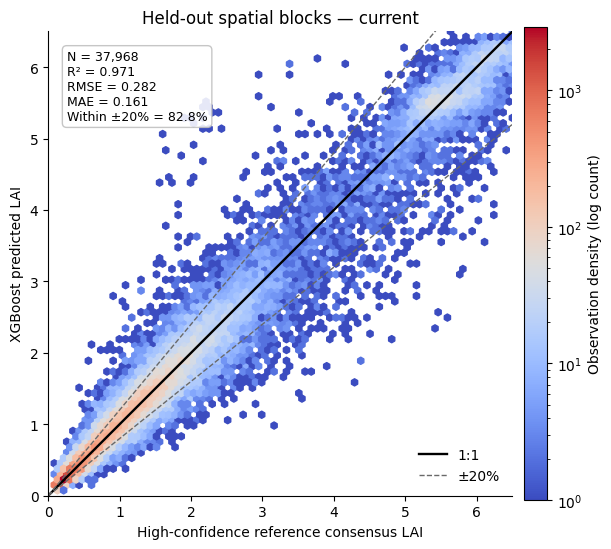


Saved density plot:
/content/drive/MyDrive/LAI_ML/revised/figures/finalResults/strict_sieve_xgboost_density_spatialBlock.png


In [ ]:
# Cell 12

from google.colab import drive
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from xgboost import XGBRegressor

import gc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shutil

drive.mount(
    "/content/drive",
    force_remount=False
)

revisedDir = Path(
    "/content/drive/MyDrive/LAI_ML/revised"
)

trainingDir = (
    revisedDir
    / "training"
)

modelDir = (
    revisedDir
    / "models"
)

figureDir = (
    revisedDir
    / "figures"
    / "finalResults"
)

modelDir.mkdir(
    parents=True,
    exist_ok=True
)

figureDir.mkdir(
    parents=True,
    exist_ok=True
)

modelSamplePath = (
    trainingDir
    / "lai_model_sample_10000_sites.parquet"
)

previousComparisonPath = (
    modelDir
    / "tuned_xgboost_comparison.csv"
)

sieveResultPath = (
    modelDir
    / "strict_sieve_search.csv"
)

strictComparisonPath = (
    modelDir
    / "strict_sieve_xgboost_comparison.csv"
)

strictPredictionPath = (
    modelDir
    / "strict_sieve_xgboost_predictions.parquet"
)

strictDensityPath = (
    figureDir
    / "strict_sieve_xgboost_density_spatialBlock.png"
)

randomSeed = 42

targetHoursUtc = [
    15,
    18,
    21
]

gpuAvailable = (
    shutil.which(
        "nvidia-smi"
    )
    is not None
)

xgboostDevice = (
    "cuda"
    if gpuAvailable
    else "cpu"
)

print(
    "XGBoost device:",
    xgboostDevice
)

modelData = pd.read_parquet(
    modelSamplePath
)

print(
    "Rows:",
    f"{len(modelData):,}"
)

print(
    "Sites:",
    f"{modelData['siteId'].nunique():,}"
)

brfFeatureColumns = []

for targetHourUtc in targetHoursUtc:

    brfFeatureColumns.extend(
        [
            f"brfBand2RedMeanHour{targetHourUtc}",
            f"brfBand2RedStdHour{targetHourUtc}",
            f"brfBand3NirMeanHour{targetHourUtc}",
            f"brfBand3NirStdHour{targetHourUtc}",
            f"brfBand5SwirMeanHour{targetHourUtc}",
            f"brfBand5SwirStdHour{targetHourUtc}"
        ]
    )

geometryFeatureColumns = [
    "viewZenithDeg",
    "viewAzimuthSin",
    "viewAzimuthCos",
    "dayOfYearSin",
    "dayOfYearCos"
]

for targetHourUtc in targetHoursUtc:

    geometryFeatureColumns.extend(
        [
            f"solarZenithDegMeanHour{targetHourUtc}",
            f"solarZenithDegStdHour{targetHourUtc}",
            f"solarAzimuthSinMeanHour{targetHourUtc}",
            f"solarAzimuthCosMeanHour{targetHourUtc}",
            f"relativeAzimuthSinMeanHour{targetHourUtc}",
            f"relativeAzimuthCosMeanHour{targetHourUtc}"
        ]
    )

igbpCategory = (
    modelData[
        "igbpClass"
    ]
    .astype(
        "Int16"
    )
    .astype(
        str
    )
)

landCoverFeatures = pd.get_dummies(
    igbpCategory,
    prefix="igbpClass",
    dtype=np.float32
)

for columnName in landCoverFeatures.columns:

    modelData[
        columnName
    ] = landCoverFeatures[
        columnName
    ]

landCoverFeatureColumns = (
    landCoverFeatures.columns.tolist()
)

featureColumns = (
    brfFeatureColumns
    + geometryFeatureColumns
    + landCoverFeatureColumns
)

featureMatrix = (
    modelData[
        featureColumns
    ]
    .to_numpy(
        np.float32
    )
)

targetValues = (
    modelData[
        "consensusLai"
    ]
    .to_numpy(
        np.float32
    )
)

qualityWeights = (
    modelData[
        "qualityWeight"
    ]
    .fillna(
        1.0
    )
    .to_numpy(
        np.float32
    )
)

modisSpreadPass075 = (
    modelData[
        "modisFamilySpread"
    ].isna()
    |
    (
        modelData[
            "modisFamilySpread"
        ]
        <= 0.75
    )
).to_numpy()

viirsSpreadPass075 = (
    modelData[
        "viirsFamilySpread"
    ].isna()
    |
    (
        modelData[
            "viirsFamilySpread"
        ]
        <= 0.75
    )
).to_numpy()

modisSpreadPass050 = (
    modelData[
        "modisFamilySpread"
    ].isna()
    |
    (
        modelData[
            "modisFamilySpread"
        ]
        <= 0.50
    )
).to_numpy()

viirsSpreadPass050 = (
    modelData[
        "viirsFamilySpread"
    ].isna()
    |
    (
        modelData[
            "viirsFamilySpread"
        ]
        <= 0.50
    )
).to_numpy()

baseMask = np.ones(
    len(
        modelData
    ),
    dtype=bool
)

highConfidence12Mask = (
    (
        modelData[
            "modisFamilyValidPixelCount"
        ]
        >= 12
    ).to_numpy()
    &
    (
        modelData[
            "viirsFamilyValidPixelCount"
        ]
        >= 12
    ).to_numpy()
    &
    (
        modelData[
            "familyDifference"
        ]
        <= 0.50
    ).to_numpy()
    &
    modisSpreadPass075
    &
    viirsSpreadPass075
    &
    (
        modelData[
            "availableHourCount"
        ]
        >= 2
    ).to_numpy()
)

highConfidence14Mask = (
    (
        modelData[
            "modisFamilyValidPixelCount"
        ]
        >= 14
    ).to_numpy()
    &
    (
        modelData[
            "viirsFamilyValidPixelCount"
        ]
        >= 14
    ).to_numpy()
    &
    (
        modelData[
            "familyDifference"
        ]
        <= 0.35
    ).to_numpy()
    &
    modisSpreadPass050
    &
    viirsSpreadPass050
    &
    (
        modelData[
            "availableHourCount"
        ]
        >= 2
    ).to_numpy()
)

veryStrictMask = (
    (
        modelData[
            "modisFamilyValidPixelCount"
        ]
        >= 14
    ).to_numpy()
    &
    (
        modelData[
            "viirsFamilyValidPixelCount"
        ]
        >= 14
    ).to_numpy()
    &
    (
        modelData[
            "familyDifference"
        ]
        <= 0.20
    ).to_numpy()
    &
    modisSpreadPass050
    &
    viirsSpreadPass050
    &
    (
        modelData[
            "availableHourCount"
        ]
        == 3
    ).to_numpy()
)

strictCountColumns = [
    f"strictObservationCountHour{targetHourUtc}"
    for targetHourUtc
    in targetHoursUtc
]

if all(
    columnName
    in modelData.columns
    for columnName
    in strictCountColumns
):

    for columnName in strictCountColumns:

        veryStrictMask &= (
            modelData[
                columnName
            ]
            >= 2
        ).to_numpy()

sieveMasks = {
    "current":
        baseMask,

    "highConfidence12":
        highConfidence12Mask,

    "highConfidence14":
        highConfidence14Mask,

    "veryStrict":
        veryStrictMask
}

outerSpatialTrainMask = (
    modelData[
        "spatialBlockSplit"
    ]
    == "train"
).to_numpy()

uniqueSpatialSites = (
    modelData.loc[
        outerSpatialTrainMask,
        [
            "siteId",
            "spatialBlock"
        ]
    ]
    .drop_duplicates(
        "siteId"
    )
)

innerSplitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=randomSeed
)

(
    innerTrainSiteIndex,
    innerValidationSiteIndex
) = next(
    innerSplitter.split(
        uniqueSpatialSites,
        groups=uniqueSpatialSites[
            "spatialBlock"
        ]
    )
)

innerTrainSites = set(
    uniqueSpatialSites.iloc[
        innerTrainSiteIndex
    ][
        "siteId"
    ]
)

innerValidationSites = set(
    uniqueSpatialSites.iloc[
        innerValidationSiteIndex
    ][
        "siteId"
    ]
)

innerTrainBaseMask = (
    outerSpatialTrainMask
    &
    modelData[
        "siteId"
    ].isin(
        innerTrainSites
    ).to_numpy()
)

innerValidationBaseMask = (
    outerSpatialTrainMask
    &
    modelData[
        "siteId"
    ].isin(
        innerValidationSites
    ).to_numpy()
)


def calculateMetrics(
    observedValues,
    predictedValues
):

    predictedValues = np.clip(
        predictedValues,
        0,
        10
    )

    rmse = float(
        np.sqrt(
            mean_squared_error(
                observedValues,
                predictedValues
            )
        )
    )

    mae = float(
        mean_absolute_error(
            observedValues,
            predictedValues
        )
    )

    r2 = float(
        r2_score(
            observedValues,
            predictedValues
        )
    )

    bias = float(
        np.mean(
            predictedValues
            - observedValues
        )
    )

    percentMask = (
        observedValues
        >= 1.0
    )

    if percentMask.sum() > 0:

        within20Rate = float(
            np.mean(
                np.abs(
                    predictedValues[
                        percentMask
                    ]
                    - observedValues[
                        percentMask
                    ]
                )
                <=
                0.20
                * observedValues[
                    percentMask
                ]
            )
        )

    else:

        within20Rate = np.nan

    highLaiMask = (
        observedValues
        >= 3.0
    )

    if highLaiMask.sum() > 0:

        highLaiRmse = float(
            np.sqrt(
                mean_squared_error(
                    observedValues[
                        highLaiMask
                    ],
                    predictedValues[
                        highLaiMask
                    ]
                )
            )
        )

        highLaiBias = float(
            np.mean(
                predictedValues[
                    highLaiMask
                ]
                - observedValues[
                    highLaiMask
                ]
            )
        )

    else:

        highLaiRmse = np.nan
        highLaiBias = np.nan

    return {
        "r2":
            r2,

        "rmse":
            rmse,

        "mae":
            mae,

        "bias":
            bias,

        "within20RateLaiGe1":
            within20Rate,

        "highLaiRmse":
            highLaiRmse,

        "highLaiBias":
            highLaiBias
    }


modelParameters = {
    "objective":
        "reg:squarederror",

    "n_estimators":
        1200,

    "learning_rate":
        0.03,

    "max_depth":
        9,

    "min_child_weight":
        6,

    "subsample":
        0.90,

    "colsample_bytree":
        0.90,

    "reg_alpha":
        0.05,

    "reg_lambda":
        2.5,

    "gamma":
        0.0,

    "tree_method":
        "hist",

    "device":
        xgboostDevice,

    "max_bin":
        256,

    "n_jobs":
        -1,

    "random_state":
        randomSeed,

    "eval_metric":
        "rmse",

    "early_stopping_rounds":
        40
}

print(
    "\nSTRICT-SIEVE SEARCH"
)

sieveRows = []

for (
    sieveName,
    sieveMask
) in sieveMasks.items():

    trainMask = (
        innerTrainBaseMask
        & sieveMask
    )

    validationMask = (
        innerValidationBaseMask
        & sieveMask
    )

    trainIndex = np.flatnonzero(
        trainMask
    )

    validationIndex = np.flatnonzero(
        validationMask
    )

    if (
        len(
            trainIndex
        )
        < 5000
        or len(
            validationIndex
        )
        < 2000
    ):

        print(
            sieveName,
            "| skipped — too few rows",
            len(
                trainIndex
            ),
            len(
                validationIndex
            )
        )

        continue

    model = XGBRegressor(
        **modelParameters
    )

    model.fit(
        featureMatrix[
            trainIndex
        ],
        targetValues[
            trainIndex
        ],
        sample_weight=qualityWeights[
            trainIndex
        ],
        eval_set=[
            (
                featureMatrix[
                    validationIndex
                ],
                targetValues[
                    validationIndex
                ]
            )
        ],
        verbose=False
    )

    predictions = model.predict(
        featureMatrix[
            validationIndex
        ]
    )

    metrics = calculateMetrics(
        targetValues[
            validationIndex
        ],
        predictions
    )

    validationTarget = (
        targetValues[
            validationIndex
        ]
    )

    highLaiRowCount = int(
        (
            validationTarget
            >= 3.0
        ).sum()
    )

    sieveRows.append(
        {
            "sieve":
                sieveName,

            "trainRows":
                len(
                    trainIndex
                ),

            "validationRows":
                len(
                    validationIndex
                ),

            "validationSites":
                int(
                    modelData.iloc[
                        validationIndex
                    ][
                        "siteId"
                    ].nunique()
                ),

            "meanReferenceLai":
                float(
                    validationTarget.mean()
                ),

            "highLaiRows":
                highLaiRowCount,

            "highLaiShare":
                float(
                    highLaiRowCount
                    / len(
                        validationTarget
                    )
                ),

            "bestTreeCount":
                int(
                    model.best_iteration
                    + 1
                ),

            **metrics
        }
    )

    print(
        sieveName,
        "| rows",
        f"{len(validationIndex):,}",
        "| R2",
        f"{metrics['r2']:.5f}",
        "| RMSE",
        f"{metrics['rmse']:.5f}",
        "| within20",
        f"{100 * metrics['within20RateLaiGe1']:.1f}%",
        "| mean LAI",
        f"{validationTarget.mean():.2f}",
        "| high-LAI",
        f"{100 * highLaiRowCount / len(validationTarget):.1f}%"
    )

    del (
        model,
        predictions
    )

    gc.collect()

sieveTable = (
    pd.DataFrame(
        sieveRows
    )
    .sort_values(
        [
            "r2",
            "rmse"
        ],
        ascending=[
            False,
            True
        ]
    )
)

sieveTable.to_csv(
    sieveResultPath,
    index=False
)

eligibleSieveTable = (
    sieveTable.loc[
        (
            sieveTable[
                "validationRows"
            ]
            >= 3000
        )
        &
        (
            sieveTable[
                "highLaiRows"
            ]
            >= 300
        )
    ]
)

if len(
    eligibleSieveTable
) == 0:

    eligibleSieveTable = (
        sieveTable
    )

bestSieveName = (
    eligibleSieveTable.iloc[
        0
    ][
        "sieve"
    ]
)

bestSieveMask = (
    sieveMasks[
        bestSieveName
    ]
)

bestTreeCount = int(
    eligibleSieveTable.iloc[
        0
    ][
        "bestTreeCount"
    ]
)

print(
    "\nBEST SIEVE:"
)

print(
    bestSieveName
)

print(
    "Trees:",
    bestTreeCount
)

finalParameters = (
    modelParameters.copy()
)

finalParameters.pop(
    "early_stopping_rounds"
)

finalParameters[
    "n_estimators"
] = bestTreeCount

validationSplits = {
    "unseenSite": (
        "unseenSiteSplit",
        "train",
        "test"
    ),

    "temporal2026": (
        "temporalSplit",
        "train",
        "test"
    ),

    "spatialBlock": (
        "spatialBlockSplit",
        "train",
        "test"
    )
}

comparisonRows = []
predictionTables = []

print(
    "\nFINAL STRICT-SIEVE VALIDATION"
)

for (
    validationName,
    (
        splitColumn,
        trainLabel,
        testLabel
    )
) in validationSplits.items():

    trainMask = (
        (
            modelData[
                splitColumn
            ]
            == trainLabel
        ).to_numpy()
        &
        bestSieveMask
    )

    testMask = (
        (
            modelData[
                splitColumn
            ]
            == testLabel
        ).to_numpy()
        &
        bestSieveMask
    )

    trainIndex = np.flatnonzero(
        trainMask
    )

    testIndex = np.flatnonzero(
        testMask
    )

    model = XGBRegressor(
        **finalParameters
    )

    model.fit(
        featureMatrix[
            trainIndex
        ],
        targetValues[
            trainIndex
        ],
        sample_weight=qualityWeights[
            trainIndex
        ]
    )

    predictions = np.clip(
        model.predict(
            featureMatrix[
                testIndex
            ]
        ),
        0,
        10
    ).astype(
        np.float32
    )

    metrics = calculateMetrics(
        targetValues[
            testIndex
        ],
        predictions
    )

    comparisonRows.append(
        {
            "validation":
                validationName,

            "sieve":
                bestSieveName,

            "trainRows":
                len(
                    trainIndex
                ),

            "testRows":
                len(
                    testIndex
                ),

            "testSites":
                int(
                    modelData.iloc[
                        testIndex
                    ][
                        "siteId"
                    ].nunique()
                ),

            "meanReferenceLai":
                float(
                    targetValues[
                        testIndex
                    ].mean()
                ),

            **metrics
        }
    )

    predictionTables.append(
        pd.DataFrame(
            {
                "siteId":
                    modelData.iloc[
                        testIndex
                    ][
                        "siteId"
                    ].to_numpy(),

                "periodStart":
                    modelData.iloc[
                        testIndex
                    ][
                        "periodStart"
                    ].to_numpy(),

                "validation":
                    validationName,

                "observedLai":
                    targetValues[
                        testIndex
                    ],

                "predictedLai":
                    predictions
            }
        )
    )

    print(
        validationName,
        "| rows",
        f"{len(testIndex):,}",
        "| R2",
        f"{metrics['r2']:.5f}",
        "| RMSE",
        f"{metrics['rmse']:.5f}",
        "| within20",
        f"{100 * metrics['within20RateLaiGe1']:.1f}%"
    )

    del model

    gc.collect()

strictComparison = pd.DataFrame(
    comparisonRows
)

strictComparison.to_csv(
    strictComparisonPath,
    index=False
)

strictPredictions = pd.concat(
    predictionTables,
    ignore_index=True
)

strictPredictions.to_parquet(
    strictPredictionPath,
    index=False,
    compression="zstd"
)

if previousComparisonPath.exists():

    previousComparison = pd.read_csv(
        previousComparisonPath
    )

    comparisonTable = (
        strictComparison.merge(
            previousComparison[
                [
                    "validation",
                    "r2",
                    "rmse"
                ]
            ].rename(
                columns={
                    "r2":
                        "fullDataR2",

                    "rmse":
                        "fullDataRmse"
                }
            ),
            on="validation",
            how="left"
        )
    )

    comparisonTable[
        "r2Difference"
    ] = (
        comparisonTable[
            "r2"
        ]
        - comparisonTable[
            "fullDataR2"
        ]
    )

    comparisonTable[
        "rmseDifference"
    ] = (
        comparisonTable[
            "rmse"
        ]
        - comparisonTable[
            "fullDataRmse"
        ]
    )

    print(
        "\nFULL DATA VS STRICT SIEVE"
    )

    print(
        comparisonTable[
            [
                "validation",
                "testRows",
                "fullDataR2",
                "r2",
                "r2Difference",
                "fullDataRmse",
                "rmse",
                "rmseDifference",
                "within20RateLaiGe1"
            ]
        ]
        .to_string(
            index=False
        )
    )

spatialPredictions = (
    strictPredictions.loc[
        strictPredictions[
            "validation"
        ]
        == "spatialBlock"
    ]
)

spatialMetrics = (
    strictComparison.loc[
        strictComparison[
            "validation"
        ]
        == "spatialBlock"
    ]
    .iloc[
        0
    ]
)

observedLai = (
    spatialPredictions[
        "observedLai"
    ]
    .to_numpy(
        float
    )
)

predictedLai = (
    spatialPredictions[
        "predictedLai"
    ]
    .to_numpy(
        float
    )
)

upperLimit = min(
    10.0,
    max(
        4.0,
        np.ceil(
            np.nanpercentile(
                np.concatenate(
                    [
                        observedLai,
                        predictedLai
                    ]
                ),
                99.7
            )
            * 2
        )
        / 2
    )
)

figure, axis = plt.subplots(
    figsize=(
        6.3,
        5.5
    )
)

densityPlot = axis.hexbin(
    observedLai,
    predictedLai,
    gridsize=75,
    extent=(
        0,
        upperLimit,
        0,
        upperLimit
    ),
    mincnt=1,
    bins="log",
    cmap="coolwarm"
)

referenceValues = np.linspace(
    0,
    upperLimit,
    300
)

axis.plot(
    referenceValues,
    referenceValues,
    color="black",
    linewidth=1.7,
    label="1:1"
)

axis.plot(
    referenceValues,
    1.20
    * referenceValues,
    color="dimgray",
    linestyle="--",
    linewidth=1.0,
    label="±20%"
)

axis.plot(
    referenceValues,
    0.80
    * referenceValues,
    color="dimgray",
    linestyle="--",
    linewidth=1.0
)

axis.set_xlim(
    0,
    upperLimit
)

axis.set_ylim(
    0,
    upperLimit
)

axis.set_aspect(
    "equal",
    adjustable="box"
)

axis.set_xlabel(
    "High-confidence reference consensus LAI"
)

axis.set_ylabel(
    "XGBoost predicted LAI"
)

axis.set_title(
    f"Held-out spatial blocks — {bestSieveName}"
)

axis.spines[
    "top"
].set_visible(
    False
)

axis.spines[
    "right"
].set_visible(
    False
)

metricText = (
    f"N = {len(spatialPredictions):,}\n"
    f"R² = {spatialMetrics['r2']:.3f}\n"
    f"RMSE = {spatialMetrics['rmse']:.3f}\n"
    f"MAE = {spatialMetrics['mae']:.3f}\n"
    f"Within ±20% = "
    f"{100 * spatialMetrics['within20RateLaiGe1']:.1f}%"
)

axis.text(
    0.04,
    0.96,
    metricText,
    transform=axis.transAxes,
    va="top",
    fontsize=9,
    bbox={
        "boxstyle":
            "round,pad=0.35",

        "facecolor":
            "white",

        "alpha":
            0.88,

        "edgecolor":
            "0.75"
    }
)

axis.legend(
    loc="lower right",
    frameon=False
)

colorBar = figure.colorbar(
    densityPlot,
    ax=axis,
    pad=0.02
)

colorBar.set_label(
    "Observation density (log count)"
)

figure.tight_layout()

figure.savefig(
    strictDensityPath,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "\nSaved density plot:"
)

print(
    strictDensityPath
)